## Kaggle T4 ×2 optimized edition (MPC-CLIP diffusion + spatial regions)

This version **splits the three frozen CLIP backbones** across the two Kaggle GPUs
rather than placing the entire surrogate ensemble on `cuda:0`:
`B16 + B32` on **GPU 0**, `Laion ViT-G/14` on **GPU 1**.
The image perturbation `delta`, concatenated CLIP features, global MPC objective,
regional losses, and final gradient stay on GPU 0. Transfers retain the autograd graph,
so GPU 1 contributes to the same adversarial update (not independent samples or DDP).

**Kaggle setup:** Accelerator → `GPU T4 x2`. Run cells in order, with Internet enabled
for first-run pretrained downloads. `GPU_SMOKE=True` enables a small, download-free
cross-GPU autograd parity test. `NUM_SAMPLES=1` is a debugging setting: increase it
for the real experiment. The existing 300 steps, diffusion settings, masks, saved artifacts and
numerical FP32 CLIP objective have not been changed. The victim caption
precision/protocol does change from BF16 to FP16 to support T4.

Victim captioning is also **sharded across both GPUs** via `device_map='balanced'`
with `float16` (T4 compatible). The original BF16 victim caption protocol is
therefore **changed intentionally**; cached captions cannot be mixed between
these two precision protocols. Captions are generated before diffusion and CLIP.

`SAVED_TENSORS_ON_CPU=True` remains the safe T4 default, but only offloads
**GPU 1 ViT-G activations** (`SAVED_TENSORS_CPU_DEVICES=('cuda:1',)`) to avoid
unnecessary CPU transfers for GPU 0's smaller CLIP models. Benchmark `False` only when
GPU memory headroom has been verified; it may be faster but is more likely to OOM.
Qwen attention is not used by the locked `mpc_clip_diffusion` variant. If enabling
other variants in an exploratory branch, account for GPU 1 shared memory with Qwen
and restore single-GPU placement for FOA/OT reference paths.

**Limits:** This file was statically checked and includes a synthetic GPU test, but
large pretrained weight loading, actual two-GPU performance, and Kaggle runtime
compatibility still require an on-Kaggle smoke test. Speedup is not guaranteed,
especially where CPU offload, per-step logging, and regional forwards dominate.

---

# MPC-CLIP diffusion: spatial concept correspondence hypothesis

Isolated experiment. The original `mpc_clip_diffusion.ipynb` and helpers remain
unchanged. Default img2img strength is **0.7**. The reported 80% ASR motivates
this hypothesis; it is not a measured result of this new regional objective.

1. Freeze the selected victim's source and original-target captions, exactly as
   in the diffusion baseline. Generate the target from source + target caption.
2. Extract foreground noun phrases from these frozen captions with the same
   victim using a separate JSON prompt. Preserve exact caption spans and raw
   responses. No new target caption enters generation, global anchors or scoring.
3. Ground phrases with Grounding DINO **on the source and generated target**.
   SAM supplies masks. Both models run on the exact 224px attack-preprocessed
   images, then unload before CLIP. Multiple instances of a concept form one
   union box and union mask (for example, two alligators).
4. For each source concept, independently choose the target box with maximum
   IoU. Accept only IoU >= `REGION_MIN_IOU`; target reuse permits many-to-one.
   Matching does not require similar concept names: fish can match crocodile.
5. Compute the ordinary global MPC objective plus losses on fixed regions.
   Region geometry, masks and detached anchors never change during optimization.

| Correspondence | Regional treatment |
| --- | --- |
| Reliable object overlap | Attract target crop/concept; repel source crop/concept |
| Several sources share one target | Retain each source pair; average over source regions |
| No object match; reliable target background in source box | Attract masked target background crop at the same coordinates; repel source |
| No reliable match | Repel frozen source region/concept anchor only |
| Same extracted concept on both sides | Target attraction only |
| Source concept cannot be localized | Abstain; record it as unlocalized |

Object/background replacement loss is
`softplus((cos(adv_region, source_anchor) - cos(adv_region, target_anchor)) / tau)`.
Every anchor reuses the original per-backbone fusion:
`FUSION_LAMBDA * CLIP_vision + (1 - FUSION_LAMBDA) * CLIP_text`
(default 0.6/0.4), concatenated across backbones before cosine similarity.
Object anchors use concept phrases. Background anchors use background phrases
extracted verbatim from the frozen caption, or the neutral text "background"
when the caption contains none. The target foreground negative uses its grounded
concept phrases. Adversarial features remain image-only, as in original MPC.
Suppression minimizes similarity to the fused source anchor.

Background is the complement of the union of caption-conditioned SAM masks.
The background loss uses the **intersection of source and target backgrounds**
as a common spatial mask on adv and target. Target foreground is its contrastive
negative. Fixed gray fill prevents gradients outside the mask. Background loss
is skipped when either caption has unlocalized concepts, no foreground concepts,
or insufficient foreground/background area. A target background fallback also
requires all target concepts to be localized and sufficient background coverage.
These are estimated masks: unmentioned or missed objects can remain.

The maximized objective is
`J = J_global - REGION_WEIGHT * L_regions - REGION_BACKGROUND_WEIGHT * L_background`.
Losses are averaged over valid source regions. Separate backward passes avoid
keeping all regional CLIP graphs alive simultaneously. The original projection,
momentum, crop RNG, perturbation budget and evaluation captions stay unchanged.
Fixed regions do not use the global random crop coordinates.

### Run, inspect and ablate

Use a fresh CUDA notebook kernel. Configure dataset paths, then run setup and
the attack as in the diffusion baseline. This notebook embeds all required code.
Grounding DINO and SAM add pretrained downloads and preparation cost; concept
extraction temporarily loads the selected victim again when its cache is absent.
Regional CLIP passes increase attack cost.

Set `REGION_ENABLED=False` for a global-only control at the same diffusion
strength. Set `REGION_BACKGROUND_WEIGHT=0` for the foreground-only ablation.
Thresholds and weights are initial experimental choices, not validated optima.
Attention diversion is not included in this hypothesis.

Before interpreting ASR, inspect `regions/<sample>/regions.json`,
`source_boxes.png`, `target_boxes.png`, and the two background masks. Exact
matches, IoUs, missing concepts, raw extraction responses and artifact hashes
are saved. A final preview cell displays the first sample. Per-step traces add
regional/background losses and active pair counts. Use a new run when changing
configuration or code. Existing completed outputs and frozen caches are verified
on resume. Missing regions after attack starts are an error.

The original target image and frozen victim captions remain the evaluation
references. A caption saying "Nile crocodile" stays that phrase even if the
generated picture looks like alligators; grounding must locate that phrase or
abstain. Img2img does not guarantee spatial preservation, so inspect the matches.

Implementation APIs: [Grounding DINO](https://huggingface.co/docs/transformers/v4.57.1/model_doc/grounding-dino)
and [SAM](https://huggingface.co/docs/transformers/v4.57.1/model_doc/sam).


### Dataset + safety-filter fix (v7)

- Add the Kaggle dataset **zintom/blackbox-adversarial-attack-dataset** via **Add Input**. Both Kaggle paths
  (`/kaggle/input/blackbox-adversarial-attack-dataset` and
  `/kaggle/input/datasets/zintom/blackbox-adversarial-attack-dataset`) are supported.
  The loader uses the existing `bigscale`/`target_images` ImageFolder pairing, and now reports the chosen folders and sample count.
- On a filtered diffusion image, retry **up to 5 times** with deterministic distinct seeds.
  Never accept a safety-filtered black image.
- If all attempts fail, the default `DIFFUSION_FILTERED_POLICY='original_target'`
  uses the original dataset target **and labels it as a fallback**. This lets the
  attack pipeline continue but that sample **is not evidence for a diffusion-target
  ablation**. Set policy to `'error'` for strictly diffusion-only runs.
- Audit each generated/fallback target via `diffusion_targets/<id>/generation.json`,
  and see aggregate results in `diffusion_generation_audit.json`.
- Start with `NUM_SAMPLES=1`; set `NUM_SAMPLES=None` for the full dataset after verifying
  paths and GPU memory. Run with Kaggle **GPU T4 ×2** and Internet enabled on first use.

**Execution caveat:** 2-GPU model partitioning and all downstream pretrained models still
require validation on Kaggle itself; local tests here do not exercise Kaggle CUDA/models.


In [1]:
# Cell 1 — User configuration. All budgets below use pixel units [0,255].
from pathlib import Path

# Kaggle may expose an attached Dataset at either of the two mount styles.
# If the configured path is absent, discover_dir() also checks the other style.
DATASET_ROOT = Path('/kaggle/input/datasets/zintom/blackbox-adversarial-attack-dataset')
WORK_ROOT = Path('/kaggle/working')
OUTPUT_ROOT = WORK_ROOT / 'mpc_clip_diffusion_regions_outputs'
SOURCE_DIR = None
TARGET_DIR = None
PAIR_MANIFEST = None  # Previous attack manifest; source/target paths relative to its parent.
NUM_SAMPLES = 1
SAMPLE_START = 0
RUN_ATTACK = True  # Set False for setup/preflight-only run
INSTALL_DEPENDENCIES = True  # Installs for RUN_ATTACK or SETUP_ONLY; fresh kernel required.
SETUP_ONLY = False  # True: install pinned packages without downloading pretrained weights.
RUN_SELF_CHECKS = True
GPU_SMOKE = False  # Tiny synthetic encoders only; no model download.

RESUME_RUN_DIR = None
RUN_VARIANTS = ['mpc_clip_diffusion']
SEED = 2023
ATTACK_DEVICE = 'cuda:0'      # Delta, global objective and aggregation / final gradient.
ATTENTION_DEVICE = 'cuda:1'   # Only used when Qwen attention is explicitly enabled.
CAPTION_DEVICE = 'cuda:0'     # Processor input entrypoint for HF device-dispatched model.
CAPTION_DTYPE = 'float16'      # T4 does NOT have native bfloat16 support.
CAPTION_DEVICE_MAP = 'balanced'  # HF Accelerate splits unquantized 7B/8B across both GPUs.

BACKBONES = ('B16', 'B32', 'Laion')
# TRUE two-GPU model parallelism for the frozen MPC-CLIP ensemble.
# B16/B32 run on GPU 0, large LAION ViT-G on GPU 1. Small feature tensors
# return to GPU 0; autograd sends gradient back to GPU 1 automatically.
# Do not use DataParallel: the batch is a single adversarial image.
CLIP_DEVICE_MAP = {'B16': 'cuda:0', 'B32': 'cuda:0', 'Laion': 'cuda:1'}
# Keep CPU activation offload ON for T4 16 GB reliability. Setting it False
# can be faster with enough *measured* free VRAM, but may cause CUDA OOM.

INPUT_RES = 224
STEPS = 300
EPSILON_255 = 16.0
ALPHA_255 = 1.0
CLUSTER_NUMBER = 10
PAPER_INPUT_RES = INPUT_RES
PAPER_CROP_SCALE = (0.5, 0.9)
USE_SOURCE_CROP = True
USE_TARGET_CROP = True
FUSION_LAMBDA = 0.6
TEMPERATURE = 0.2
POSITIVE_OMEGA = 2.0
MPC_MOMENTUM = 0.9
HYBRID_MOMENTUM = 0.0
LOSS_WEIGHTS = {'foa': 1.0, 'mpc': 1.0, 'negative': 0.5}
NEGATIVE_LOSS = 'infonce'  # infonce | margin | hard_margin | repulsion
NEGATIVE_TEMPERATURE = 0.2
NEGATIVE_MARGIN = 0.2
K_NEG = 2
MAX_NEGATIVES = 12
MINE_EVERY = 10
REFRESH_EVERY = 30
NUM_PHASES = 10
HOTSPOT_TOP_K = 3
HOTSPOT_IOU = 0.3
HOTSPOT_PROB = 1.0  # v3.2 uses the always-hotspot crop primitive.
ATTENTION_MODEL_ID = 'Qwen/Qwen3-VL-8B-Instruct'
ATTENTION_REVISION = 'main'  # Resolved once to immutable SHA; restored on resume.
ATTENTION_LAYER = 29
ATTENTION_INPUT_RES = 448
ATTENTION_PROMPT = 'Describe this image, no longer than 25 words.'
MAX_CONCEPT_TOKENS = 128
CONTENT_WORDS_ONLY = True
# Select the victim being evaluated. Use a separate run for each victim.
VICTIM_MODELS = {
    'llava_v1.5_7b': 'llava-hf/llava-1.5-7b-hf',
    'InternVL3-8B': 'OpenGVLab/InternVL3-8B-hf',
    'Qwen3-VL-8B-Instruct': 'Qwen/Qwen3-VL-8B-Instruct',
}
VICTIM_MODEL = 'Qwen3-VL-8B-Instruct'
CAPTION_MODEL_ID = VICTIM_MODELS[VICTIM_MODEL]
VICTIM_CAPTION_PROMPT = 'Describe this image in one concise sentence, no longer than 20 words.'
MODEL_REVISION = 'main'
TEXT_RETRIES = 3
CONCEPT_MAX_NEW_TOKENS = 1024
MANUAL_TEXT_OVERRIDES = {}  # {'00000': {'source': '...', 'target': '...', 'negatives': [...]}}
HYBRID_AMP = False  # Stable FP32 default for dynamic. Optional AMP has logged FP32 fallback.
GRADIENT_SCALE = 1.0  # No manual FP16 amplification by default; 1024 triggered overflow risk.
HYBRID_AMP_FP32_RETRY = True  # Only hybrid; restore FOA history + RNG before a retry.
MPC_FAST_MODE = True  # False restores the original execution path.
SAVED_TENSORS_ON_CPU = True  # Explicit activation offload; unchanged model/dtype/objective.
# Offload *only* Laion/GPU1 activations. GPU0 holds small B16/B32 and has
# room to keep their activations resident, avoiding expensive CPU PCIe copies.
SAVED_TENSORS_CPU_DEVICES = ('cuda:1',)

OFFLOAD_CLIP_DURING_QWEN = True  # Release GPU 0 between attention refreshes when needed.
LOG_EVERY = 10  # Keep machine-readable steps/events trace every 10 updates.
SHOW_ATTACK_PROGRESS = True  # v3.2-style live tqdm bar; display-only (not part of experiment identity).
SAVE_EVERY = 30
CONTINUE_ON_SAMPLE_ERROR = True  # Stateful references stop their variant at first attack error.
EXPORT_ZIP = True

VARIANTS = {
    'foa_reference': dict(foa=True, mpc=False, negatives='none', region='none', full_mpc=False, reference=True),
    'mpc_clip': dict(foa=False, mpc=True, negatives='none', region='none', full_mpc=False, reference=False),
    'mpc_full_reference': dict(foa=False, mpc=True, negatives='none', region='none', full_mpc=True, reference=True),
    'hybrid_plain': dict(foa=True, mpc=True, negatives='none', region='none', full_mpc=False, reference=False),
    'hybrid_negative': dict(foa=True, mpc=True, negatives='hard', region='none', full_mpc=False, reference=False),
    'hybrid_fixed': dict(foa=True, mpc=True, negatives='hard', region='fixed', full_mpc=False, reference=False),
    'hybrid_dynamic': dict(foa=True, mpc=True, negatives='hard', region='dynamic', full_mpc=False, reference=False),
    'hybrid_random_region': dict(foa=True, mpc=True, negatives='hard', region='random', full_mpc=False, reference=False),
    'hybrid_random_neg': dict(foa=True, mpc=True, negatives='random', region='dynamic', full_mpc=False, reference=False),
}

# Diffusion target preparation; settings match the supplied Colab except fixed strength.
DIFFUSION_MODEL_ID = 'stable-diffusion-v1-5/stable-diffusion-v1-5'
DIFFUSION_STRENGTH = 0.7
DIFFUSION_GUIDANCE_SCALE = 7.5
DIFFUSION_STEPS = 40
DIFFUSION_SEED = 3
DIFFUSION_MAX_SIDE = 512
DIFFUSION_DEVICE = ATTACK_DEVICE
# On some photographs the Stable Diffusion safety checker filters an output.
# Never use the returned black image; retry deterministic alternate seeds.
DIFFUSION_MAX_ATTEMPTS = 5
DIFFUSION_RETRY_SEED_STRIDE = 1009
# 'original_target': use dataset target ONLY after all seeds fail (labeled in metadata).
# 'error': stop instead, enforcing a diffusion-only experimental protocol.
DIFFUSION_FILTERED_POLICY = 'original_target'
# Persistent across run directories. On ephemeral hosts, point this at mounted storage
# or download and restore this folder before the next session.
CAPTION_CACHE_DIR = WORK_ROOT / 'mpc_clip_diffusion_caption_cache'
# Optional text_records.json from a victim-aware run with matching images/protocol.
# None automatically reuses CAPTION_CACHE_DIR or generates missing victim captions.
CAPTION_RECORDS_PATH = None
VARIANTS['mpc_clip_diffusion'] = dict(VARIANTS['mpc_clip'])

# Spatial-correspondence hypothesis. False is the global-only control.
REGION_ENABLED = True
REGION_DETECTOR_ID = 'IDEA-Research/grounding-dino-tiny'
REGION_SEGMENTER_ID = 'facebook/sam-vit-base'
REGION_BOX_THRESHOLD = 0.30
REGION_TEXT_THRESHOLD = 0.25
REGION_MASK_QUALITY = 0.80
REGION_MIN_IOU = 0.20
REGION_BACKGROUND_FRACTION = 0.80
REGION_MIN_MASK_FRACTION = 0.02
REGION_TEMPERATURE = 0.10
REGION_WEIGHT = 1.0
REGION_BACKGROUND_WEIGHT = 0.25

def validate_configuration():
    if type(REGION_ENABLED) is not bool:
        raise ValueError('REGION_ENABLED must be boolean.')
    for name in ('REGION_BOX_THRESHOLD', 'REGION_TEXT_THRESHOLD', 'REGION_MASK_QUALITY',
                 'REGION_MIN_IOU', 'REGION_BACKGROUND_FRACTION', 'REGION_MIN_MASK_FRACTION'):
        value = globals()[name]
        if isinstance(value, bool) or not isinstance(value, (int, float)) or not 0 < value <= 1:
            raise ValueError(f'{name} must be in (0, 1].')
    if not 0 < REGION_TEMPERATURE < float('inf'):
        raise ValueError('REGION_TEMPERATURE must be finite and positive.')
    if any(not 0 <= value < float('inf') for value in (REGION_WEIGHT, REGION_BACKGROUND_WEIGHT)):
        raise ValueError('Regional weights must be finite and nonnegative.')
    if CAPTION_DTYPE not in {'float16', 'bfloat16'} or CAPTION_DEVICE_MAP != 'balanced':
        raise ValueError('T4 edition expects CAPTION_DEVICE_MAP=balanced and float16/bfloat16 precision.')
    if VICTIM_MODEL not in VICTIM_MODELS or CAPTION_MODEL_ID != VICTIM_MODELS[VICTIM_MODEL]:
        raise ValueError('Select a supported victim before running the configuration cell.')
    if MANUAL_TEXT_OVERRIDES:
        raise ValueError('Captions must come from the selected victim; import its saved caption records instead.')
    if RUN_VARIANTS != ['mpc_clip_diffusion']:
        raise ValueError('This separate notebook runs only mpc_clip_diffusion.')
    if type(MPC_FAST_MODE) is not bool or type(SAVED_TENSORS_ON_CPU) is not bool:
        raise ValueError('MPC_FAST_MODE and SAVED_TENSORS_ON_CPU must be boolean.')
    if (not isinstance(SAVED_TENSORS_CPU_DEVICES, (tuple, list)) or
            any(v not in CLIP_DEVICE_MAP.values() for v in SAVED_TENSORS_CPU_DEVICES)):
        raise ValueError('SAVED_TENSORS_CPU_DEVICES must contain valid CLIP GPU devices.')
    if not isinstance(DIFFUSION_STRENGTH, (int, float)) or isinstance(DIFFUSION_STRENGTH, bool) or not 0 < DIFFUSION_STRENGTH <= 1:
        raise ValueError('Diffusion strength must be in (0, 1].')
    if type(DIFFUSION_STEPS) is not int or DIFFUSION_STEPS < 1 or int(DIFFUSION_STEPS * DIFFUSION_STRENGTH) < 1:
        raise ValueError('Diffusion needs at least one denoising step at the selected strength.')
    if type(DIFFUSION_SEED) is not int or not 0 <= DIFFUSION_SEED < 2**63:
        raise ValueError('Invalid diffusion seed.')
    if type(DIFFUSION_MAX_ATTEMPTS) is not int or not 1 <= DIFFUSION_MAX_ATTEMPTS <= 50:
        raise ValueError('DIFFUSION_MAX_ATTEMPTS must be 1..50.')
    if type(DIFFUSION_RETRY_SEED_STRIDE) is not int or DIFFUSION_RETRY_SEED_STRIDE < 1:
        raise ValueError('DIFFUSION_RETRY_SEED_STRIDE must be a positive integer.')
    if DIFFUSION_SEED + (DIFFUSION_MAX_ATTEMPTS - 1) * DIFFUSION_RETRY_SEED_STRIDE >= 2**63:
        raise ValueError('Diffusion retry seeds exceed torch.Generator range.')
    if DIFFUSION_FILTERED_POLICY not in {'error', 'original_target'}:
        raise ValueError('Invalid DIFFUSION_FILTERED_POLICY.')
    if type(DIFFUSION_MAX_SIDE) is not int or DIFFUSION_MAX_SIDE < 64:
        raise ValueError('Diffusion max side must be an integer >= 64.')
    if not 0 <= DIFFUSION_GUIDANCE_SCALE < float('inf'):
        raise ValueError('Diffusion guidance must be finite and nonnegative.')
    if not RUN_VARIANTS or len(set(RUN_VARIANTS)) != len(RUN_VARIANTS) or set(RUN_VARIANTS) - VARIANTS.keys():
        raise ValueError('Select unique known RUN_VARIANTS.')
    if tuple(BACKBONES) != ('B16', 'B32', 'Laion'):
        raise ValueError('v4.3 locks the requested three-model ensemble; edit and relabel an ablation explicitly.')
    if not isinstance(CLIP_DEVICE_MAP, dict) or set(CLIP_DEVICE_MAP) != set(BACKBONES):
        raise ValueError('CLIP_DEVICE_MAP must specify each of B16, B32 and Laion.')
    if any(not isinstance(CLIP_DEVICE_MAP[name], str) or
           not CLIP_DEVICE_MAP[name].startswith('cuda:') or not CLIP_DEVICE_MAP[name][5:].isdigit() for name in BACKBONES):
        raise ValueError('All CLIP_DEVICE_MAP entries must be explicit cuda:N strings.')

    for name in ('STEPS', 'INPUT_RES', 'K_NEG', 'MAX_NEGATIVES', 'MINE_EVERY', 'REFRESH_EVERY', 'NUM_PHASES', 'HOTSPOT_TOP_K', 'TEXT_RETRIES', 'LOG_EVERY', 'SAVE_EVERY'):
        if type(globals()[name]) is not int or globals()[name] < 1:
            raise ValueError(f'{name} must be a positive integer.')
    if type(SAMPLE_START) is not int or SAMPLE_START < 0 or (NUM_SAMPLES is not None and (type(NUM_SAMPLES) is not int or NUM_SAMPLES < 1)):
        raise ValueError('Invalid sample selection.')
    if INPUT_RES != 224 or CLUSTER_NUMBER != 10 or not 1 <= K_NEG <= MAX_NEGATIVES <= 12:
        raise ValueError('Expected resolution=224, K=10 and 1 <= k_neg <= bank_size <= 12.')
    if NEGATIVE_LOSS not in {'infonce', 'margin', 'hard_margin', 'repulsion'}:
        raise ValueError('Unknown negative loss.')
    if not 0 <= EPSILON_255 <= 255 or ALPHA_255 <= 0 or min(TEMPERATURE, NEGATIVE_TEMPERATURE, GRADIENT_SCALE) <= 0:
        raise ValueError('Invalid budget/temperature/gradient scale.')
    if not 0 <= FUSION_LAMBDA <= 1 or not 0 <= HOTSPOT_IOU <= 1 or not 0 <= HOTSPOT_PROB <= 1:
        raise ValueError('Invalid fusion/hotspot parameters.')
    if set(LOSS_WEIGHTS) != {'foa', 'mpc', 'negative'} or any(v < 0 for v in LOSS_WEIGHTS.values()):
        raise ValueError('Loss weights must have foa/mpc/negative nonnegative entries.')
    if not 0 <= MPC_MOMENTUM < 1 or not 0 <= HYBRID_MOMENTUM < 1:
        raise ValueError('Invalid momentum.')
    if any(VARIANTS[v]['region'] != 'none' for v in RUN_VARIANTS) and STEPS < NUM_PHASES * HOTSPOT_TOP_K:
        raise ValueError('Region sequencing needs at least NUM_PHASES * HOTSPOT_TOP_K updates.')

validate_configuration()

In [2]:
# Cell 2 — A single pinned runtime; preflight never pip-installs or downloads weights.
import ast, base64, contextlib, gc, hashlib, inspect, io, json, math, os, random, re
import shutil, string, subprocess, sys, threading, time, traceback
from abc import abstractmethod
from contextlib import contextmanager
from datetime import datetime, timezone
from functools import partial
from importlib import metadata as package_metadata
from types import SimpleNamespace
from typing import Any, Dict, List, Optional, Sequence

PINNED_PACKAGES = [
    'transformers==4.57.1', 'tokenizers==0.22.1', 'huggingface-hub==0.34.4',
    'diffusers==0.35.1', 'safetensors==0.6.2', 'accelerate==1.11.0', 'bitsandbytes==0.48.1', 'ftfy==6.3.1',
    'tqdm==4.67.1', 'loguru==0.7.3', 'sentencepiece==0.2.1',
]
if (RUN_ATTACK or SETUP_ONLY) and INSTALL_DEPENDENCIES:
    if any(p in sys.modules for p in ('transformers', 'tokenizers')):
        raise RuntimeError('Restart kernel before installing pinned packages, or disable INSTALL_DEPENDENCIES.')
    WORK_ROOT.mkdir(parents=True, exist_ok=True)
    with (WORK_ROOT / 'v43_setup.log').open('w', encoding='utf-8') as stream:
        result = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *PINNED_PACKAGES], stdout=stream, stderr=subprocess.STDOUT)
    if result.returncode:
        raise RuntimeError(f'Setup failed; read {WORK_ROOT / "v43_setup.log"}.')

# Keep Torch/Torchvision supplied by Kaggle. K-means is embedded, not pip-resolved.
import numpy as np
import torch
import torch.nn.functional as F
import torchvision
from PIL import Image
from torch import Tensor, nn
from torchvision import datasets, transforms
from torchvision.transforms import functional as TF
from tqdm.auto import tqdm
try:
    from loguru import logger
    logger.remove()  # Only progress bar + warnings/errors in notebook output.
    logger.add(sys.stderr, level='WARNING')
except ImportError:
    import logging
    logger = logging.getLogger('v43_attention')
    logger.setLevel(logging.WARNING)
import transformers
if transformers.__version__ != '4.57.1':
    raise RuntimeError('This notebook requires transformers==4.57.1. In a fresh kernel set SETUP_ONLY=True and INSTALL_DEPENDENCIES=True; keep RUN_ATTACK=False for setup/preflight.')
from transformers import (
    AutoConfig, AutoProcessor, AutoTokenizer, AutoModel, AutoModelForImageTextToText,
    BitsAndBytesConfig, CLIPModel as HFCLIPModel, CLIPProcessor,
)
from huggingface_hub import HfApi

BUILD_CELL_HASHES = {'cell_3': 'f7b7b015475bbc85b5d3f3c4aa05d88b07de3bfe99258751e51d1d04fa24c2a0', 'cell_4': 'f8d5c835c914242c30a5ce14108ee1976a6da1f9871aec6ef21ed3af89bd1470', 'cell_5': '2fbb960678b231828c862cee6d6cfc140840a9b34999775b6f667e4c1226774b', 'cell_6': 'cd87903db85ad8a932e6648d306e797b7c6a7e358c93f052dbe3f09aaef2b753', 'cell_7': '52f820a54ad9261141dbe76aef065a10eb429467ab7fe26a0b3e2754ac1f12ad', 'cell_8': 'c29325ca01659ec65138b33e001d470208470b637c77b4a1e51ba8210d0b9c0e', 'cell_9': 'e720a909b6ab5e6d4f2d8a4264b2254b8060d8af47ac57da979f35b467c43318', 'cell_10': 'a209848650bbe9d5f4c7b8bcc8dd4c2f861a5cc1e2bc2ab3917715425dc07374', 'cell_11': '045158de0c7ddf7fc1f3d9807c57a6eeb7ae057af58fea369825bf4c85906f84', 'cell_12': '47f43d57d71c2d8be5f4d6651fff5382b1763ca46949d09dc641c4d61ba9042a', 'cell_13': '81c90ec549b25a2ee70b1b747f954066a061775455984f82e3136fc3af8faf55', 'cell_14': '3af8b9ea0106cd939e93403b50f45c5735d1e1662c0aa2e2ce3152258518b2fb', 'cell_15': '8daec5c896ed30dba14924c7af2dd11d3224b0443e50e4b62d0610978af62e63', 'cell_16': '34c8285753d47b35614c2a23de6e1b3cfb3645a34c8780979bed87f3834f06d4', 'cell_17': 'b29e2949e0338c3f83210726d52acbc6b242929182be69f744d56db54d86a4d3'}
BUILD_CELL_FIRST_LINES = {'UPSTREAM = {}': 'cell_3', '# Cell 3 — Compile pinned author definitions into isolated namespaces, without imports/entrypoints.': 'cell_4', '# FOA: exact author definitions. Edit experimental behavior in the hybrid cells.': 'cell_5', "# Cell 5 — Author model adapters share CLIP weights, but keep each method's own preprocessing.": 'cell_6', '# Cell 6 — Pair once, export evaluation-compatible PNGs and JSON checkpoints.': 'cell_7', '# Cell 7 — Editable objectives. Scores are maximized; negative losses are minimized.': 'cell_8', '# Cell 8 — Cache InternVL captions and image-conditioned Qwen counterfactuals.': 'cell_9', '"""Fixed-area hotspot ranking with the original IoU fallback."""': 'cell_10', 'DEBUG = os.environ.get("DEBUG", "0") == "1"': 'cell_11', '# Cell 11 — Reference-preserving update order and editable hybrid orchestration.': 'cell_12', '# Cell 12 — Meaningful checks, no pretrained weights or remote model calls.': 'cell_13', '# Victim caption adapter from evaluate_molab_v33_mpc.py; selected device and pinned revision.': 'cell_14', '# Cell 13 — Preflight, immutable run identity, per-variant manifests and boundary resume.': 'cell_15', '# Cell 14 — Artifact-only preview and partial export after interruption.': 'cell_16', '# Regional correspondence review: generated target, boxes, masks and assignments.': 'cell_17'}
RUN_DIR = None
MODEL_REVISIONS = {}
MODEL_METADATA = {}
MODEL_STORE = {}
ATTENTION_BACKEND = None

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def json_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False, default=str).encode()).hexdigest()

def write_json(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    pending = path.with_suffix(path.suffix + '.tmp')
    pending.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False, default=str) + '\n', encoding='utf-8')
    pending.replace(path)

def append_jsonl(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    with path.open('a', encoding='utf-8') as stream:
        stream.write(json.dumps(value, ensure_ascii=False, allow_nan=False, default=str) + '\n')
        stream.flush()

def runtime_code_hashes():
    # In IPython, hash executed cells, so edits to a function invalidate resume.
    try:
        history = get_ipython().history_manager.input_hist_raw
    except (NameError, AttributeError):
        return BUILD_CELL_HASHES
    latest = dict(BUILD_CELL_HASHES)
    for source in history:
        first = source.strip().splitlines()[0] if source.strip() else ''
        name = BUILD_CELL_FIRST_LINES.get(first)
        if name is not None:
            latest[name] = hashlib.sha256(source.strip().encode()).hexdigest()
    return latest

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

@contextlib.contextmanager
def preserve_rng():
    state = capture_rng()
    try:
        yield
    finally:
        restore_rng(state)

def capture_rng():
    np_state = np.random.get_state()
    return {'python': random.getstate(),
            'numpy': [np_state[0], np_state[1].tolist(), int(np_state[2]), int(np_state[3]), float(np_state[4])],
            'torch': torch.get_rng_state().tolist(),
            'cuda': [s.tolist() for s in torch.cuda.get_rng_state_all()] if torch.cuda.is_available() else []}

def restore_rng(state):
    def tuples(value):
        return tuple(tuples(v) for v in value) if isinstance(value, (tuple, list)) else value
    random.setstate(tuples(state['python']))
    p = state['numpy']; np.random.set_state((p[0], np.asarray(p[1], dtype=np.uint32), p[2], p[3], p[4]))
    torch.set_rng_state(torch.tensor(state['torch'], dtype=torch.uint8))
    if state['cuda']:
        if len(state['cuda']) != torch.cuda.device_count():
            raise RuntimeError('Resume requires the same visible CUDA device count.')
        torch.cuda.set_rng_state_all([torch.tensor(s, dtype=torch.uint8) for s in state['cuda']])

def event(stage, action, **fields):
    row = {'utc': datetime.now(timezone.utc).isoformat(), 'stage': stage, 'action': action, **fields}
    if RUN_DIR is not None:
        append_jsonl(RUN_DIR / 'events.jsonl', row)
    # Events are ALWAYS saved, but frequent/internal events do not flood Kaggle output.
    if (stage, action) in {('attack', 'progress'), ('text', 'captions_cached'),
                           ('text', 'negative_bank_cached'), ('resume', 'skip_complete')} and SHOW_ATTACK_PROGRESS:
        return
    if (stage, action) == ('attack', 'sample_start') and SHOW_ATTACK_PROGRESS:
        print(f"Sample {fields.get('position', '?')}/{fields.get('total', '?')} | "
              f"variant={fields['variant']} | id={fields['sample_id']}")
        return
    print(f'[{stage}] {action}', ' '.join(f'{k}={v}' for k, v in fields.items()))

def cuda_cleanup():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def saved_tensor_context():
    return torch.autograd.graph.save_on_cpu(pin_memory=True) if SAVED_TENSORS_ON_CPU else contextlib.nullcontext()

def amp_context(enabled):
    return torch.autocast('cuda', dtype=torch.float16, enabled=enabled and str(ATTACK_DEVICE).startswith('cuda'))

In [3]:
UPSTREAM = {}

UPSTREAM['foa'] = {'repo': 'jiaxiaojunQAQ/FOA-Attack', 'commit': '6aa9ad463a1e812b7f77ff2e5c4b1712e7c78c4b'}

UPSTREAM['foa']["sources"] = {}

UPSTREAM['foa']["sources"]['generate_adversarial_samples_foa_attack.py'] = r'''import os
import json
import hashlib
import random
import torchvision.transforms as transforms
import numpy as np
import torch
import torchvision
from PIL import Image
import hydra
from omegaconf import DictConfig
import os
from config_schema import MainConfig
from functools import partial
from typing import List, Dict, Optional
from torch import nn
from pytorch_lightning import seed_everything
import wandb
from omegaconf import OmegaConf
from tqdm import tqdm

from surrogates import (
    ClipB16FeatureExtractor,
    ClipL336FeatureExtractor,
    ClipB32FeatureExtractor,
    ClipLaionFeatureExtractor,
    EnsembleFeatureLoss,
    EnsembleFeatureLoss_OT_Auto,
    EnsembleFeatureExtractor,
    EnsembleFeatureExtractor_ot,
    EnsembleFeatureLoss_OT_foa_attack
)

from utils import hash_training_config, setup_wandb, ensure_dir

# Mapping from backbone names to model classes
BACKBONE_MAP: Dict[str, type] = {
    "L336": ClipL336FeatureExtractor,
    "B16": ClipB16FeatureExtractor,
    "B32": ClipB32FeatureExtractor,
    "Laion": ClipLaionFeatureExtractor,
}


def get_models_ot(cfg: MainConfig):
    """Get models based on configuration.

    Args:
        cfg: Configuration object containing model settings

    Returns:
        Tuple of (feature_extractor, list of models)

    Raises:
        ValueError: If ensemble=False but multiple backbones specified
    """
    if not cfg.model.ensemble and len(cfg.model.backbone) > 1:
        raise ValueError("When ensemble=False, only one backbone can be specified")

    models = []
    for backbone_name in cfg.model.backbone:
        if backbone_name not in BACKBONE_MAP:
            raise ValueError(
                f"Unknown backbone: {backbone_name}. Valid options are: {list(BACKBONE_MAP.keys())}"
            )
        model_class = BACKBONE_MAP[backbone_name]
        model = model_class().eval().to(cfg.model.device).requires_grad_(False)
        models.append(model)

    if cfg.model.ensemble:
        ensemble_extractor = EnsembleFeatureExtractor_ot(models,cluster_number=10)
    else:
        ensemble_extractor = models[0]  # Use single model directly

    return ensemble_extractor, models


def get_ensemble_loss(cfg: MainConfig, models: List[nn.Module]):
    ensemble_loss = EnsembleFeatureLoss(models)
    return ensemble_loss

def get_ensemble_loss_ot(cfg: MainConfig, models: List[nn.Module]):
    ensemble_loss_ot = EnsembleFeatureLoss_OT_foa_attack(models,cluster_number=10)
    return ensemble_loss_ot


def set_environment(seed=2023):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# Transform PIL.Image to PyTorch Tensor
def to_tensor(pic):
    mode_to_nptype = {"I": np.int32, "I;16": np.int16, "F": np.float32}
    img = torch.from_numpy(
        np.array(pic, mode_to_nptype.get(pic.mode, np.uint8), copy=True)
    )
    img = img.view(pic.size[1], pic.size[0], len(pic.getbands()))
    img = img.permute((2, 0, 1)).contiguous()
    return img.to(dtype=torch.get_default_dtype())


# Dataset with image paths
class ImageFolderWithPaths(torchvision.datasets.ImageFolder):
    def __getitem__(self, index):
        original_tuple = super().__getitem__(index)
        path, _ = self.samples[index]
        return original_tuple + (path,)


@hydra.main(version_base=None, config_path="config", config_name="ensemble_3models")
def main(cfg: MainConfig):
    set_environment()

    # Initialize wandb using shared utility
    setup_wandb(cfg, tags=["image_generation"])
    # Define metrics relationship for logging multiple images
    wandb.define_metric("epoch")
    wandb.define_metric("*", step_metric="epoch")

    ensemble_extractor_ot, models = get_models_ot(cfg)
    ensemble_loss_ot = get_ensemble_loss_ot(cfg, models)

    transform_fn = transforms.Compose(
        [
            transforms.Resize(
                cfg.model.input_res,
                interpolation=torchvision.transforms.InterpolationMode.BICUBIC,
            ),
            transforms.CenterCrop(cfg.model.input_res),
            transforms.Lambda(lambda img: img.convert("RGB")),
            transforms.Lambda(lambda img: to_tensor(img)),
        ]
    )

    clean_data = ImageFolderWithPaths(cfg.data.cle_data_path, transform=transform_fn)
    target_data = ImageFolderWithPaths(cfg.data.tgt_data_path, transform=transform_fn)

    data_loader_imagenet = torch.utils.data.DataLoader(
        clean_data, batch_size=cfg.data.batch_size, shuffle=False
    )
    data_loader_target = torch.utils.data.DataLoader(
        target_data, batch_size=cfg.data.batch_size, shuffle=False
    )

    print("Using source crop:", cfg.model.use_source_crop)
    print("Using target crop:", cfg.model.use_target_crop)

    source_crop = (
        transforms.RandomResizedCrop(cfg.model.input_res, scale=cfg.model.crop_scale)
        if cfg.model.use_source_crop
        else torch.nn.Identity()
    )
    target_crop = (
        transforms.RandomResizedCrop(cfg.model.input_res, scale=cfg.model.crop_scale)
        if cfg.model.use_target_crop
        else torch.nn.Identity()
    )

    for i, ((image_org, _, path_org), (image_tgt, _, path_tgt)) in enumerate(
        zip(data_loader_imagenet, data_loader_target)
    ):
        if cfg.data.batch_size * (i + 1) > cfg.data.num_samples:
            break

        print(f"\nProcessing image {i+1}/{cfg.data.num_samples//cfg.data.batch_size}")

        attack_imgpair(
            cfg=cfg,
            ensemble_extractor=ensemble_extractor_ot,
            ensemble_loss=ensemble_loss_ot,
            source_crop=source_crop,
            img_index=i,
            image_org=image_org,
            path_org=path_org,
            image_tgt=image_tgt,
            target_crop=target_crop,
        )

    wandb.finish()


def attack_imgpair(
    cfg: MainConfig,
    ensemble_extractor: nn.Module,
    ensemble_loss: nn.Module,
    source_crop: Optional[transforms.RandomResizedCrop],
    target_crop: Optional[transforms.RandomResizedCrop],
    img_index: int,
    image_org: torch.Tensor,
    path_org: List[str],
    image_tgt: torch.Tensor,
):
    image_org, image_tgt = image_org.to(cfg.model.device), image_tgt.to(
        cfg.model.device
    )
    attack_type = cfg.attack
    attack_fn = {
        "fgsm": fgsm_attack,
        "mifgsm": mifgsm_attack,
        "pgd": pgd_attack,
    }[attack_type]
    adv_image = attack_fn(
        cfg=cfg,
        ensemble_extractor=ensemble_extractor,
        ensemble_loss=ensemble_loss,
        source_crop=source_crop,
        target_crop=target_crop,
        img_index=img_index,
        image_org=image_org,
        image_tgt=image_tgt,
    )

    # Get config hash for output directory
    config_hash = hash_training_config(cfg)

    # Save images
    for path_idx in range(len(path_org)):
        folder, name = (
            path_org[path_idx].split("/")[-2],
            path_org[path_idx].split("/")[-1],
        )
        # Use config hash in output path
        folder_to_save = os.path.join(cfg.data.output, "img", config_hash, folder)
        ensure_dir(folder_to_save)

        if "JPEG" in name:
            torchvision.utils.save_image(
                adv_image[path_idx], os.path.join(folder_to_save, name[:-4]) + "png"
            )
        elif "png" in name:
            torchvision.utils.save_image(
                adv_image[path_idx], os.path.join(folder_to_save, name)
            )


def log_metrics(pbar, metrics, img_index, epoch=None):
    """
    Log metrics to progress bar and wandb.

    Args:
        pbar: tqdm progress bar to update
        metrics: Dictionary of metrics to log
        img_index: Index of the image (for wandb logging)
        epoch: Optional epoch number for logging
    """
    # Format metrics for progress bar
    pbar_metrics = {
        k: f"{v:.5f}" if "sim" in k else f"{v:.3f}" for k, v in metrics.items()
    }
    pbar.set_postfix(pbar_metrics)

    # Prepare wandb metrics with image index
    wandb_metrics = {f"img{img_index}_{k}": v for k, v in metrics.items()}
    if epoch is not None:
        wandb_metrics["epoch"] = epoch

    # Log to wandb
    wandb.log(wandb_metrics)


def fgsm_attack(
    cfg: MainConfig,
    ensemble_extractor: nn.Module,
    ensemble_loss: nn.Module,
    source_crop: Optional[transforms.RandomResizedCrop],
    target_crop: Optional[transforms.RandomResizedCrop],
    img_index: int,
    image_org: torch.Tensor,
    image_tgt: torch.Tensor,
):
    """
    Perform FGSM attack on the image to generate adversarial examples.

    Args:
        cfg: Configuration parameters
        ensemble_extractor: Ensemble feature extractor model
        ensemble_loss: Ensemble loss function
        source_crop: Optional transform for cropping source images
        target_crop: Optional transform for cropping target images
        i: Index of the image (for logging)
        image_org: Original source image tensor
        image_tgt: Target image tensor to match features with

    Returns:
        torch.Tensor: Generated adversarial image
    """
    # Initialize perturbation
    delta = torch.zeros_like(image_org, requires_grad=True)

    # Progress bar for optimization
    pbar = tqdm(range(cfg.optim.steps), desc=f"Attack progress")

    # Main optimization loop
    for epoch in pbar:

        with torch.no_grad():
            ensemble_loss.set_ground_truth(target_crop(image_tgt))

        # Forward pass
        adv_image = image_org + delta

        adv_features,adv_features_local = ensemble_extractor(adv_image)

        # Calculate metrics
        metrics = {
            "max_delta": torch.max(torch.abs(delta)).item(),
            "mean_delta": torch.mean(torch.abs(delta)).item(),
        }

        # Calculate loss based on configuration
        global_sim = ensemble_loss(adv_features,adv_features_local)
        metrics["global_similarity"] = global_sim.item()

        if cfg.model.use_source_crop:
            # If using source crop, calculate additional local similarity
            local_cropped = source_crop(adv_image)
            local_features,local_features_local = ensemble_extractor(local_cropped)
            local_sim = ensemble_loss(local_features,local_features_local)
            loss = local_sim
            metrics["local_similarity"] = local_sim.item()
        else:
            # Otherwise use global similarity as loss
            loss = global_sim

        # Log current metrics
        log_metrics(pbar, metrics, img_index, epoch)

        grad = torch.autograd.grad(loss, delta, create_graph=False)[0]

        # print("loss",loss)
        # print(grad)
        # Update delta using FGSM
        delta.data = torch.clamp(
            delta + cfg.optim.alpha * torch.sign(grad),
            min=-cfg.optim.epsilon,
            max=cfg.optim.epsilon,
        )

    # Create final adversarial image
    adv_image = image_org + delta
    adv_image = torch.clamp(adv_image / 255.0, 0.0, 1.0)

    # Log final perturbation metrics
    final_metrics = {
        "max_delta": torch.max(torch.abs(delta)).item(),
        "mean_delta": torch.mean(torch.abs(delta)).item(),
    }
    log_metrics(pbar, final_metrics, img_index)


    # print(delta)

    return adv_image


def mifgsm_attack(
    cfg: MainConfig,
    ensemble_extractor: nn.Module,
    ensemble_loss: nn.Module,
    source_crop: Optional[transforms.RandomResizedCrop],
    target_crop: Optional[transforms.RandomResizedCrop],
    img_index: int,
    image_org: torch.Tensor,
    image_tgt: torch.Tensor,
):
    """
    Perform MI-FGSM attack on the image to generate adversarial examples.

    Args:
        cfg: Configuration parameters
        ensemble_extractor: Ensemble feature extractor model
        ensemble_loss: Ensemble loss function
        source_crop: Optional transform for cropping source images
        target_crop: Optional transform for cropping target images
        i: Index of the image (for logging)
        image_org: Original source image tensor
        image_tgt: Target image tensor to match features with

    Returns:
        torch.Tensor: Generated adversarial image
    """
    # Initialize perturbation and momentum
    delta = torch.zeros_like(image_org, requires_grad=True)
    momentum = torch.zeros_like(image_org, requires_grad=False)

    # Progress bar for optimization
    pbar = tqdm(range(cfg.optim.steps), desc=f"Attack progress")

    # Main optimization loop
    for epoch in pbar:

        with torch.no_grad():
            ensemble_loss.set_ground_truth(target_crop(image_tgt))

        # Forward pass
        adv_image = image_org + delta
        adv_features = ensemble_extractor(adv_image)

        # Calculate metrics
        metrics = {
            "max_delta": torch.max(torch.abs(delta)).item(),
            "mean_delta": torch.mean(torch.abs(delta)).item(),
        }

        # Calculate loss based on configuration
        global_sim = ensemble_loss(adv_features)
        metrics["global_similarity"] = global_sim.item()

        if cfg.model.use_source_crop:
            # If using source crop, calculate additional local similarity
            local_cropped = source_crop(adv_image)
            local_features = ensemble_extractor(local_cropped)
            local_sim = ensemble_loss(local_features)
            loss = local_sim
            metrics["local_similarity"] = local_sim.item()
        else:
            # Otherwise use global similarity as loss
            loss = global_sim

        log_metrics(pbar, metrics, img_index, epoch)

        grad = torch.autograd.grad(loss, delta, create_graph=False)[0]

        # MI-FGSM update
        momentum = momentum * 0.9 + grad
        delta.data = torch.clamp(
            delta + cfg.optim.alpha * torch.sign(momentum),
            min=-cfg.optim.epsilon,
            max=cfg.optim.epsilon,
        )

    # Create final adversarial image
    adv_image = image_org + delta
    adv_image = torch.clamp(adv_image / 255.0, 0.0, 1.0)

    # Log final perturbation metrics
    final_metrics = {
        "max_delta": torch.max(torch.abs(delta)).item(),
        "mean_delta": torch.mean(torch.abs(delta)).item(),
    }
    log_metrics(pbar, final_metrics, img_index)

    return adv_image


def pgd_attack(
    cfg: MainConfig,
    ensemble_extractor: nn.Module,
    ensemble_loss: nn.Module,
    source_crop: Optional[transforms.RandomResizedCrop],
    target_crop: Optional[transforms.RandomResizedCrop],
    img_index: int,
    image_org: torch.Tensor,
    image_tgt: torch.Tensor,
):
    """
    Perform PGD attack on the image to generate adversarial examples.

    Args:
        cfg: Configuration parameters
        ensemble_extractor: Ensemble feature extractor model
        ensemble_loss: Ensemble loss function
        source_crop: Optional transform for cropping source images
        target_crop: Optional transform for cropping target images
        i: Index of the image (for logging)
        image_org: Original source image tensor
        image_tgt: Target image tensor to match features with

    Returns:
        torch.Tensor: Generated adversarial image
    """
    # Initialize perturbation and momentum
    delta = torch.zeros_like(image_org, requires_grad=True)
    optimizer = torch.optim.Adam([delta], lr=cfg.optim.alpha)

    # Progress bar for optimization
    pbar = tqdm(range(cfg.optim.steps), desc=f"Attack progress")

    # Main optimization loop
    for epoch in pbar:

        with torch.no_grad():
            ensemble_loss.set_ground_truth(target_crop(image_tgt))

        # Forward pass
        adv_image = image_org + delta
        adv_features = ensemble_extractor(adv_image)

        # Calculate metrics
        metrics = {
            "max_delta": torch.max(torch.abs(delta)).item(),
            "mean_delta": torch.mean(torch.abs(delta)).item(),
        }

        # Calculate loss based on configuration
        global_sim = ensemble_loss(adv_features)
        metrics["global_similarity"] = global_sim.item()

        if cfg.model.use_source_crop:
            # If using source crop, calculate additional local similarity
            local_cropped = source_crop(adv_image)
            local_features = ensemble_extractor(local_cropped)
            local_sim = ensemble_loss(local_features)
            loss = -local_sim # since we want to maximize the loss
            metrics["local_similarity"] = local_sim.item()
        else:
            # Otherwise use global similarity as loss
            loss = -global_sim

        log_metrics(pbar, metrics, img_index, epoch)

        optimizer.zero_grad()
        loss.backward()

        # PGD update
        optimizer.step()
        delta.data = torch.clamp(
            delta,
            min=-cfg.optim.epsilon,
            max=cfg.optim.epsilon,
        )

    # Create final adversarial image
    adv_image = image_org + delta
    adv_image = torch.clamp(adv_image / 255.0, 0.0, 1.0)

    # Log final perturbation metrics
    final_metrics = {
        "max_delta": torch.max(torch.abs(delta)).item(),
        "mean_delta": torch.mean(torch.abs(delta)).item(),
    }
    log_metrics(pbar, final_metrics, img_index)

    return adv_image


if __name__ == "__main__":
    main()
'''

UPSTREAM['foa']["sources"]['surrogates/FeatureExtractors/Base.py'] = r'''import torch
from torch import nn, Tensor
from abc import abstractmethod
from typing import List, Any, Callable, Dict
from kmeans_pytorch import kmeans
import torch.nn.functional as F
from torchvision import transforms as T
import sys
import os
from contextlib import contextmanager
import numpy as np
@contextmanager
def suppress_output():
    with open(os.devnull, 'w') as fnull:
        old_stdout = sys.stdout
        old_stderr = sys.stderr
        sys.stdout = fnull
        sys.stderr = fnull
        try:
            yield
        finally:
            sys.stdout = old_stdout
            sys.stderr = old_stderr

class BaseFeatureExtractor(nn.Module):
    def __init__(self):
        super(BaseFeatureExtractor, self).__init__()
        pass

    @abstractmethod
    def forward(self, x: Tensor) -> Tensor:
        pass


class EnsembleFeatureExtractor(BaseFeatureExtractor):
    def __init__(self, extractors: List[BaseFeatureExtractor]):
        super(EnsembleFeatureExtractor, self).__init__()
        self.extractors = nn.ModuleList(extractors)

    def forward(self, x: Tensor) -> Tensor:
        # features = []
        # for model in self.extractors:
        #     features.append(model(x).squeeze())
        # features = torch.cat(features, dim=0)
        features = {}  # 不拼接，改为字典存储
        for i, model in enumerate(self.extractors):
            features[i] = model(x).squeeze()
        return features

class EnsembleFeatureExtractor_ot(BaseFeatureExtractor):
    def __init__(self, extractors: List[BaseFeatureExtractor],cluster_number=5):
        super(EnsembleFeatureExtractor_ot, self).__init__()
        self.extractors = nn.ModuleList(extractors)
        self.cluster_number = cluster_number

    def forward(self, x: Tensor) -> Tensor:
        # features = []
        # for model in self.extractors:
        #     features.append(model(x).squeeze())
        # features = torch.cat(features, dim=0)
        features = {}  # 不拼接，改为字典存储
        features_local = {}
        for i, model in enumerate(self.extractors):
            # features[i] = model(x).squeeze()
            x_tensor, x_embedding = model.global_local_features(x.to(x.device))
            features[i] = x_tensor.squeeze()
            cluster_center = self.get_cluster_center(x_embedding[0],x.device).unsqueeze(0)
            features_local[i]=cluster_center

        return features,features_local

    def get_cluster_center(self, embedding_img,device):
        # self.setup_seed(20)
        # for i in range(10):
        # np.random.seed(20)
        with suppress_output():
            cluster_ids_x, cluster_center = kmeans(
                X=embedding_img,
                num_clusters=self.cluster_number,
                distance='euclidean',
                device=device
            )
            cluster_center = cluster_center.to(device)
        # print(cluster_ids_x)
        return cluster_center
    
class EnsembleFeatureExtractor_ot3(BaseFeatureExtractor):
    def __init__(self, extractors: List[BaseFeatureExtractor]):
        super(EnsembleFeatureExtractor_ot3, self).__init__()
        self.extractors = nn.ModuleList(extractors)

    def forward(self, x: Tensor) -> Tensor:
        # features = []
        # for model in self.extractors:
        #     features.append(model(x).squeeze())
        # features = torch.cat(features, dim=0)
        features = {}  # 不拼接，改为字典存储
        features_local = {}
        for i, model in enumerate(self.extractors):
            # features[i] = model(x).squeeze()
            x_tensor, x_embedding = model.global_local_features(x.to(x.device))
            features[i] = x_tensor.squeeze()
            cluster_center = self.get_cluster_center(x_embedding[0],x.device).unsqueeze(0)
            features_local[i]=cluster_center

        return features,features_local

    def get_cluster_center(self, embedding_img,device):
        # self.setup_seed(20)
        # for i in range(10):
        # np.random.seed(20)
        with suppress_output():
            cluster_ids_x, cluster_center = kmeans(
                X=embedding_img,
                num_clusters=3,
                distance='euclidean',
                device=device
            )
            cluster_center = cluster_center.to(device)
        # print(cluster_ids_x)
        return cluster_center


class EnsembleFeatureLoss(nn.Module):
    def __init__(self, extractors: List[BaseFeatureExtractor]):
        super(EnsembleFeatureLoss, self).__init__()
        self.extractors = nn.ModuleList(extractors)
        self.ground_truth = []

    @torch.no_grad()
    def set_ground_truth(self, x: Tensor):
        self.ground_truth.clear()
        for model in self.extractors:
            self.ground_truth.append(model(x).to(x.device))

    def __call__(self, feature_dict: Dict[int, Tensor], y: Any = None) -> Tensor:
        loss = 0
        for index, model in enumerate(self.extractors):
            gt = self.ground_truth[index]
            feature = feature_dict[index]
            loss += torch.mean(torch.sum(feature * gt, dim=1))
            
        loss = loss / len(self.extractors)

        return loss


class EnsembleFeatureLoss_OT(nn.Module):
    def __init__(self, extractors: List[BaseFeatureExtractor]):
        super(EnsembleFeatureLoss_OT, self).__init__()
        self.extractors = nn.ModuleList(extractors)
        self.ground_truth = []
        self.ground_truth_local = []



    @torch.no_grad()
    def set_ground_truth(self, x: Tensor):
        self.ground_truth.clear()
        self.ground_truth_local.clear()
        for model in self.extractors:
            x_tensor, x_embedding = model.global_local_features(x.to(x.device))
            x_embedding = x_embedding.squeeze(0)
            cluster_center = self.get_cluster_center(x_embedding).unsqueeze(0)
            self.ground_truth.append(x_tensor)
            self.ground_truth_local.append(cluster_center)



    def __call__(self, feature_dict: Dict[int, Tensor],feature_local_dict: Dict[int, Tensor], y: Any = None) -> Tensor:
        loss = 0
        loss_local=0
        for index, model in enumerate(self.extractors):
            gt_local = self.ground_truth_local[index].squeeze(0)
            gt = self.ground_truth[index]
            feature = feature_dict[index]
            feature_local = feature_local_dict[index].squeeze(0)
            # print("gt_local",gt_local.shape)
            # print("feature_local", feature_local.shape)
            loss_local += self.OT(gt_local, feature_local) * 2

            loss += torch.mean(torch.sum(feature * gt, dim=1))

        loss = loss / len(self.extractors)
        loss_local=loss_local / len(self.extractors)

        # print("loss",loss)
        # print("loss_local", loss_local)
        loss=loss+loss_local*0.1
        return loss

    def get_cluster_center(self, embedding_img):
        # self.setup_seed(20)
        # for i in range(10):
        # np.random.seed(20)
        with suppress_output():
            cluster_ids_x, cluster_center = kmeans(
                X=embedding_img,
                num_clusters=5,
                distance='euclidean',
                device=torch.device('cuda'),
                iter_limit=100,  # 最大迭代次数，默认是 10
            )
            cluster_center = cluster_center.to('cuda')
        # print(cluster_ids_x)
        return cluster_center

    def OT(self, src_dis, tgt_dis):
        # print(src_dis.shape, tgt_dis.shape)
        src_dis_norm = F.normalize(src_dis, dim=1)
        tgt_dis_norm = F.normalize(tgt_dis, dim=1)
        sim = torch.einsum('md,nd->mn', src_dis_norm, tgt_dis_norm).contiguous()
        wdist = 1 - sim
        xx = torch.full((src_dis.shape[0],), 1.0 / src_dis.shape[0], dtype=sim.dtype, device=sim.device)
        yy = torch.full((tgt_dis.shape[0],), 1.0 / tgt_dis.shape[0], dtype=sim.dtype, device=sim.device)
        with torch.no_grad():
            KK = torch.exp(-wdist / 0.1)
            T = self.Sinkhorn(KK, xx, yy)
        if torch.isnan(T).any():
            return None
        sim_op = torch.sum(T * sim, dim=(0, 1))
        loss = torch.sum(sim_op)
        return loss

    def Sinkhorn(self, K, u, v):
        r = torch.ones_like(u)
        c = torch.ones_like(v)
        thresh = 1e-2
        for i in range(100):
            r0 = r
            r = u / (K @ c.unsqueeze(-1)).squeeze(-1)
            c = v / (K.t() @ r.unsqueeze(-1)).squeeze(-1)
            err = (r - r0).abs().mean()
            if err.item() < thresh:
                break
        T = torch.outer(r, c) * K
        return T


class EnsembleFeatureLoss_OT_Auto(nn.Module):
    def __init__(self, extractors: List[BaseFeatureExtractor]):
        super(EnsembleFeatureLoss_OT_Auto, self).__init__()
        self.extractors = nn.ModuleList(extractors)
        self.ground_truth = []
        self.ground_truth_local = []
        self.previous_loss_list=[]
        self.previous_loss_local_list = []



    @torch.no_grad()
    def set_ground_truth(self, x: Tensor):
        self.ground_truth.clear()
        self.ground_truth_local.clear()
        for model in self.extractors:
            x_tensor, x_embedding = model.global_local_features(x.to(x.device))
            x_embedding = x_embedding.squeeze(0)
            cluster_center = self.get_cluster_center(x_embedding).unsqueeze(0)
            self.ground_truth.append(x_tensor)
            self.ground_truth_local.append(cluster_center)



    def __call__(self, feature_dict: Dict[int, Tensor],feature_local_dict: Dict[int, Tensor], y: Any = None) -> Tensor:
        loss_list = []
        loss_local_list = []
        for index, model in enumerate(self.extractors):
            gt_local = self.ground_truth_local[index].squeeze(0)
            gt = self.ground_truth[index]
            feature = feature_dict[index]
            feature_local = feature_local_dict[index].squeeze(0)
            # print("gt_local",gt_local.shape)
            # print("feature_local", feature_local.shape)
            local_loss = self.OT(gt_local, feature_local) * 2
            feat_loss = torch.mean(torch.sum(feature * gt, dim=1))

            loss_list.append(feat_loss)
            loss_local_list.append(local_loss)

        total_losses = [
            loss_list[i] + 0.1 * loss_local_list[i]
            for i in range(len(self.extractors))
        ]
        # 初始化 previous_loss_list（首次）
        if len(self.previous_loss_list) == 0:
            self.previous_loss_list = [l.detach() for l in total_losses]

        weights = []
        for i in range(len(self.extractors)):
            ratio = total_losses[i].item() / (self.previous_loss_list[i].item() + 1e-8)
            weights.append(ratio)
            # 归一化 softmax 计算动态权重
        T = 1.0
        K = len(weights)
        weights_np = np.array(weights)
        weights_softmax = np.exp(weights_np / T)
        weights_softmax /= np.sum(weights_softmax)
        weights_softmax *= K  # 可选：缩放为 K


        # 初始化 previous_loss_list（首次）
        for i in range(len(self.extractors)):
            self.previous_loss_list[i] = total_losses[i].detach()

        # 加权总损失
        total_loss = sum(
            weights_softmax[i] * total_losses[i]
            for i in range(len(self.extractors))
        )
        return total_loss

    def get_cluster_center(self, embedding_img):
        # self.setup_seed(20)
        # for i in range(10):
        # np.random.seed(20)
        with suppress_output():
            cluster_ids_x, cluster_center = kmeans(
                X=embedding_img,
                num_clusters=5,
                distance='euclidean',
                device=torch.device('cuda'),
                iter_limit=100,  # 最大迭代次数，默认是 10
            )
            cluster_center = cluster_center.to('cuda')
        # print(cluster_ids_x)
        return cluster_center

    def OT(self, src_dis, tgt_dis):
        # print(src_dis.shape, tgt_dis.shape)
        src_dis_norm = F.normalize(src_dis, dim=1)
        tgt_dis_norm = F.normalize(tgt_dis, dim=1)
        sim = torch.einsum('md,nd->mn', src_dis_norm, tgt_dis_norm).contiguous()
        wdist = 1 - sim
        xx = torch.full((src_dis.shape[0],), 1.0 / src_dis.shape[0], dtype=sim.dtype, device=sim.device)
        yy = torch.full((tgt_dis.shape[0],), 1.0 / tgt_dis.shape[0], dtype=sim.dtype, device=sim.device)
        with torch.no_grad():
            KK = torch.exp(-wdist / 0.1)
            T = self.Sinkhorn(KK, xx, yy)
        if torch.isnan(T).any():
            return None
        sim_op = torch.sum(T * sim, dim=(0, 1))
        loss = torch.sum(sim_op)
        return loss

    def Sinkhorn(self, K, u, v):
        r = torch.ones_like(u)
        c = torch.ones_like(v)
        thresh = 1e-2
        for i in range(100):
            r0 = r
            r = u / (K @ c.unsqueeze(-1)).squeeze(-1)
            c = v / (K.t() @ r.unsqueeze(-1)).squeeze(-1)
            err = (r - r0).abs().mean()
            if err.item() < thresh:
                break
        T = torch.outer(r, c) * K
        return T
    
class EnsembleFeatureLoss_OT_foa_attack(nn.Module):
    def __init__(self, extractors: List[BaseFeatureExtractor],cluster_number=5):
        super(EnsembleFeatureLoss_OT_foa_attack, self).__init__()
        self.extractors = nn.ModuleList(extractors)
        self.ground_truth = []
        self.ground_truth_local = []
        self.previous_loss_list=[]
        self.previous_loss_local_list = []
        self.cluster_number = cluster_number


    @torch.no_grad()
    def set_ground_truth(self, x: Tensor):
        self.ground_truth.clear()
        self.ground_truth_local.clear()
        for model in self.extractors:
            x_tensor, x_embedding = model.global_local_features(x.to(x.device))
            x_embedding = x_embedding.squeeze(0)
            cluster_center = self.get_cluster_center(x_embedding,x.device).unsqueeze(0)
            self.ground_truth.append(x_tensor)
            self.ground_truth_local.append(cluster_center)

    def __call__(self, feature_dict: Dict[int, Tensor],feature_local_dict: Dict[int, Tensor], y: Any = None) -> Tensor:
        loss_list = []
        loss_local_list = []
        for index, model in enumerate(self.extractors):
            gt_local = self.ground_truth_local[index].squeeze(0)
            gt = self.ground_truth[index]
            feature = feature_dict[index].unsqueeze(0)
            feature_local = feature_local_dict[index].squeeze(0)
            # print("gt_local",gt_local.shape)
            # print("feature_local", feature_local.shape)
            local_loss = self.OT(gt_local, feature_local)
            
            # feat_loss = torch.mean(torch.sum(feature * gt, dim=1))
            feat_loss = self.OT(gt,feature)

            loss_list.append(feat_loss)
            loss_local_list.append(local_loss)

        total_losses = [
            loss_list[i] + 0.2 * loss_local_list[i]
            for i in range(len(self.extractors))
        ]
        # 初始化 previous_loss_list（首次）
        if len(self.previous_loss_list) == 0:
            self.previous_loss_list = [l.detach() for l in total_losses]

        weights = []
        for i in range(len(self.extractors)):
            ratio = total_losses[i].item() / (self.previous_loss_list[i].item() + 1e-8)
            weights.append(ratio)
            # 归一化 softmax 计算动态权重
        
        T = 1.0
        K = len(weights)
        weights_np = np.array(weights)
        weights_softmax = np.exp(weights_np / T)
        weights_softmax /= np.sum(weights_softmax)
        weights_softmax *= K  # 可选：缩放为 K


        # 初始化 previous_loss_list（首次）
        for i in range(len(self.extractors)):
            self.previous_loss_list[i] = total_losses[i].detach()

        # 加权总损失
        total_loss = sum(
            weights_softmax[i] * total_losses[i]
            for i in range(len(self.extractors))
        )
        return total_loss

    def get_cluster_center(self, embedding_img,device):
        # self.setup_seed(20)
        # for i in range(10):
        # np.random.seed(20)
        with suppress_output():
            cluster_ids_x, cluster_center = kmeans(
                X=embedding_img,
                num_clusters=self.cluster_number, # TODO
                distance='euclidean',
                device=device,
                iter_limit=100,  # 最大迭代次数，默认是 10
            )
            cluster_center = cluster_center.to(device)
        # print(cluster_ids_x)
        return cluster_center

    def OT(self, src_dis, tgt_dis):
        # print(src_dis.shape, tgt_dis.shape)
        src_dis_norm = F.normalize(src_dis, dim=1)
        tgt_dis_norm = F.normalize(tgt_dis, dim=1)
        sim = torch.einsum('md,nd->mn', src_dis_norm, tgt_dis_norm).contiguous()
        wdist = 1 - sim
        xx = torch.full((src_dis.shape[0],), 1.0 / src_dis.shape[0], dtype=sim.dtype, device=sim.device)
        yy = torch.full((tgt_dis.shape[0],), 1.0 / tgt_dis.shape[0], dtype=sim.dtype, device=sim.device)
        with torch.no_grad():
            KK = torch.exp(-wdist / 0.1)
            T = self.Sinkhorn(KK, xx, yy)
        if torch.isnan(T).any():
            return None
        sim_op = torch.sum(T * sim, dim=(0, 1))
        loss = torch.sum(sim_op)
        return loss

    def Sinkhorn(self, K, u, v):
        r = torch.ones_like(u)
        c = torch.ones_like(v)
        thresh = 1e-2
        for i in range(100):
            r0 = r
            r = u / (K @ c.unsqueeze(-1)).squeeze(-1)
            c = v / (K.t() @ r.unsqueeze(-1)).squeeze(-1)
            err = (r - r0).abs().mean()
            if err.item() < thresh:
                break
        T = torch.outer(r, c) * K
        return T

class EnsembleFeatureLoss_OT_ablation_wo_global(nn.Module):
    def __init__(self, extractors: List[BaseFeatureExtractor], cluster_number=5):
        super(EnsembleFeatureLoss_OT_ablation_wo_global, self).__init__()
        self.extractors = nn.ModuleList(extractors)
        self.ground_truth = []
        self.ground_truth_local = []
        self.previous_loss_list=[]
        self.previous_loss_local_list = []
        self.cluster_number = cluster_number


    @torch.no_grad()
    def set_ground_truth(self, x: Tensor):
        self.ground_truth.clear()
        self.ground_truth_local.clear()
        for model in self.extractors:
            x_tensor, x_embedding = model.global_local_features(x.to(x.device))
            x_embedding = x_embedding.squeeze(0)
            cluster_center = self.get_cluster_center(x_embedding,x.device).unsqueeze(0)
            self.ground_truth.append(x_tensor)
            self.ground_truth_local.append(cluster_center)

    def __call__(self, feature_dict: Dict[int, Tensor],feature_local_dict: Dict[int, Tensor], y: Any = None) -> Tensor:
        loss_list = []
        loss_local_list = []
        for index, model in enumerate(self.extractors):
            gt_local = self.ground_truth_local[index].squeeze(0)
            gt = self.ground_truth[index]
            feature = feature_dict[index]
            feature_local = feature_local_dict[index].squeeze(0)
            local_loss = self.OT(gt_local, feature_local)
            feat_loss = torch.mean(torch.sum(feature * gt, dim=1))

            loss_list.append(feat_loss)
            loss_local_list.append(local_loss)

        total_losses = [
            loss_list[i] + 0.2 * loss_local_list[i]
            for i in range(len(self.extractors))
        ]
        # 初始化 previous_loss_list（首次）
        if len(self.previous_loss_list) == 0:
            self.previous_loss_list = [l.detach() for l in total_losses]

        weights = []
        for i in range(len(self.extractors)):
            ratio = total_losses[i].item() / (self.previous_loss_list[i].item() + 1e-8)
            weights.append(ratio)
            # 归一化 softmax 计算动态权重
        
        T = 1.0
        K = len(weights)
        weights_np = np.array(weights)
        weights_softmax = np.exp(weights_np / T)
        weights_softmax /= np.sum(weights_softmax)
        weights_softmax *= K  # 可选：缩放为 K


        # 初始化 previous_loss_list（首次）
        for i in range(len(self.extractors)):
            self.previous_loss_list[i] = total_losses[i].detach()

        # 加权总损失
        total_loss = sum(
            weights_softmax[i] * total_losses[i]
            for i in range(len(self.extractors))
        )
        return total_loss

    def get_cluster_center(self, embedding_img,device):
        with suppress_output():
            cluster_ids_x, cluster_center = kmeans(
                X=embedding_img,
                num_clusters=self.cluster_number, # TODO
                distance='euclidean',
                device=device,
                iter_limit=100,  # 最大迭代次数，默认是 10
            )
            cluster_center = cluster_center.to(device)
        return cluster_center

    def OT(self, src_dis, tgt_dis):
        # print(src_dis.shape, tgt_dis.shape)
        src_dis_norm = F.normalize(src_dis, dim=1)
        tgt_dis_norm = F.normalize(tgt_dis, dim=1)
        sim = torch.einsum('md,nd->mn', src_dis_norm, tgt_dis_norm).contiguous()
        wdist = 1 - sim
        xx = torch.full((src_dis.shape[0],), 1.0 / src_dis.shape[0], dtype=sim.dtype, device=sim.device)
        yy = torch.full((tgt_dis.shape[0],), 1.0 / tgt_dis.shape[0], dtype=sim.dtype, device=sim.device)
        with torch.no_grad():
            KK = torch.exp(-wdist / 0.1)
            T = self.Sinkhorn(KK, xx, yy)
        if torch.isnan(T).any():
            return None
        sim_op = torch.sum(T * sim, dim=(0, 1))
        loss = torch.sum(sim_op)
        return loss

    def Sinkhorn(self, K, u, v):
        r = torch.ones_like(u)
        c = torch.ones_like(v)
        thresh = 1e-2
        for i in range(100):
            r0 = r
            r = u / (K @ c.unsqueeze(-1)).squeeze(-1)
            c = v / (K.t() @ r.unsqueeze(-1)).squeeze(-1)
            err = (r - r0).abs().mean()
            if err.item() < thresh:
                break
        T = torch.outer(r, c) * K
        return T
    
class EnsembleFeatureLoss_OT_ablation_wo_local(nn.Module):
    def __init__(self, extractors: List[BaseFeatureExtractor], cluster_number=5):
        super(EnsembleFeatureLoss_OT_ablation_wo_local, self).__init__()
        self.extractors = nn.ModuleList(extractors)
        self.ground_truth = []
        self.ground_truth_local = []
        self.previous_loss_list=[]
        self.previous_loss_local_list = []
        self.cluster_number = cluster_number


    @torch.no_grad()
    def set_ground_truth(self, x: Tensor):
        self.ground_truth.clear()
        self.ground_truth_local.clear()
        for model in self.extractors:
            x_tensor, x_embedding = model.global_local_features(x.to(x.device))
            x_embedding = x_embedding.squeeze(0)
            cluster_center = self.get_cluster_center(x_embedding,x.device).unsqueeze(0)
            self.ground_truth.append(x_tensor)
            self.ground_truth_local.append(cluster_center)

    def __call__(self, feature_dict: Dict[int, Tensor],feature_local_dict: Dict[int, Tensor], y: Any = None) -> Tensor:
        loss_list = []
        loss_local_list = []
        for index, model in enumerate(self.extractors):
            
            gt = self.ground_truth[index]
            feature = feature_dict[index].unsqueeze(0)
            feat_loss = self.OT(gt,feature)

            loss_list.append(feat_loss)

        total_losses = [
            loss_list[i]
            for i in range(len(self.extractors))
        ]
        # 初始化 previous_loss_list（首次）
        if len(self.previous_loss_list) == 0:
            self.previous_loss_list = [l.detach() for l in total_losses]

        weights = []
        for i in range(len(self.extractors)):
            ratio = total_losses[i].item() / (self.previous_loss_list[i].item() + 1e-8)
            weights.append(ratio)
            # 归一化 softmax 计算动态权重
        
        T = 1.0
        K = len(weights)
        weights_np = np.array(weights)
        weights_softmax = np.exp(weights_np / T)
        weights_softmax /= np.sum(weights_softmax)
        weights_softmax *= K  # 可选：缩放为 K


        # 初始化 previous_loss_list（首次）
        for i in range(len(self.extractors)):
            self.previous_loss_list[i] = total_losses[i].detach()

        # 加权总损失
        total_loss = sum(
            weights_softmax[i] * total_losses[i]
            for i in range(len(self.extractors))
        )
        return total_loss

    def get_cluster_center(self, embedding_img,device):
        with suppress_output():
            cluster_ids_x, cluster_center = kmeans(
                X=embedding_img,
                num_clusters=self.cluster_number, # TODO
                distance='euclidean',
                device=device,
                iter_limit=100,  # 最大迭代次数，默认是 10
            )
            cluster_center = cluster_center.to(device)
        return cluster_center

    def OT(self, src_dis, tgt_dis):
        # print(src_dis.shape, tgt_dis.shape)
        src_dis_norm = F.normalize(src_dis, dim=1)
        tgt_dis_norm = F.normalize(tgt_dis, dim=1)
        sim = torch.einsum('md,nd->mn', src_dis_norm, tgt_dis_norm).contiguous()
        wdist = 1 - sim
        xx = torch.full((src_dis.shape[0],), 1.0 / src_dis.shape[0], dtype=sim.dtype, device=sim.device)
        yy = torch.full((tgt_dis.shape[0],), 1.0 / tgt_dis.shape[0], dtype=sim.dtype, device=sim.device)
        with torch.no_grad():
            KK = torch.exp(-wdist / 0.1)
            T = self.Sinkhorn(KK, xx, yy)
        if torch.isnan(T).any():
            return None
        sim_op = torch.sum(T * sim, dim=(0, 1))
        loss = torch.sum(sim_op)
        return loss

    def Sinkhorn(self, K, u, v):
        r = torch.ones_like(u)
        c = torch.ones_like(v)
        thresh = 1e-2
        for i in range(100):
            r0 = r
            r = u / (K @ c.unsqueeze(-1)).squeeze(-1)
            c = v / (K.t() @ r.unsqueeze(-1)).squeeze(-1)
            err = (r - r0).abs().mean()
            if err.item() < thresh:
                break
        T = torch.outer(r, c) * K
        return T
    
class EnsembleFeatureLoss_OT_ablation_wo_dynamic(nn.Module):
    def __init__(self, extractors: List[BaseFeatureExtractor], cluster_number=5):
        super(EnsembleFeatureLoss_OT_ablation_wo_dynamic, self).__init__()
        self.extractors = nn.ModuleList(extractors)
        self.ground_truth = []
        self.ground_truth_local = []
        self.previous_loss_list=[]
        self.previous_loss_local_list = []
        self.cluster_number = cluster_number


    @torch.no_grad()
    def set_ground_truth(self, x: Tensor):
        self.ground_truth.clear()
        self.ground_truth_local.clear()
        for model in self.extractors:
            x_tensor, x_embedding = model.global_local_features(x.to(x.device))
            x_embedding = x_embedding.squeeze(0)
            cluster_center = self.get_cluster_center(x_embedding,x.device).unsqueeze(0)
            self.ground_truth.append(x_tensor)
            self.ground_truth_local.append(cluster_center)

    def __call__(self, feature_dict: Dict[int, Tensor],feature_local_dict: Dict[int, Tensor], y: Any = None) -> Tensor:
        loss_list = []
        loss_local_list = []
        for index, model in enumerate(self.extractors):
            
            gt = self.ground_truth[index]
            feature = feature_dict[index].unsqueeze(0)
            feat_loss = self.OT(gt,feature)

            loss_list.append(feat_loss)

        total_losses = [
            loss_list[i]
            for i in range(len(self.extractors))
        ]

        # 加权总损失
        total_loss = sum(total_losses)/len(total_losses)
        return total_loss

    def get_cluster_center(self, embedding_img,device):
        with suppress_output():
            cluster_ids_x, cluster_center = kmeans(
                X=embedding_img,
                num_clusters=self.cluster_number, # TODO
                distance='euclidean',
                device=device,
                iter_limit=100,  # 最大迭代次数，默认是 10
            )
            cluster_center = cluster_center.to(device)
        return cluster_center

    def OT(self, src_dis, tgt_dis):
        # print(src_dis.shape, tgt_dis.shape)
        src_dis_norm = F.normalize(src_dis, dim=1)
        tgt_dis_norm = F.normalize(tgt_dis, dim=1)
        sim = torch.einsum('md,nd->mn', src_dis_norm, tgt_dis_norm).contiguous()
        wdist = 1 - sim
        xx = torch.full((src_dis.shape[0],), 1.0 / src_dis.shape[0], dtype=sim.dtype, device=sim.device)
        yy = torch.full((tgt_dis.shape[0],), 1.0 / tgt_dis.shape[0], dtype=sim.dtype, device=sim.device)
        with torch.no_grad():
            KK = torch.exp(-wdist / 0.1)
            T = self.Sinkhorn(KK, xx, yy)
        if torch.isnan(T).any():
            return None
        sim_op = torch.sum(T * sim, dim=(0, 1))
        loss = torch.sum(sim_op)
        return loss

    def Sinkhorn(self, K, u, v):
        r = torch.ones_like(u)
        c = torch.ones_like(v)
        thresh = 1e-2
        for i in range(100):
            r0 = r
            r = u / (K @ c.unsqueeze(-1)).squeeze(-1)
            c = v / (K.t() @ r.unsqueeze(-1)).squeeze(-1)
            err = (r - r0).abs().mean()
            if err.item() < thresh:
                break
        T = torch.outer(r, c) * K
        return T'''

UPSTREAM['foa']["sources"]['surrogates/FeatureExtractors/ClipB16.py'] = r'''import torch
from transformers import CLIPVisionModel, CLIPProcessor, CLIPModel
from .Base import BaseFeatureExtractor
from torchvision import transforms






class ClipB16FeatureExtractor(BaseFeatureExtractor):
    def __init__(self):
        super(ClipB16FeatureExtractor, self).__init__()
        self.model = CLIPModel.from_pretrained("openai/clip-vit-base-patch16")
        self.processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch16")
        self.normalizer = transforms.Compose(
        [
            transforms.Resize(224, interpolation=transforms.InterpolationMode.BICUBIC, antialias=True),
            transforms.Lambda(lambda img: torch.clamp(img, 0.0, 255.0) / 255.0),
            transforms.CenterCrop(224),
            transforms.Normalize((0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)), # CLIP imgs mean and std.
        ]
    )

    def forward(self, x):
        # x = torch.clamp(x, min=0, max=1)
        inputs = dict(pixel_values=self.normalizer(x))
        image_features = self.model.get_image_features(**inputs)
        image_features = image_features / image_features.norm(dim=1, keepdim=True)
        return image_features

    def global_local_features(self, x):
        # x = torch.clamp(x, min=0, max=1)
        inputs = dict(pixel_values=self.normalizer(x))
        # image_features = self.model.get_image_features(**inputs)
        # image_features = image_features / image_features.norm(dim=1, keepdim=True)

        inputs["pixel_values"] = inputs["pixel_values"]
        outputs = self.model.vision_model(pixel_values=inputs['pixel_values'])
        features = outputs.last_hidden_state
        global_feature = features[:, 0, :]
        global_feature = global_feature / global_feature.norm(dim=1, keepdim=True)
        local_feature = features[:, 1:, :]
        local_feature = local_feature / local_feature.norm(dim=1, keepdim=True)
        # features = self.model.get_image_embedding(inputs["pixel_values"])
        # global_feature = features[:, 0, :]
        # local_feature = features[:, 1:, :]
        return global_feature, local_feature


class ClipB16FeatureExtractorOT(BaseFeatureExtractor):
    def __init__(self):
        super(ClipB16FeatureExtractorOT, self).__init__()
        self.model = CLIPModel.from_pretrained("openai/clip-vit-base-patch16")
        self.processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch16")
        self.normalizer = transforms.Compose(
            [
                transforms.Resize(224, interpolation=transforms.InterpolationMode.BICUBIC, antialias=True),
                transforms.Lambda(lambda img: torch.clamp(img, 0.0, 255.0) / 255.0),
                transforms.CenterCrop(224),
                transforms.Normalize((0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)),
                # CLIP imgs mean and std.
            ]
        )

    def forward(self, x):
        x = torch.clamp(x, min=0, max=1)
        inputs = dict(pixel_values=self.normalizer(x))
        inputs["pixel_values"] = inputs["pixel_values"].to(self.device)
        features = self.model.get_image_embedding(inputs["pixel_values"])
        global_feature = features[:,0,:]
        local_feature = features[:,1:,:]
        return global_feature, local_feature'''

UPSTREAM['foa']["sources"]['surrogates/FeatureExtractors/ClipB32.py'] = r'''import torch
from transformers import CLIPVisionModel, CLIPProcessor, CLIPModel
from .Base import BaseFeatureExtractor
from torchvision import transforms


class ClipB32FeatureExtractor(BaseFeatureExtractor):
    def __init__(self):
        super(ClipB32FeatureExtractor, self).__init__()
        self.model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
        self.processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
        self.normalizer = transforms.Compose(
        [
            transforms.Resize(224, interpolation=transforms.InterpolationMode.BICUBIC, antialias=True),
            transforms.Lambda(lambda img: torch.clamp(img, 0.0, 255.0) / 255.0),
            transforms.CenterCrop(224),
            transforms.Normalize((0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)), # CLIP imgs mean and std.
        ]
    )

    def forward(self, x):
        # x = torch.clamp(x, min=0, max=1)
        inputs = dict(pixel_values=self.normalizer(x))
        image_features = self.model.get_image_features(**inputs)
        image_features = image_features / image_features.norm(dim=1, keepdim=True)
        return image_features

    def global_local_features(self, x):
        # x = torch.clamp(x, min=0, max=1)
        inputs = dict(pixel_values=self.normalizer(x))
        # image_features = self.model.get_image_features(**inputs)
        # image_features = image_features / image_features.norm(dim=1, keepdim=True)

        inputs["pixel_values"] = inputs["pixel_values"]
        outputs = self.model.vision_model(pixel_values=inputs['pixel_values'])
        features = outputs.last_hidden_state
        global_feature = features[:, 0, :]
        global_feature = global_feature / global_feature.norm(dim=1, keepdim=True)
        local_feature = features[:, 1:, :]
        local_feature = local_feature / local_feature.norm(dim=1, keepdim=True)
        # features = self.model.get_image_embedding(inputs["pixel_values"])
        # global_feature = features[:, 0, :]
        # local_feature = features[:, 1:, :]
        return global_feature, local_feature
class ClipB32FeatureExtractorOT(BaseFeatureExtractor):
    def __init__(self):
        super(ClipB32FeatureExtractorOT, self).__init__()
        self.model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
        self.processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
        self.normalizer = transforms.Compose(
            [
                transforms.Resize(224, interpolation=transforms.InterpolationMode.BICUBIC, antialias=True),
                transforms.Lambda(lambda img: torch.clamp(img, 0.0, 255.0) / 255.0),
                transforms.CenterCrop(224),
                transforms.Normalize((0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)),
                # CLIP imgs mean and std.
            ]
        )

    def forward(self, x):
        x = torch.clamp(x, min=0, max=1)
        inputs = dict(pixel_values=self.normalizer(x))
        inputs["pixel_values"] = inputs["pixel_values"].to(self.device)
        features = self.model.get_image_embedding(inputs["pixel_values"])
        global_feature = features[:,0,:]
        local_feature = features[:,1:,:]
        return global_feature, local_feature










'''

UPSTREAM['foa']["sources"]['surrogates/FeatureExtractors/ClipLaion.py'] = r'''import torch
from transformers import CLIPVisionModel, CLIPProcessor, CLIPModel
from .Base import BaseFeatureExtractor
from torchvision import transforms


class ClipLaionFeatureExtractor(BaseFeatureExtractor):
    def __init__(self):
        super(ClipLaionFeatureExtractor, self).__init__()
        self.model = CLIPModel.from_pretrained("laion/CLIP-ViT-G-14-laion2B-s12B-b42K")
        # self.processor = CLIPProcessor.from_pretrained("openai/clip-vit-large-patch14-336")
        self.normalizer = transforms.Compose(
        [
            transforms.Resize(224, interpolation=transforms.InterpolationMode.BICUBIC, antialias=True),
            transforms.Lambda(lambda img: torch.clamp(img, 0.0, 255.0) / 255.0),
            transforms.CenterCrop(224),
            transforms.Normalize((0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)), # CLIP imgs mean and std.
        ]
    )

    def forward(self, x):
        # x = torch.clamp(x, min=0, max=1)
        inputs = dict(pixel_values=self.normalizer(x))
        image_features = self.model.get_image_features(**inputs)
        image_features = image_features / image_features.norm(dim=1, keepdim=True)
        return image_features

    def global_local_features(self, x):
        # x = torch.clamp(x, min=0, max=1)
        inputs = dict(pixel_values=self.normalizer(x))
        # image_features = self.model.get_image_features(**inputs)
        # image_features = image_features / image_features.norm(dim=1, keepdim=True)

        inputs["pixel_values"] = inputs["pixel_values"]
        outputs = self.model.vision_model(pixel_values=inputs['pixel_values'])
        features = outputs.last_hidden_state
        global_feature = features[:, 0, :]
        global_feature = global_feature / global_feature.norm(dim=1, keepdim=True)
        local_feature = features[:, 1:, :]
        local_feature = local_feature / local_feature.norm(dim=1, keepdim=True)
        # features = self.model.get_image_embedding(inputs["pixel_values"])
        # global_feature = features[:, 0, :]
        # local_feature = features[:, 1:, :]
        return global_feature, local_feature

class ClipLaionFeatureExtractorOT(BaseFeatureExtractor):
    def __init__(self):
        super(ClipLaionFeatureExtractorOT, self).__init__()
        self.model = CLIPModel.from_pretrained("laion/CLIP-ViT-G-14-laion2B-s12B-b42K")
        # self.processor = CLIPProcessor.from_pretrained("openai/clip-vit-large-patch14-336")
        self.normalizer = transforms.Compose(
            [
                transforms.Resize(224, interpolation=transforms.InterpolationMode.BICUBIC, antialias=True),
                transforms.Lambda(lambda img: torch.clamp(img, 0.0, 255.0) / 255.0),
                transforms.CenterCrop(224),
                transforms.Normalize((0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)),
                # CLIP imgs mean and std.
            ]
        )

    def forward(self, x):
        x = torch.clamp(x, min=0, max=1)
        inputs = dict(pixel_values=self.normalizer(x))
        inputs["pixel_values"] = inputs["pixel_values"].to(self.device)
        features = self.model.get_image_embedding(inputs["pixel_values"])
        global_feature = features[:,0,:]
        local_feature = features[:,1:,:]
        return global_feature, local_feature
'''

UPSTREAM['foa']["sources"]['config/ensemble_3models.yaml'] = r'''# Configuration for ensemble_3models.py

defaults:
  - _self_

data:
  batch_size: 1
  num_samples: 100
  output: "./foa_attack_output"
  cle_data_path: "resources/images/bigscale"
  tgt_data_path: "resources/images/target_images"

optim:
  alpha: 1.0
  epsilon: 16
  steps: 300 # 300

model:
  input_res: 224
  use_source_crop: true
  use_target_crop: true
  crop_scale: [0.5, 0.9] 
  ensemble: true
  device: "cuda:0"# Using GPU 1
  backbone: ["B16", "B32", "Laion"]  # Use all models in ensemble

wandb:
  project: "local_adversarial_attack"
  entity: ??? # fill your wandb entity

blackbox:
  model_name: "gemini"  # Can be gpt4o, claude, gemini, gpt_4v
  batch_size: 1
  timeout: 30

attack: 'fgsm' # [fgsm, mifgsm, pgd]
'''

UPSTREAM['mpc'] = {'repo': 'LiYuanBoJNU/MPCAttack', 'commit': '7b195a5bcbaeaf1e8534d101199810a2782caad3', 'license': 'MIT License\n\nCopyright (c) 2026 yb_li\n\nPermission is hereby granted, free of charge, to any person obtaining a copy\nof this software and associated documentation files (the "Software"), to deal\nin the Software without restriction, including without limitation the rights\nto use, copy, modify, merge, publish, distribute, sublicense, and/or sell\ncopies of the Software, and to permit persons to whom the Software is\nfurnished to do so, subject to the following conditions:\n\nThe above copyright notice and this permission notice shall be included in all\ncopies or substantial portions of the Software.\n\nTHE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR\nIMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,\nFITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE\nAUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER\nLIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,\nOUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE\nSOFTWARE.\n'}

UPSTREAM['mpc']["sources"] = {}

UPSTREAM['mpc']["sources"]['generate_adversarial_examples_MPCAttack.py'] = r'''import os
import argparse
import random
from typing import List, Dict

import numpy as np
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch import nn
from tqdm import tqdm
from PIL import Image

from surrogates import (
    DINOv2FeatureExtractor,
    InternVL3_1B_FeatureExtractor,
    ClipB16FeatureExtractor,
    ClipL336FeatureExtractor,
    ClipB32FeatureExtractor,
    ClipLaionFeatureExtractor,
    EnsembleFeatureExtractor_our,
)

from utils import ensure_dir, info_nce_loss

CLIP_BACKBONE_MAP: Dict[str, type] = {
    "L336": ClipL336FeatureExtractor,
    "B16": ClipB16FeatureExtractor,
    "B32": ClipB32FeatureExtractor,
    "Laion": ClipLaionFeatureExtractor,
}


def set_seed(seed=2023):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def to_tensor(pic):
    img = torch.from_numpy(np.array(pic, np.uint8, copy=True))
    img = img.view(pic.size[1], pic.size[0], len(pic.getbands()))
    img = img.permute((2, 0, 1)).contiguous()
    return img.float()


class ImageFolderWithPaths(torchvision.datasets.ImageFolder):
    def __getitem__(self, index):
        img, label = super().__getitem__(index)
        path, _ = self.samples[index]
        return img, label, path


def build_clip_models(args):
    if not args.ensemble and len(args.clip_backbone) > 1:
        raise ValueError("When ensemble=False, only one backbone allowed")

    models = []
    for name in args.clip_backbone:
        if name not in CLIP_BACKBONE_MAP:
            raise ValueError(f"Unknown clip_backbone: {name}")

        model = CLIP_BACKBONE_MAP[name]().eval().to(args.device)
        model.requires_grad_(False)
        models.append(model)

    if args.ensemble:
        extractor = EnsembleFeatureExtractor_our(models)
    else:
        extractor = models[0]

    return extractor, models



def extract_feature(img, clip_models, internvl_model, dino_model):
    clip_feats = clip_models(img)
    clip_feats = torch.cat(list(clip_feats.values()), dim=1)

    intern_feat = internvl_model(img).mean(dim=1)
    dino_feat = dino_model(img)

    z = torch.cat([clip_feats, intern_feat, dino_feat], dim=1)
    return z



def run_attack(args):
    device = args.device

    transform_fn = transforms.Compose([
        transforms.Resize(args.input_res,
                          interpolation=torchvision.transforms.InterpolationMode.BICUBIC),
        transforms.CenterCrop(args.input_res),
        transforms.Lambda(lambda img: img.convert("RGB")),
        transforms.Lambda(lambda img: to_tensor(img)),
    ])

    # input transformation
    source_crop = (transforms.RandomResizedCrop(args.input_res, scale=args.crop_scale))

    source_dataset = ImageFolderWithPaths(args.cle_data_path, transform=transform_fn)
    target_dataset = ImageFolderWithPaths(args.tgt_data_path, transform=transform_fn)

    source_loader = torch.utils.data.DataLoader(source_dataset, batch_size=args.batch_size, shuffle=False)
    target_loader = torch.utils.data.DataLoader(target_dataset, batch_size=args.batch_size, shuffle=False)

    # Loading models
    clip_models, _ = build_clip_models(args)
    internvl_model = InternVL3_1B_FeatureExtractor().eval().to(device)
    internvl_model.requires_grad_(False)
    dino_model = DINOv2FeatureExtractor().eval().to(device)
    dino_model.requires_grad_(False)

    for i, ((image_org, _, path_org), (image_tgt, _, path_tgt)) in enumerate(zip(source_loader, target_loader)):
        print(i, path_org, path_tgt)

        src_text = internvl_model.generate_description(image_org)
        tar_text = internvl_model.generate_description(image_tgt)
        print(src_text)
        print(tar_text)

        # Initialize perturbation
        delta = 16 / 255 * torch.randn_like(image_org).to(device)
        delta.requires_grad_(True)

        img_src = image_org.to(device)
        img_tgt = image_tgt.to(device)

        with torch.no_grad():
            text_feature_src = clip_models.get_text_features(src_text)  # list
            text_feature_tar = clip_models.get_text_features(tar_text)

            src_teats = clip_models(img_src)  # list [1, 512]
            tgt_teats = clip_models(img_tgt)

            src_feat_internvl = internvl_model(img_src)  # torch.Size([1, 256, 896])
            tgt_feat_internvl = internvl_model(img_tgt)

            src_feat_dino = dino_model(img_src)  # torch.Size([1, 768])
            tgt_feat_dino = dino_model(img_tgt)

            clip_src = []
            clip_tgt = []

            for index in range(len(src_teats)):
                src_feat_clip = args.lam * src_teats[index] + (1 - args.lam) * text_feature_src[index]
                tgt_feat_clip = args.lam * tgt_teats[index] + (1 - args.lam) * text_feature_tar[index]
                clip_src.append(src_feat_clip)
                clip_tgt.append(tgt_feat_clip)
            clip_src = torch.cat(clip_src, dim=1)
            clip_tgt = torch.cat(clip_tgt, dim=1)

            internvl_src = src_feat_internvl.mean(dim=1).float()
            dino_src = src_feat_dino
            z_src = torch.cat([clip_src, internvl_src, dino_src], dim=1)

            internvl_tgt = tgt_feat_internvl.mean(dim=1).float()
            dino_tgt = tgt_feat_dino
            z_tgt = torch.cat([clip_tgt, internvl_tgt, dino_tgt], dim=1)


        momentum = torch.zeros_like(delta, requires_grad=False)
        pbar = tqdm(range(300), desc=f"Attack Progress")
        for epoch in pbar:

            adv_img = img_src + delta
            local_cropped = source_crop(adv_img)

            adv_feats = clip_models(local_cropped)
            adv_feat_internvl = internvl_model(local_cropped)
            adv_feat_dino = dino_model(local_cropped)

            clip_adv = torch.cat(list(adv_feats.values()), dim=1)
            internvl_adv = adv_feat_internvl.mean(dim=1).float()
            dino_adv = adv_feat_dino
            z_adv = torch.cat([clip_adv, internvl_adv, dino_adv], dim=1)
            z_sim_src = torch.mean(F.cosine_similarity(z_adv, z_src.detach(), dim=-1))
            z_sim_tgt = torch.mean(F.cosine_similarity(z_adv, z_tgt.detach(), dim=-1))

            loss = info_nce_loss(z_adv, z_tgt.detach(), z_src.detach(), temperature=args.tau, omega=args.omega)  # infonce loss


            if epoch % 10 == 0:
                print(f'epoch:{epoch}', f'loss:{loss.item()}', f'z_sim_src:{z_sim_src.item()}', f'z_sim_tgt:{z_sim_tgt.item()}')


            grad = torch.autograd.grad(loss, delta, create_graph=False)[0]

            # MI-FGSM update
            momentum = momentum * 0.9 + grad
            delta.data = torch.clamp(
                delta + args.alpha * torch.sign(momentum),
                min=-args.epsilon,
                max=args.epsilon,
            )
            # torchvision.utils.save_image(delta.detach().cpu(), f"delta1/delta_{epoch}.png")

        # Create final adversarial image
        adv_image = image_org + delta.detach().cpu()
        adv_image = torch.clamp(adv_image / 255.0, 0.0, 1.0)

        adv_text = internvl_model.generate_description(adv_image * 255)
        print(tar_text)
        print(adv_text)
        # sys.exit()


        # Save images
        for path_idx in range(len(path_org)):
            folder, name = (
                os.path.basename(os.path.dirname(path_org[path_idx])),
                os.path.basename(path_org[path_idx]),
            )
            folder_to_save = os.path.join(args.output, "img", folder)
            ensure_dir(folder_to_save)

            if "JPEG" in name:
                torchvision.utils.save_image(
                    adv_image[path_idx], os.path.join(folder_to_save, name[:-4]) + "png"
                )
            elif "png" in name:
                torchvision.utils.save_image(
                    adv_image[path_idx], os.path.join(folder_to_save, name)
                )




def get_args():
    parser = argparse.ArgumentParser()

    # Data
    parser.add_argument("--cle_data_path", type=str, default="resources/images/bigscale")
    parser.add_argument("--tgt_data_path", type=str, default="resources/images/target_images")
    parser.add_argument("--output", type=str, default="./MPCAttack")
    parser.add_argument("--batch_size", type=int, default=1)

    # Model
    parser.add_argument("--input_res", type=int, default=224)
    parser.add_argument("--crop_scale", nargs=2, type=float, default=[0.5, 0.9])
    parser.add_argument("--ensemble", default=True)
    parser.add_argument("--device", type=str, default="cuda:0")
    parser.add_argument("--clip_backbone", nargs="+", default=["B16", "B32", "Laion"])

    # Optim
    parser.add_argument("--alpha", type=float, default=1.0)
    parser.add_argument("--epsilon", type=float, default=16)
    parser.add_argument("--steps", type=int, default=300)

    # MPCAttack Parameter
    parser.add_argument("--lam", type=float, default=0.6)
    parser.add_argument("--tau", type=float, default=0.2)
    parser.add_argument("--omega", type=float, default=2.0)

    return parser.parse_args()


def main():
    args = get_args()
    set_seed(2023)
    run_attack(args)


if __name__ == "__main__":
    main()
'''.replace('\n', '\r\n')

UPSTREAM['mpc']["sources"]['utils.py'] = r'''"""Shared utilities for adversarial attack and text generation models."""

import os
import json
import sys

import yaml
import hashlib
import base64
from typing import Dict, Any, List, Union
from omegaconf import OmegaConf
# import wandb
from config_schema import MainConfig
import torch
import torch.nn.functional as F



def info_nce_loss(feat_adv, feat_tgt, feat_src, temperature=0.2, mode='img', omega=2.0):
    """
    InfoNCE loss for pulling adv->tgt close, pushing adv->src away.

    Args:
        feat_adv: Tensor [B, D] adversarial features
        feat_tgt: Tensor [B, D] target features (positive)
        feat_src: Tensor [B, D] source features (negative)
        temperature: float, softmax temperature

    Returns:
        loss: scalar tensor
    """
    # L2 normalize
    feat_adv = F.normalize(feat_adv, dim=-1)
    feat_tgt = F.normalize(feat_tgt, dim=-1)
    feat_src = F.normalize(feat_src, dim=-1)
    # Cosine similarities
    if mode == 'text':
        sim_pos = torch.sum(feat_adv * feat_tgt, dim=-1).mean(dim=1) * omega / temperature  # [B]
        sim_neg = torch.sum(feat_adv * feat_src, dim=-1).mean(dim=1) / temperature  # [B]
    else:
        sim_pos = torch.sum(feat_adv * feat_tgt, dim=-1) * omega / temperature  # [B]
        sim_neg = torch.sum(feat_adv * feat_src, dim=-1) / temperature  # [B]
    # Stack positive and negative: shape [B, 2]
    logits = torch.stack([sim_pos, sim_neg], dim=1)
    labels = torch.zeros(feat_adv.size(0), dtype=torch.long, device=feat_adv.device)  # positives index=0
    # Cross-entropy loss
    loss = F.cross_entropy(logits, labels)
    return - loss


def load_api_keys() -> Dict[str, str]:
    """Load API keys from the api_keys file.
    
    Returns:
        Dict[str, str]: Dictionary containing API keys for different models
        
    Raises:
        FileNotFoundError: If no api_keys file is found
    """
    for ext in ['yaml', 'yml', 'json']:
        file_path = f'api_keys.{ext}'
        if os.path.exists(file_path):
            with open(file_path, 'r') as f:
                if ext in ['yaml', 'yml']:
                    return yaml.safe_load(f)
                else:
                    return json.load(f)
    
    raise FileNotFoundError(
        "API keys file not found. Please create api_keys.yaml, api_keys.yml, or api_keys.json "
        "in the root directory with your API keys."
    )


def get_api_key(model_name: str) -> str:
    """Get API key for specified model.
    
    Args:
        model_name: Name of the model to get API key for
        
    Returns:
        str: API key for the specified model
        
    Raises:
        KeyError: If API key for model is not found
    """
    api_keys = load_api_keys()
    if model_name not in api_keys:
        raise KeyError(
            f"API key for {model_name} not found in api_keys file. "
            f"Available models: {list(api_keys.keys())}"
        )
    return api_keys[model_name]


def hash_training_config(cfg: MainConfig) -> str:
    """Create a deterministic hash of training-relevant config parameters.
    
    Args:
        cfg: Configuration object containing model settings
        
    Returns:
        str: MD5 hash of the config parameters
    """
    # Convert backbone list to plain Python list
    if isinstance(cfg.model.backbone, (list, tuple)):
        backbone = list(cfg.model.backbone)
    else:
        backbone = OmegaConf.to_container(cfg.model.backbone)
        
    # Create config dict with converted values
    train_config = {
        "data": {
            "batch_size": int(cfg.data.batch_size),
            "num_samples": int(cfg.data.num_samples),
            "cle_data_path": str(cfg.data.cle_data_path),
            "tgt_data_path": str(cfg.data.tgt_data_path),
        },
        "optim": {
            "alpha": float(cfg.optim.alpha),
            "epsilon": int(cfg.optim.epsilon),
            "steps": int(cfg.optim.steps),
        },
        "model": {
            "input_res": int(cfg.model.input_res),
            "use_source_crop": bool(cfg.model.use_source_crop),
            "use_target_crop": bool(cfg.model.use_target_crop),
            "crop_scale": tuple(float(x) for x in cfg.model.crop_scale),
            "ensemble": bool(cfg.model.ensemble),
            "backbone": backbone,
        },
        "attack": cfg.attack,
    }
    
    # Convert to JSON string with sorted keys
    json_str = json.dumps(train_config, sort_keys=True)
    return hashlib.md5(json_str.encode()).hexdigest()


# def setup_wandb(cfg: MainConfig, tags=None) -> None:
#     """Initialize Weights & Biases logging.
#
#     Args:
#         cfg: Configuration object containing wandb settings
#     """
#     config_dict = OmegaConf.to_container(cfg, resolve=True)
#     wandb.init(
#         project=cfg.wandb.project,
#         config=config_dict,
#         tags=tags,
#     )


def encode_image(image_path: str) -> str:
    """Encode image file to base64 string.
    
    Args:
        image_path: Path to image file
        
    Returns:
        str: Base64 encoded image string
    """
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")


def ensure_dir(path: str) -> None:
    """Ensure directory exists, create if it doesn't.
    
    Args:
        path: Directory path to ensure exists
    """
    os.makedirs(path, exist_ok=True)


def get_output_paths(cfg: MainConfig, config_hash: str) -> Dict[str, str]:
    """Get dictionary of output paths based on config.
    
    Args:
        cfg: Configuration object
        config_hash: Hash of training config
        
    Returns:
        Dict[str, str]: Dictionary containing output paths
    """
    return {
        'output_dir': os.path.join(cfg.data.output, "img", config_hash),
        'desc_output_dir': os.path.join(cfg.data.output, "description", config_hash)
    } '''

UPSTREAM['mpc']["sources"]['surrogates/FeatureExtractors/Base.py'] = r'''import torch
from torch import nn, Tensor
from abc import abstractmethod
from typing import List, Any, Callable, Dict
from kmeans_pytorch import kmeans
import torch.nn.functional as F
from torchvision import transforms as T
import sys
import os
from contextlib import contextmanager
import numpy as np
@contextmanager
def suppress_output():
    with open(os.devnull, 'w') as fnull:
        old_stdout = sys.stdout
        old_stderr = sys.stderr
        sys.stdout = fnull
        sys.stderr = fnull
        try:
            yield
        finally:
            sys.stdout = old_stdout
            sys.stderr = old_stderr

class BaseFeatureExtractor(nn.Module):
    def __init__(self):
        super(BaseFeatureExtractor, self).__init__()
        pass

    @abstractmethod
    def forward(self, x: Tensor) -> Tensor:
        pass


class EnsembleFeatureExtractor_smolvlm(BaseFeatureExtractor):
    def __init__(self, extractors: List[BaseFeatureExtractor]):
        super(EnsembleFeatureExtractor_smolvlm, self).__init__()
        self.extractors = nn.ModuleList(extractors)

    def forward(self, x: Tensor) -> Tensor:
        # features = []
        # for model in self.extractors:
        #     features.append(model(x).squeeze())
        # features = torch.cat(features, dim=0)
        output = {}  # 不拼接，改为字典存储
        for i, model in enumerate(self.extractors):
            output[i] = model(x)
        return output

    def get_text_features(self, text):
        text_features = {}  # 不拼接，改为字典存储
        for i, model in enumerate(self.extractors):
            text_features[i] = model.text_features_get(text).squeeze()
        return text_features

class EnsembleFeatureExtractor_our(BaseFeatureExtractor):
    def __init__(self, extractors: List[BaseFeatureExtractor]):
        super(EnsembleFeatureExtractor_our, self).__init__()
        self.extractors = nn.ModuleList(extractors)

    def forward(self, x: Tensor) -> Tensor:
        # features = []
        # for model in self.extractors:
        #     features.append(model(x).squeeze())
        # features = torch.cat(features, dim=0)
        features = {}
        for i, model in enumerate(self.extractors):
            # features[i] = model(x).squeeze()
            features[i] = model(x)
        return features

    def get_text_features(self, text):
        text_features = {}  # 不拼接，改为字典存储
        for i, model in enumerate(self.extractors):
            # text_features[i] = model.text_features_get(text).squeeze()
            text_features[i] = model.text_features_get(text)
        return text_features

class EnsembleFeatureExtractor(BaseFeatureExtractor):
    def __init__(self, extractors: List[BaseFeatureExtractor]):
        super(EnsembleFeatureExtractor, self).__init__()
        self.extractors = nn.ModuleList(extractors)

    def forward(self, x: Tensor) -> Tensor:
        # features = []
        # for model in self.extractors:
        #     features.append(model(x).squeeze())
        # features = torch.cat(features, dim=0)
        features = {}  # 不拼接，改为字典存储
        for i, model in enumerate(self.extractors):
            features[i] = model(x).squeeze()

        return features

    def get_text_features(self, text):
        text_features = {}  # 不拼接，改为字典存储
        for i, model in enumerate(self.extractors):
            text_features[i] = model.text_features_get(text).squeeze()

        return text_features



class EnsembleFeatureExtractor_ot(BaseFeatureExtractor):
    def __init__(self, extractors: List[BaseFeatureExtractor],cluster_number=5):
        super(EnsembleFeatureExtractor_ot, self).__init__()
        self.extractors = nn.ModuleList(extractors)
        self.cluster_number = cluster_number

    def forward(self, x: Tensor) -> Tensor:
        # features = []
        # for model in self.extractors:
        #     features.append(model(x).squeeze())
        # features = torch.cat(features, dim=0)
        features = {}  # 不拼接，改为字典存储
        features_local = {}
        for i, model in enumerate(self.extractors):
            # features[i] = model(x).squeeze()
            x_tensor, x_embedding = model.global_local_features(x.to(x.device))
            features[i] = x_tensor.squeeze()
            cluster_center = self.get_cluster_center(x_embedding[0],x.device).unsqueeze(0)
            features_local[i]=cluster_center

        return features,features_local

    def get_cluster_center(self, embedding_img,device):
        # self.setup_seed(20)
        # for i in range(10):
        # np.random.seed(20)
        with suppress_output():
            cluster_ids_x, cluster_center = kmeans(
                X=embedding_img,
                num_clusters=self.cluster_number,
                distance='euclidean',
                device=device
            )
            cluster_center = cluster_center.to(device)
        # print(cluster_ids_x)
        return cluster_center
    
class EnsembleFeatureExtractor_ot3(BaseFeatureExtractor):
    def __init__(self, extractors: List[BaseFeatureExtractor]):
        super(EnsembleFeatureExtractor_ot3, self).__init__()
        self.extractors = nn.ModuleList(extractors)

    def forward(self, x: Tensor) -> Tensor:
        # features = []
        # for model in self.extractors:
        #     features.append(model(x).squeeze())
        # features = torch.cat(features, dim=0)
        features = {}  # 不拼接，改为字典存储
        features_local = {}
        for i, model in enumerate(self.extractors):
            # features[i] = model(x).squeeze()
            x_tensor, x_embedding = model.global_local_features(x.to(x.device))
            features[i] = x_tensor.squeeze()
            cluster_center = self.get_cluster_center(x_embedding[0],x.device).unsqueeze(0)
            features_local[i]=cluster_center

        return features,features_local

    def get_cluster_center(self, embedding_img,device):
        # self.setup_seed(20)
        # for i in range(10):
        # np.random.seed(20)
        with suppress_output():
            cluster_ids_x, cluster_center = kmeans(
                X=embedding_img,
                num_clusters=3,
                distance='euclidean',
                device=device
            )
            cluster_center = cluster_center.to(device)
        # print(cluster_ids_x)
        return cluster_center


class EnsembleFeatureLoss(nn.Module):
    def __init__(self, extractors: List[BaseFeatureExtractor]):
        super(EnsembleFeatureLoss, self).__init__()
        self.extractors = nn.ModuleList(extractors)
        self.ground_truth = []

    @torch.no_grad()
    def set_ground_truth(self, x: Tensor):
        self.ground_truth.clear()
        for model in self.extractors:
            self.ground_truth.append(model(x).to(x.device))

    def __call__(self, feature_dict: Dict[int, Tensor], y: Any = None) -> Tensor:
        loss = 0
        for index, model in enumerate(self.extractors):
            gt = self.ground_truth[index]
            feature = feature_dict[index]
            loss += torch.mean(torch.sum(feature * gt, dim=1))
            
        loss = loss / len(self.extractors)

        return loss


class EnsembleFeatureLoss_MPCO(nn.Module):
    def __init__(self, extractors: List[BaseFeatureExtractor]):
        super(EnsembleFeatureLoss_MPCO, self).__init__()
        self.extractors = nn.ModuleList(extractors)
        self.ground_truth = []
        self.ground_src = []

    @torch.no_grad()
    def set_ground_truth(self, x: Tensor):
        self.ground_truth.clear()
        for model in self.extractors:
            self.ground_truth.append(model(x).to(x.device))

    @torch.no_grad()
    def set_ground_src(self, x: Tensor):
        self.ground_src.clear()
        for model in self.extractors:
            self.ground_src.append(model(x).to(x.device))

    def __call__(self, feature_dict: Dict[int, Tensor], y: Any = None) -> Tensor:

        tgt_l = []
        for index in range(len(self.ground_truth)):
            if len(self.ground_truth[index].size()) > 2:
                gt = self.ground_truth[index].mean(dim=1)
            else:
                gt = self.ground_truth[index]
            tgt_l.append(gt)

        src_l = []
        for index in range(len(self.ground_src)):
            if len(self.ground_src[index].size()) > 2:
                src = self.ground_src[index].mean(dim=1)
            else:
                src = self.ground_src[index]
            src_l.append(src)

        adv_l = []
        for index, model in enumerate(self.extractors):
            feature = feature_dict[index].unsqueeze(0)
            if len(feature.size()) > 2:
                adv = feature.mean(dim=1)
            else:
                adv = feature
            adv_l.append(adv)

        feat_tgt = torch.cat(tgt_l, dim=1)
        feat_src = torch.cat(src_l, dim=1)
        feat_adv = torch.cat(adv_l, dim=1)
        # print(feat_adv.size())
        feat_adv = F.normalize(feat_adv, dim=-1)
        feat_tgt = F.normalize(feat_tgt, dim=-1)
        feat_src = F.normalize(feat_src, dim=-1)
        loss = torch.mean(torch.sum(feat_adv * feat_tgt, dim=1)) - torch.mean(torch.sum(feat_adv * feat_src, dim=1))

        # omega = 0.2
        # temperature = 2.0
        # feat_adv = F.normalize(feat_adv, dim=-1)
        # feat_tgt = F.normalize(feat_tgt, dim=-1)
        # feat_src = F.normalize(feat_src, dim=-1)
        # sim_pos = torch.sum(feat_adv * feat_tgt, dim=-1) * omega / temperature  # [B]
        # sim_neg = torch.sum(feat_adv * feat_src, dim=-1) / temperature  # [B]
        # logits = torch.stack([sim_pos, sim_neg], dim=1)
        # labels = torch.zeros(feat_adv.size(0), dtype=torch.long, device=feat_adv.device)  # positives index=0
        # loss = F.cross_entropy(logits, labels)
        # print(torch.mean(torch.sum(feat_adv * feat_tgt, dim=1)))

        return loss


class EnsembleFeatureLoss_OT(nn.Module):
    def __init__(self, extractors: List[BaseFeatureExtractor]):
        super(EnsembleFeatureLoss_OT, self).__init__()
        self.extractors = nn.ModuleList(extractors)
        self.ground_truth = []
        self.ground_truth_local = []



    @torch.no_grad()
    def set_ground_truth(self, x: Tensor):
        self.ground_truth.clear()
        self.ground_truth_local.clear()
        for model in self.extractors:
            x_tensor, x_embedding = model.global_local_features(x.to(x.device))
            x_embedding = x_embedding.squeeze(0)
            cluster_center = self.get_cluster_center(x_embedding).unsqueeze(0)
            self.ground_truth.append(x_tensor)
            self.ground_truth_local.append(cluster_center)



    def __call__(self, feature_dict: Dict[int, Tensor],feature_local_dict: Dict[int, Tensor], y: Any = None) -> Tensor:
        loss = 0
        loss_local=0
        for index, model in enumerate(self.extractors):
            gt_local = self.ground_truth_local[index].squeeze(0)
            gt = self.ground_truth[index]
            feature = feature_dict[index]
            feature_local = feature_local_dict[index].squeeze(0)
            # print("gt_local",gt_local.shape)
            # print("feature_local", feature_local.shape)
            loss_local += self.OT(gt_local, feature_local) * 2

            loss += torch.mean(torch.sum(feature * gt, dim=1))

        loss = loss / len(self.extractors)
        loss_local=loss_local / len(self.extractors)

        # print("loss",loss)
        # print("loss_local", loss_local)
        loss=loss+loss_local*0.1
        return loss

    def get_cluster_center(self, embedding_img):
        # self.setup_seed(20)
        # for i in range(10):
        # np.random.seed(20)
        with suppress_output():
            cluster_ids_x, cluster_center = kmeans(
                X=embedding_img,
                num_clusters=5,
                distance='euclidean',
                device=torch.device('cuda'),
                iter_limit=100,  # 最大迭代次数，默认是 10
            )
            cluster_center = cluster_center.to('cuda')
        # print(cluster_ids_x)
        return cluster_center

    def OT(self, src_dis, tgt_dis):
        # print(src_dis.shape, tgt_dis.shape)
        src_dis_norm = F.normalize(src_dis, dim=1)
        tgt_dis_norm = F.normalize(tgt_dis, dim=1)
        sim = torch.einsum('md,nd->mn', src_dis_norm, tgt_dis_norm).contiguous()
        wdist = 1 - sim
        xx = torch.full((src_dis.shape[0],), 1.0 / src_dis.shape[0], dtype=sim.dtype, device=sim.device)
        yy = torch.full((tgt_dis.shape[0],), 1.0 / tgt_dis.shape[0], dtype=sim.dtype, device=sim.device)
        with torch.no_grad():
            KK = torch.exp(-wdist / 0.1)
            T = self.Sinkhorn(KK, xx, yy)
        if torch.isnan(T).any():
            return None
        sim_op = torch.sum(T * sim, dim=(0, 1))
        loss = torch.sum(sim_op)
        return loss

    def Sinkhorn(self, K, u, v):
        r = torch.ones_like(u)
        c = torch.ones_like(v)
        thresh = 1e-2
        for i in range(100):
            r0 = r
            r = u / (K @ c.unsqueeze(-1)).squeeze(-1)
            c = v / (K.t() @ r.unsqueeze(-1)).squeeze(-1)
            err = (r - r0).abs().mean()
            if err.item() < thresh:
                break
        T = torch.outer(r, c) * K
        return T


class EnsembleFeatureLoss_OT_Auto(nn.Module):
    def __init__(self, extractors: List[BaseFeatureExtractor]):
        super(EnsembleFeatureLoss_OT_Auto, self).__init__()
        self.extractors = nn.ModuleList(extractors)
        self.ground_truth = []
        self.ground_truth_local = []
        self.previous_loss_list=[]
        self.previous_loss_local_list = []



    @torch.no_grad()
    def set_ground_truth(self, x: Tensor):
        self.ground_truth.clear()
        self.ground_truth_local.clear()
        for model in self.extractors:
            x_tensor, x_embedding = model.global_local_features(x.to(x.device))
            x_embedding = x_embedding.squeeze(0)
            cluster_center = self.get_cluster_center(x_embedding).unsqueeze(0)
            self.ground_truth.append(x_tensor)
            self.ground_truth_local.append(cluster_center)



    def __call__(self, feature_dict: Dict[int, Tensor],feature_local_dict: Dict[int, Tensor], y: Any = None) -> Tensor:
        loss_list = []
        loss_local_list = []
        for index, model in enumerate(self.extractors):
            gt_local = self.ground_truth_local[index].squeeze(0)
            gt = self.ground_truth[index]
            feature = feature_dict[index]
            feature_local = feature_local_dict[index].squeeze(0)
            # print("gt_local",gt_local.shape)
            # print("feature_local", feature_local.shape)
            local_loss = self.OT(gt_local, feature_local) * 2
            feat_loss = torch.mean(torch.sum(feature * gt, dim=1))

            loss_list.append(feat_loss)
            loss_local_list.append(local_loss)

        total_losses = [
            loss_list[i] + 0.1 * loss_local_list[i]
            for i in range(len(self.extractors))
        ]
        # 初始化 previous_loss_list（首次）
        if len(self.previous_loss_list) == 0:
            self.previous_loss_list = [l.detach() for l in total_losses]

        weights = []
        for i in range(len(self.extractors)):
            ratio = total_losses[i].item() / (self.previous_loss_list[i].item() + 1e-8)
            weights.append(ratio)
            # 归一化 softmax 计算动态权重
        T = 1.0
        K = len(weights)
        weights_np = np.array(weights)
        weights_softmax = np.exp(weights_np / T)
        weights_softmax /= np.sum(weights_softmax)
        weights_softmax *= K  # 可选：缩放为 K


        # 初始化 previous_loss_list（首次）
        for i in range(len(self.extractors)):
            self.previous_loss_list[i] = total_losses[i].detach()

        # 加权总损失
        total_loss = sum(
            weights_softmax[i] * total_losses[i]
            for i in range(len(self.extractors))
        )
        return total_loss

    def get_cluster_center(self, embedding_img):
        # self.setup_seed(20)
        # for i in range(10):
        # np.random.seed(20)
        with suppress_output():
            cluster_ids_x, cluster_center = kmeans(
                X=embedding_img,
                num_clusters=5,
                distance='euclidean',
                device=torch.device('cuda'),
                iter_limit=100,  # 最大迭代次数，默认是 10
            )
            cluster_center = cluster_center.to('cuda')
        # print(cluster_ids_x)
        return cluster_center

    def OT(self, src_dis, tgt_dis):
        # print(src_dis.shape, tgt_dis.shape)
        src_dis_norm = F.normalize(src_dis, dim=1)
        tgt_dis_norm = F.normalize(tgt_dis, dim=1)
        sim = torch.einsum('md,nd->mn', src_dis_norm, tgt_dis_norm).contiguous()
        wdist = 1 - sim
        xx = torch.full((src_dis.shape[0],), 1.0 / src_dis.shape[0], dtype=sim.dtype, device=sim.device)
        yy = torch.full((tgt_dis.shape[0],), 1.0 / tgt_dis.shape[0], dtype=sim.dtype, device=sim.device)
        with torch.no_grad():
            KK = torch.exp(-wdist / 0.1)
            T = self.Sinkhorn(KK, xx, yy)
        if torch.isnan(T).any():
            return None
        sim_op = torch.sum(T * sim, dim=(0, 1))
        loss = torch.sum(sim_op)
        return loss

    def Sinkhorn(self, K, u, v):
        r = torch.ones_like(u)
        c = torch.ones_like(v)
        thresh = 1e-2
        for i in range(100):
            r0 = r
            r = u / (K @ c.unsqueeze(-1)).squeeze(-1)
            c = v / (K.t() @ r.unsqueeze(-1)).squeeze(-1)
            err = (r - r0).abs().mean()
            if err.item() < thresh:
                break
        T = torch.outer(r, c) * K
        return T
    
class EnsembleFeatureLoss_OT_foa_attack(nn.Module):
    def __init__(self, extractors: List[BaseFeatureExtractor],cluster_number=5):
        super(EnsembleFeatureLoss_OT_foa_attack, self).__init__()
        self.extractors = nn.ModuleList(extractors)
        self.ground_truth = []
        self.ground_truth_local = []
        self.previous_loss_list=[]
        self.previous_loss_local_list = []
        self.cluster_number = cluster_number


    @torch.no_grad()
    def set_ground_truth(self, x: Tensor):
        self.ground_truth.clear()
        self.ground_truth_local.clear()
        for model in self.extractors:
            x_tensor, x_embedding = model.global_local_features(x.to(x.device))
            x_embedding = x_embedding.squeeze(0)
            cluster_center = self.get_cluster_center(x_embedding,x.device).unsqueeze(0)
            self.ground_truth.append(x_tensor)
            self.ground_truth_local.append(cluster_center)

    def __call__(self, feature_dict: Dict[int, Tensor],feature_local_dict: Dict[int, Tensor], y: Any = None) -> Tensor:
        loss_list = []
        loss_local_list = []
        for index, model in enumerate(self.extractors):
            gt_local = self.ground_truth_local[index].squeeze(0)
            gt = self.ground_truth[index]
            feature = feature_dict[index].unsqueeze(0)
            feature_local = feature_local_dict[index].squeeze(0)
            # print("gt_local",gt_local.shape)
            # print("feature_local", feature_local.shape)
            local_loss = self.OT(gt_local, feature_local)
            
            # feat_loss = torch.mean(torch.sum(feature * gt, dim=1))
            feat_loss = self.OT(gt,feature)

            loss_list.append(feat_loss)
            loss_local_list.append(local_loss)

        total_losses = [
            loss_list[i] + 0.2 * loss_local_list[i]
            for i in range(len(self.extractors))
        ]
        # 初始化 previous_loss_list（首次）
        if len(self.previous_loss_list) == 0:
            self.previous_loss_list = [l.detach() for l in total_losses]

        weights = []
        for i in range(len(self.extractors)):
            ratio = total_losses[i].item() / (self.previous_loss_list[i].item() + 1e-8)
            weights.append(ratio)
            # 归一化 softmax 计算动态权重
        
        T = 1.0
        K = len(weights)
        weights_np = np.array(weights)
        weights_softmax = np.exp(weights_np / T)
        weights_softmax /= np.sum(weights_softmax)
        weights_softmax *= K  # 可选：缩放为 K


        # 初始化 previous_loss_list（首次）
        for i in range(len(self.extractors)):
            self.previous_loss_list[i] = total_losses[i].detach()

        # 加权总损失
        total_loss = sum(
            weights_softmax[i] * total_losses[i]
            for i in range(len(self.extractors))
        )
        return total_loss

    def get_cluster_center(self, embedding_img,device):
        # self.setup_seed(20)
        # for i in range(10):
        # np.random.seed(20)
        with suppress_output():
            cluster_ids_x, cluster_center = kmeans(
                X=embedding_img,
                num_clusters=self.cluster_number, # TODO
                distance='euclidean',
                device=device,
                iter_limit=100,  # 最大迭代次数，默认是 10
            )
            cluster_center = cluster_center.to(device)
        # print(cluster_ids_x)
        return cluster_center

    def OT(self, src_dis, tgt_dis):
        # print(src_dis.shape, tgt_dis.shape)
        src_dis_norm = F.normalize(src_dis, dim=1)
        tgt_dis_norm = F.normalize(tgt_dis, dim=1)
        sim = torch.einsum('md,nd->mn', src_dis_norm, tgt_dis_norm).contiguous()
        wdist = 1 - sim
        xx = torch.full((src_dis.shape[0],), 1.0 / src_dis.shape[0], dtype=sim.dtype, device=sim.device)
        yy = torch.full((tgt_dis.shape[0],), 1.0 / tgt_dis.shape[0], dtype=sim.dtype, device=sim.device)
        with torch.no_grad():
            KK = torch.exp(-wdist / 0.1)
            T = self.Sinkhorn(KK, xx, yy)
        if torch.isnan(T).any():
            return None
        sim_op = torch.sum(T * sim, dim=(0, 1))
        loss = torch.sum(sim_op)
        return loss

    def Sinkhorn(self, K, u, v):
        r = torch.ones_like(u)
        c = torch.ones_like(v)
        thresh = 1e-2
        for i in range(100):
            r0 = r
            r = u / (K @ c.unsqueeze(-1)).squeeze(-1)
            c = v / (K.t() @ r.unsqueeze(-1)).squeeze(-1)
            err = (r - r0).abs().mean()
            if err.item() < thresh:
                break
        T = torch.outer(r, c) * K
        return T

class EnsembleFeatureLoss_OT_ablation_wo_global(nn.Module):
    def __init__(self, extractors: List[BaseFeatureExtractor], cluster_number=5):
        super(EnsembleFeatureLoss_OT_ablation_wo_global, self).__init__()
        self.extractors = nn.ModuleList(extractors)
        self.ground_truth = []
        self.ground_truth_local = []
        self.previous_loss_list=[]
        self.previous_loss_local_list = []
        self.cluster_number = cluster_number


    @torch.no_grad()
    def set_ground_truth(self, x: Tensor):
        self.ground_truth.clear()
        self.ground_truth_local.clear()
        for model in self.extractors:
            x_tensor, x_embedding = model.global_local_features(x.to(x.device))
            x_embedding = x_embedding.squeeze(0)
            cluster_center = self.get_cluster_center(x_embedding,x.device).unsqueeze(0)
            self.ground_truth.append(x_tensor)
            self.ground_truth_local.append(cluster_center)

    def __call__(self, feature_dict: Dict[int, Tensor],feature_local_dict: Dict[int, Tensor], y: Any = None) -> Tensor:
        loss_list = []
        loss_local_list = []
        for index, model in enumerate(self.extractors):
            gt_local = self.ground_truth_local[index].squeeze(0)
            gt = self.ground_truth[index]
            feature = feature_dict[index]
            feature_local = feature_local_dict[index].squeeze(0)
            local_loss = self.OT(gt_local, feature_local)
            feat_loss = torch.mean(torch.sum(feature * gt, dim=1))

            loss_list.append(feat_loss)
            loss_local_list.append(local_loss)

        total_losses = [
            loss_list[i] + 0.2 * loss_local_list[i]
            for i in range(len(self.extractors))
        ]
        # 初始化 previous_loss_list（首次）
        if len(self.previous_loss_list) == 0:
            self.previous_loss_list = [l.detach() for l in total_losses]

        weights = []
        for i in range(len(self.extractors)):
            ratio = total_losses[i].item() / (self.previous_loss_list[i].item() + 1e-8)
            weights.append(ratio)
            # 归一化 softmax 计算动态权重
        
        T = 1.0
        K = len(weights)
        weights_np = np.array(weights)
        weights_softmax = np.exp(weights_np / T)
        weights_softmax /= np.sum(weights_softmax)
        weights_softmax *= K  # 可选：缩放为 K


        # 初始化 previous_loss_list（首次）
        for i in range(len(self.extractors)):
            self.previous_loss_list[i] = total_losses[i].detach()

        # 加权总损失
        total_loss = sum(
            weights_softmax[i] * total_losses[i]
            for i in range(len(self.extractors))
        )
        return total_loss

    def get_cluster_center(self, embedding_img,device):
        with suppress_output():
            cluster_ids_x, cluster_center = kmeans(
                X=embedding_img,
                num_clusters=self.cluster_number, # TODO
                distance='euclidean',
                device=device,
                iter_limit=100,  # 最大迭代次数，默认是 10
            )
            cluster_center = cluster_center.to(device)
        return cluster_center

    def OT(self, src_dis, tgt_dis):
        # print(src_dis.shape, tgt_dis.shape)
        src_dis_norm = F.normalize(src_dis, dim=1)
        tgt_dis_norm = F.normalize(tgt_dis, dim=1)
        sim = torch.einsum('md,nd->mn', src_dis_norm, tgt_dis_norm).contiguous()
        wdist = 1 - sim
        xx = torch.full((src_dis.shape[0],), 1.0 / src_dis.shape[0], dtype=sim.dtype, device=sim.device)
        yy = torch.full((tgt_dis.shape[0],), 1.0 / tgt_dis.shape[0], dtype=sim.dtype, device=sim.device)
        with torch.no_grad():
            KK = torch.exp(-wdist / 0.1)
            T = self.Sinkhorn(KK, xx, yy)
        if torch.isnan(T).any():
            return None
        sim_op = torch.sum(T * sim, dim=(0, 1))
        loss = torch.sum(sim_op)
        return loss

    def Sinkhorn(self, K, u, v):
        r = torch.ones_like(u)
        c = torch.ones_like(v)
        thresh = 1e-2
        for i in range(100):
            r0 = r
            r = u / (K @ c.unsqueeze(-1)).squeeze(-1)
            c = v / (K.t() @ r.unsqueeze(-1)).squeeze(-1)
            err = (r - r0).abs().mean()
            if err.item() < thresh:
                break
        T = torch.outer(r, c) * K
        return T
    
class EnsembleFeatureLoss_OT_ablation_wo_local(nn.Module):
    def __init__(self, extractors: List[BaseFeatureExtractor], cluster_number=5):
        super(EnsembleFeatureLoss_OT_ablation_wo_local, self).__init__()
        self.extractors = nn.ModuleList(extractors)
        self.ground_truth = []
        self.ground_truth_local = []
        self.previous_loss_list=[]
        self.previous_loss_local_list = []
        self.cluster_number = cluster_number


    @torch.no_grad()
    def set_ground_truth(self, x: Tensor):
        self.ground_truth.clear()
        self.ground_truth_local.clear()
        for model in self.extractors:
            x_tensor, x_embedding = model.global_local_features(x.to(x.device))
            x_embedding = x_embedding.squeeze(0)
            cluster_center = self.get_cluster_center(x_embedding,x.device).unsqueeze(0)
            self.ground_truth.append(x_tensor)
            self.ground_truth_local.append(cluster_center)

    def __call__(self, feature_dict: Dict[int, Tensor],feature_local_dict: Dict[int, Tensor], y: Any = None) -> Tensor:
        loss_list = []
        loss_local_list = []
        for index, model in enumerate(self.extractors):
            
            gt = self.ground_truth[index]
            feature = feature_dict[index].unsqueeze(0)
            feat_loss = self.OT(gt,feature)

            loss_list.append(feat_loss)

        total_losses = [
            loss_list[i]
            for i in range(len(self.extractors))
        ]
        # 初始化 previous_loss_list（首次）
        if len(self.previous_loss_list) == 0:
            self.previous_loss_list = [l.detach() for l in total_losses]

        weights = []
        for i in range(len(self.extractors)):
            ratio = total_losses[i].item() / (self.previous_loss_list[i].item() + 1e-8)
            weights.append(ratio)
            # 归一化 softmax 计算动态权重
        
        T = 1.0
        K = len(weights)
        weights_np = np.array(weights)
        weights_softmax = np.exp(weights_np / T)
        weights_softmax /= np.sum(weights_softmax)
        weights_softmax *= K  # 可选：缩放为 K


        # 初始化 previous_loss_list（首次）
        for i in range(len(self.extractors)):
            self.previous_loss_list[i] = total_losses[i].detach()

        # 加权总损失
        total_loss = sum(
            weights_softmax[i] * total_losses[i]
            for i in range(len(self.extractors))
        )
        return total_loss

    def get_cluster_center(self, embedding_img,device):
        with suppress_output():
            cluster_ids_x, cluster_center = kmeans(
                X=embedding_img,
                num_clusters=self.cluster_number, # TODO
                distance='euclidean',
                device=device,
                iter_limit=100,  # 最大迭代次数，默认是 10
            )
            cluster_center = cluster_center.to(device)
        return cluster_center

    def OT(self, src_dis, tgt_dis):
        # print(src_dis.shape, tgt_dis.shape)
        src_dis_norm = F.normalize(src_dis, dim=1)
        tgt_dis_norm = F.normalize(tgt_dis, dim=1)
        sim = torch.einsum('md,nd->mn', src_dis_norm, tgt_dis_norm).contiguous()
        wdist = 1 - sim
        xx = torch.full((src_dis.shape[0],), 1.0 / src_dis.shape[0], dtype=sim.dtype, device=sim.device)
        yy = torch.full((tgt_dis.shape[0],), 1.0 / tgt_dis.shape[0], dtype=sim.dtype, device=sim.device)
        with torch.no_grad():
            KK = torch.exp(-wdist / 0.1)
            T = self.Sinkhorn(KK, xx, yy)
        if torch.isnan(T).any():
            return None
        sim_op = torch.sum(T * sim, dim=(0, 1))
        loss = torch.sum(sim_op)
        return loss

    def Sinkhorn(self, K, u, v):
        r = torch.ones_like(u)
        c = torch.ones_like(v)
        thresh = 1e-2
        for i in range(100):
            r0 = r
            r = u / (K @ c.unsqueeze(-1)).squeeze(-1)
            c = v / (K.t() @ r.unsqueeze(-1)).squeeze(-1)
            err = (r - r0).abs().mean()
            if err.item() < thresh:
                break
        T = torch.outer(r, c) * K
        return T
    
class EnsembleFeatureLoss_OT_ablation_wo_dynamic(nn.Module):
    def __init__(self, extractors: List[BaseFeatureExtractor], cluster_number=5):
        super(EnsembleFeatureLoss_OT_ablation_wo_dynamic, self).__init__()
        self.extractors = nn.ModuleList(extractors)
        self.ground_truth = []
        self.ground_truth_local = []
        self.previous_loss_list=[]
        self.previous_loss_local_list = []
        self.cluster_number = cluster_number


    @torch.no_grad()
    def set_ground_truth(self, x: Tensor):
        self.ground_truth.clear()
        self.ground_truth_local.clear()
        for model in self.extractors:
            x_tensor, x_embedding = model.global_local_features(x.to(x.device))
            x_embedding = x_embedding.squeeze(0)
            cluster_center = self.get_cluster_center(x_embedding,x.device).unsqueeze(0)
            self.ground_truth.append(x_tensor)
            self.ground_truth_local.append(cluster_center)

    def __call__(self, feature_dict: Dict[int, Tensor],feature_local_dict: Dict[int, Tensor], y: Any = None) -> Tensor:
        loss_list = []
        loss_local_list = []
        for index, model in enumerate(self.extractors):
            
            gt = self.ground_truth[index]
            feature = feature_dict[index].unsqueeze(0)
            feat_loss = self.OT(gt,feature)

            loss_list.append(feat_loss)

        total_losses = [
            loss_list[i]
            for i in range(len(self.extractors))
        ]

        # 加权总损失
        total_loss = sum(total_losses)/len(total_losses)
        return total_loss

    def get_cluster_center(self, embedding_img,device):
        with suppress_output():
            cluster_ids_x, cluster_center = kmeans(
                X=embedding_img,
                num_clusters=self.cluster_number, # TODO
                distance='euclidean',
                device=device,
                iter_limit=100,  # 最大迭代次数，默认是 10
            )
            cluster_center = cluster_center.to(device)
        return cluster_center

    def OT(self, src_dis, tgt_dis):
        # print(src_dis.shape, tgt_dis.shape)
        src_dis_norm = F.normalize(src_dis, dim=1)
        tgt_dis_norm = F.normalize(tgt_dis, dim=1)
        sim = torch.einsum('md,nd->mn', src_dis_norm, tgt_dis_norm).contiguous()
        wdist = 1 - sim
        xx = torch.full((src_dis.shape[0],), 1.0 / src_dis.shape[0], dtype=sim.dtype, device=sim.device)
        yy = torch.full((tgt_dis.shape[0],), 1.0 / tgt_dis.shape[0], dtype=sim.dtype, device=sim.device)
        with torch.no_grad():
            KK = torch.exp(-wdist / 0.1)
            T = self.Sinkhorn(KK, xx, yy)
        if torch.isnan(T).any():
            return None
        sim_op = torch.sum(T * sim, dim=(0, 1))
        loss = torch.sum(sim_op)
        return loss

    def Sinkhorn(self, K, u, v):
        r = torch.ones_like(u)
        c = torch.ones_like(v)
        thresh = 1e-2
        for i in range(100):
            r0 = r
            r = u / (K @ c.unsqueeze(-1)).squeeze(-1)
            c = v / (K.t() @ r.unsqueeze(-1)).squeeze(-1)
            err = (r - r0).abs().mean()
            if err.item() < thresh:
                break
        T = torch.outer(r, c) * K
        return T'''

UPSTREAM['mpc']["sources"]['surrogates/FeatureExtractors/ClipB16.py'] = r'''import torch
from transformers import CLIPVisionModel, CLIPProcessor, CLIPModel, AutoTokenizer
from .Base import BaseFeatureExtractor
from torchvision import transforms
import sys






class ClipB16FeatureExtractor(BaseFeatureExtractor):
    def __init__(self):
        super(ClipB16FeatureExtractor, self).__init__()
        self.model = CLIPModel.from_pretrained("openai/clip-vit-base-patch16")
        self.processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch16")
        self.tokenizer = AutoTokenizer.from_pretrained("openai/clip-vit-base-patch16")
        self.normalizer = transforms.Compose(
        [
            transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.BICUBIC, antialias=True),
            transforms.Lambda(lambda img: torch.clamp(img, 0.0, 255.0) / 255.0),
            # transforms.CenterCrop(224),
            transforms.Normalize((0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)), # CLIP imgs mean and std.
        ]
    )

    def forward(self, x):
        # x = torch.clamp(x, min=0, max=1)
        inputs = dict(pixel_values=self.normalizer(x))
        image_features = self.model.get_image_features(**inputs)
        image_features = image_features / image_features.norm(dim=1, keepdim=True)
        return image_features

    def text_features_get(self, text):
        inputs = self.tokenizer(text, padding=True, return_tensors="pt").to(self.model.device)
        # print(inputs)
        text_features = self.model.get_text_features(**inputs)
        text_features = text_features / text_features.norm(dim=1, keepdim=True)
        return text_features

    def get_token_features(self, x):
        # x = torch.clamp(x, min=0, max=1)
        inputs = dict(pixel_values=self.normalizer(x))
        # image_features = self.model.get_image_features(**inputs)
        # image_features = image_features / image_features.norm(dim=1, keepdim=True)

        inputs["pixel_values"] = inputs["pixel_values"]
        outputs = self.model.vision_model(pixel_values=inputs['pixel_values'], output_hidden_states=True)
        # print(outputs.hidden_states[0].size())
        # sys.exit()
        features = outputs.last_hidden_state
        features / features.norm(dim=1, keepdim=True)
        mid_features = outputs.hidden_states
        return features, mid_features

    def global_local_features(self, x):
        # x = torch.clamp(x, min=0, max=1)
        inputs = dict(pixel_values=self.normalizer(x))
        # image_features = self.model.get_image_features(**inputs)
        # image_features = image_features / image_features.norm(dim=1, keepdim=True)

        inputs["pixel_values"] = inputs["pixel_values"]
        outputs = self.model.vision_model(pixel_values=inputs['pixel_values'])
        features = outputs.last_hidden_state
        # print(features.size())
        # sys.exit()
        global_feature = features[:, 0, :]
        global_feature = global_feature / global_feature.norm(dim=1, keepdim=True)
        local_feature = features[:, 1:, :]
        local_feature = local_feature / local_feature.norm(dim=1, keepdim=True)
        # features = self.model.get_image_embedding(inputs["pixel_values"])
        # global_feature = features[:, 0, :]
        # local_feature = features[:, 1:, :]
        return global_feature, local_feature


class ClipB16FeatureExtractorOT(BaseFeatureExtractor):
    def __init__(self):
        super(ClipB16FeatureExtractorOT, self).__init__()
        self.model = CLIPModel.from_pretrained("openai/clip-vit-base-patch16")
        self.processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch16")
        self.normalizer = transforms.Compose(
            [
                transforms.Resize(224, interpolation=transforms.InterpolationMode.BICUBIC, antialias=True),
                transforms.Lambda(lambda img: torch.clamp(img, 0.0, 255.0) / 255.0),
                transforms.CenterCrop(224),
                transforms.Normalize((0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)),
                # CLIP imgs mean and std.
            ]
        )

    def forward(self, x):
        x = torch.clamp(x, min=0, max=1)
        inputs = dict(pixel_values=self.normalizer(x))
        inputs["pixel_values"] = inputs["pixel_values"].to(self.device)
        features = self.model.get_image_embedding(inputs["pixel_values"])
        global_feature = features[:,0,:]
        local_feature = features[:,1:,:]
        return global_feature, local_feature'''

UPSTREAM['mpc']["sources"]['surrogates/FeatureExtractors/ClipB32.py'] = r'''import sys

import torch
from transformers import CLIPVisionModel, CLIPProcessor, CLIPModel, AutoTokenizer
from .Base import BaseFeatureExtractor
from torchvision import transforms


class ClipB32FeatureExtractor(BaseFeatureExtractor):
    def __init__(self):
        super(ClipB32FeatureExtractor, self).__init__()
        self.model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
        self.processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
        self.tokenizer = AutoTokenizer.from_pretrained("openai/clip-vit-base-patch32")
        self.normalizer = transforms.Compose(
        [
            transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.BICUBIC, antialias=True),
            transforms.Lambda(lambda img: torch.clamp(img, 0.0, 255.0) / 255.0),
            # transforms.CenterCrop(224),
            transforms.Normalize((0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)), # CLIP imgs mean and std.
        ]
    )

    def forward(self, x):
        # x = torch.clamp(x, min=0, max=1)
        inputs = dict(pixel_values=self.normalizer(x))
        image_features = self.model.get_image_features(**inputs)
        image_features = image_features / image_features.norm(dim=1, keepdim=True)
        return image_features

    def text_features_get(self, text):
        inputs = self.tokenizer(text, padding=True, return_tensors="pt").to(self.model.device)
        text_features = self.model.get_text_features(**inputs)
        text_features = text_features / text_features.norm(dim=1, keepdim=True)
        return text_features

    def get_token_features(self, x):
        # x = torch.clamp(x, min=0, max=1)
        inputs = dict(pixel_values=self.normalizer(x))
        # image_features = self.model.get_image_features(**inputs)
        # image_features = image_features / image_features.norm(dim=1, keepdim=True)

        inputs["pixel_values"] = inputs["pixel_values"]
        outputs = self.model.vision_model(pixel_values=inputs['pixel_values'], output_hidden_states=True)
        # print(outputs.hidden_states[0].size())
        features = outputs.last_hidden_state
        features / features.norm(dim=1, keepdim=True)
        mid_features = outputs.hidden_states
        return features, mid_features

    def global_local_features(self, x):
        # x = torch.clamp(x, min=0, max=1)
        inputs = dict(pixel_values=self.normalizer(x))
        # image_features = self.model.get_image_features(**inputs)
        # image_features = image_features / image_features.norm(dim=1, keepdim=True)

        inputs["pixel_values"] = inputs["pixel_values"]
        outputs = self.model.vision_model(pixel_values=inputs['pixel_values'])
        features = outputs.last_hidden_state
        # print(features.size())
        # sys.exit()
        global_feature = features[:, 0, :]
        global_feature = global_feature / global_feature.norm(dim=1, keepdim=True)
        local_feature = features[:, 1:, :]
        local_feature = local_feature / local_feature.norm(dim=1, keepdim=True)
        # features = self.model.get_image_embedding(inputs["pixel_values"])
        # global_feature = features[:, 0, :]
        # local_feature = features[:, 1:, :]
        return global_feature, local_feature
class ClipB32FeatureExtractorOT(BaseFeatureExtractor):
    def __init__(self):
        super(ClipB32FeatureExtractorOT, self).__init__()
        self.model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
        self.processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
        self.normalizer = transforms.Compose(
            [
                transforms.Resize(224, interpolation=transforms.InterpolationMode.BICUBIC, antialias=True),
                transforms.Lambda(lambda img: torch.clamp(img, 0.0, 255.0) / 255.0),
                transforms.CenterCrop(224),
                transforms.Normalize((0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)),
                # CLIP imgs mean and std.
            ]
        )

    def forward(self, x):
        x = torch.clamp(x, min=0, max=1)
        inputs = dict(pixel_values=self.normalizer(x))
        inputs["pixel_values"] = inputs["pixel_values"].to(self.device)
        features = self.model.get_image_embedding(inputs["pixel_values"])
        global_feature = features[:,0,:]
        local_feature = features[:,1:,:]
        return global_feature, local_feature










'''

UPSTREAM['mpc']["sources"]['surrogates/FeatureExtractors/ClipLaion.py'] = r'''import sys

import torch
from transformers import CLIPVisionModel, CLIPProcessor, CLIPModel, AutoTokenizer
# from .Base import BaseFeatureExtractor
from surrogates.FeatureExtractors.Base import BaseFeatureExtractor
from torchvision import transforms



class ClipLaionFeatureExtractor(BaseFeatureExtractor):
    def __init__(self):
        super(ClipLaionFeatureExtractor, self).__init__()
        self.model = CLIPModel.from_pretrained("laion/CLIP-ViT-G-14-laion2B-s12B-b42K")
        # self.processor = CLIPProcessor.from_pretrained("openai/clip-vit-large-patch14-336")
        self.tokenizer = AutoTokenizer.from_pretrained("laion/CLIP-ViT-G-14-laion2B-s12B-b42K")
        self.normalizer = transforms.Compose(
        [
            transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.BICUBIC, antialias=True),
            transforms.Lambda(lambda img: torch.clamp(img, 0.0, 255.0) / 255.0),
            # transforms.CenterCrop(224),
            transforms.Normalize((0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)), # CLIP imgs mean and std.
        ]
    )

    def forward(self, x):
        # x = torch.clamp(x, min=0, max=1)
        inputs = dict(pixel_values=self.normalizer(x))
        image_features = self.model.get_image_features(**inputs) #torch.Size([1, 1024])
        image_features = image_features / image_features.norm(dim=1, keepdim=True)
        return image_features

    def text_features_get(self, text):
        inputs = self.tokenizer(text, padding=True, return_tensors="pt").to(self.model.device)
        text_features = self.model.get_text_features(**inputs)
        text_features = text_features / text_features.norm(dim=1, keepdim=True)
        return text_features

    def get_token_features(self, x):
        # x = torch.clamp(x, min=0, max=1)
        inputs = dict(pixel_values=self.normalizer(x))
        # image_features = self.model.get_image_features(**inputs)
        # image_features = image_features / image_features.norm(dim=1, keepdim=True)

        inputs["pixel_values"] = inputs["pixel_values"]
        outputs = self.model.vision_model(pixel_values=inputs['pixel_values'], output_hidden_states=True)
        # print(outputs.hidden_states[0].size())
        features = outputs.last_hidden_state
        features / features.norm(dim=1, keepdim=True)
        mid_features = outputs.hidden_states
        return features, mid_features


    def global_local_features(self, x):
        # x = torch.clamp(x, min=0, max=1)
        inputs = dict(pixel_values=self.normalizer(x))
        # image_features = self.model.get_image_features(**inputs)
        # image_features = image_features / image_features.norm(dim=1, keepdim=True)

        inputs["pixel_values"] = inputs["pixel_values"]
        outputs = self.model.vision_model(pixel_values=inputs['pixel_values'], output_attentions=True)
        # print(outputs)
        # print(len(outputs.attentions))
        # for attention in outputs.attentions:
        #     print(attention.size())
        features = outputs.last_hidden_state
        # print(features.size())
        # sys.exit()
        global_feature = features[:, 0, :]
        global_feature = global_feature / global_feature.norm(dim=1, keepdim=True)
        local_feature = features[:, 1:, :]
        local_feature = local_feature / local_feature.norm(dim=1, keepdim=True)
        # features = self.model.get_image_embedding(inputs["pixel_values"])
        # global_feature = features[:, 0, :]
        # local_feature = features[:, 1:, :]
        return global_feature, local_feature
'''

UPSTREAM['mpc']["sources"]['surrogates/FeatureExtractors/InternVL3_1B.py'] = r'''import sys

import torch
from transformers import AutoProcessor, AutoModel, AutoModelForImageTextToText, AutoTokenizer, InternVLModel, InternVLProcessor
from transformers.image_utils import load_images

from torchvision import transforms
# from .Base import BaseFeatureExtractor
from surrogates.FeatureExtractors.Base import BaseFeatureExtractor

import torchvision.transforms as T
from torchvision.transforms.functional import InterpolationMode
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

import torch.nn.functional as F

def dynamic_preprocess_tensor(images, min_num=1, max_num=12, image_size=448, use_thumbnail=False):
    """
    images: torch.Tensor of shape [B, C, H, W]
    return: list of torch.Tensor, each shape [num_tiles, C, image_size, image_size]
    """
    B, C, H, W = images.shape
    output_list = []

    # for b in range(B):
    img = images[0]  # [C,H,W]
    aspect_ratio = W / H


    target_ratios = sorted(
        [(i, j) for n in range(min_num, max_num+1) for i in range(1,n+1) for j in range(1,n+1)
         if min_num <= i*j <= max_num], key=lambda x: x[0]*x[1])


    target_aspect_ratio = min(target_ratios, key=lambda r: abs((r[0]/r[1]) - aspect_ratio))
    target_width = image_size * target_aspect_ratio[0]
    target_height = image_size * target_aspect_ratio[1]
    blocks = target_aspect_ratio[0] * target_aspect_ratio[1]


    img_resized = F.interpolate(img.unsqueeze(0), size=(int(target_height), int(target_width)), mode='bilinear', align_corners=False)[0]


    tiles = []
    n_w = int(target_width // image_size)
    n_h = int(target_height // image_size)
    for i in range(n_h):
        for j in range(n_w):
            tile = img_resized[:, i*image_size:(i+1)*image_size, j*image_size:(j+1)*image_size]
            tiles.append(tile)
    tiles = torch.stack(tiles, dim=0)  # [num_tiles, C, image_size, image_size]


    if use_thumbnail and tiles.shape[0] != 1:
        thumb = F.interpolate(img.unsqueeze(0), size=(image_size, image_size), mode='bilinear', align_corners=False)[0]
        tiles = torch.cat([tiles, thumb.unsqueeze(0)], dim=0)

    # output_list.append(tiles)

    return tiles

class InternVL3_1B_FeatureExtractor(BaseFeatureExtractor):
    def __init__(self):
        super(InternVL3_1B_FeatureExtractor, self).__init__()
        self.normalizer = transforms.Compose(
        [
            transforms.Resize((448, 448), interpolation=transforms.InterpolationMode.BICUBIC, antialias=True),
            transforms.Lambda(lambda img: torch.clamp(img, 0.0, 255.0) / 255.0),
            # transforms.CenterCrop(224),
            transforms.Normalize((0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)), # CLIP imgs mean and std.
        ]
    )
        # path = "OpenGVLab/InternVL3-1B"
        # self.processor = AutoProcessor.from_pretrained(path)
        # self.tokenizer = AutoTokenizer.from_pretrained(path)
        # self.model = AutoModel.from_pretrained(
        #     path,
        #     torch_dtype=torch.bfloat16,
        #     low_cpu_mem_usage=True,
        #     use_flash_attn=True,
        #     trust_remote_code=True)
        self.processor = AutoProcessor.from_pretrained("OpenGVLab/InternVL3-1B-hf")
        self.model = AutoModelForImageTextToText.from_pretrained("OpenGVLab/InternVL3-1B-hf", torch_dtype=torch.bfloat16)
        self.tokenizer = AutoTokenizer.from_pretrained("OpenGVLab/InternVL3-1B-hf")



    def get_input_pixel_values(self, x):
        re_x = transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.BICUBIC, antialias=True)(x)
        pixel_values = self.normalizer(dynamic_preprocess_tensor(re_x, use_thumbnail=True))
        return pixel_values

    # def prepare_inputs(self, x):

    def generate_description(self, image):
        if image.max() == 1.0:
            image = image * 255
        messages = [
            {
                "role": "user",
                "content": [
                    {"type": "image"},
                    {"type": "text", "text": "Describe this image in one concise sentence, no longer than 20 words."},
                ],
            }
        ]
        prompt = self.processor.apply_chat_template(messages, add_generation_prompt=True)
        inputs = self.processor(text=prompt, images=[image], return_tensors="pt")

        inputs = inputs.to(self.model.device, dtype=torch.bfloat16)
        generate_ids = self.model.generate(**inputs, max_new_tokens=50)
        decoded_output = self.processor.decode(generate_ids[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
        # print('generated description:', decoded_output)
        return decoded_output


    def forward(self, x):
        pixel_values = self.get_input_pixel_values(x)
        pixel_values = pixel_values.to(self.model.device, dtype=torch.bfloat16)
        inputs = dict(pixel_values=pixel_values)
        outputs = self.model.get_image_features(**inputs)
        # print(outputs.size())

        image_features = outputs / outputs.norm(dim=1, keepdim=True)
        # print(image_features.size())
        return image_features

    def global_local_features(self, x):
        pixel_values = self.get_input_pixel_values(x)
        pixel_values = pixel_values.to(self.model.device, dtype=torch.bfloat16)
        # inputs = dict(pixel_values=pixel_values)
        vision_features = self.model.vision_tower(pixel_values=pixel_values).last_hidden_state
        # print(vision_features.size())
        # vision_features = vision_features[:, 1:, :]
        # print(vision_features.size())
        # sys.exit()
        global_feature = vision_features[:, 0, :]
        global_feature = global_feature / global_feature.norm(dim=1, keepdim=True)
        local_feature = vision_features[:, 1:, :]
        local_feature = local_feature / local_feature.norm(dim=1, keepdim=True)
        # features = self.model.get_image_embedding(inputs["pixel_values"])
        # global_feature = features[:, 0, :]
        # local_feature = features[:, 1:, :]
        return global_feature, local_feature



    def get_text_embeddings(self, text):

        messages = [
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": text},
                ],
            }
        ]

        prompt = self.processor.apply_chat_template(messages, add_generation_prompt=True)
        inputs = self.processor(text=prompt, return_tensors="pt")
        inputs = inputs.to(self.model.device, dtype=torch.bfloat16)
        # print(inputs)
        inputs_embeds = self.model.get_input_embeddings()(inputs.input_ids)  # torch.Size([1, 940, 896])
        # print(inputs_embeds)
        print(inputs_embeds.size())

        return inputs_embeds

'''.replace('\n', '\r\n')

UPSTREAM['mpc']["sources"]['surrogates/FeatureExtractors/DINOv2_Base.py'] = r'''import sys

import torch

from transformers import AutoImageProcessor, AutoModel, AutoTokenizer, Dinov2Model
# from .Base import BaseFeatureExtractor
from surrogates.FeatureExtractors.Base import BaseFeatureExtractor
from torchvision import transforms
import torch.nn.functional as F

class DINOv2FeatureExtractor(BaseFeatureExtractor):
    def __init__(self):
        super(DINOv2FeatureExtractor, self).__init__()
        self.model = AutoModel.from_pretrained('facebook/dinov2-base')  # facebook/dinov2-giant
        self.processor = AutoImageProcessor.from_pretrained('facebook/dinov2-base')
        # self.tokenizer = AutoTokenizer.from_pretrained('facebook/dinov2-base')
        self.normalizer = transforms.Compose(
        [
            transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.BICUBIC, antialias=True),
            transforms.Lambda(lambda img: torch.clamp(img, 0.0, 255.0) / 255.0),
            # transforms.CenterCrop(224),
            transforms.Normalize((0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)), # CLIP imgs mean and std.
        ]
    )

    def forward(self, x):
        # x = torch.clamp(x, min=0, max=1)
        pixel_values = self.normalizer(x)
        outputs = self.model(pixel_values=pixel_values)
        last_hidden_states = outputs.last_hidden_state
        image_features = last_hidden_states[:, 0, :]  # torch.Size([1, 768])
        image_features = image_features / image_features.norm(dim=1, keepdim=True)
        return image_features


    def global_local_features(self, x):
        pixel_values = self.normalizer(x)
        outputs = self.model(pixel_values=pixel_values)
        features = outputs.last_hidden_state

        global_feature = features[:, 0, :]
        global_feature = global_feature / global_feature.norm(dim=1, keepdim=True)
        local_feature = features[:, 1:, :]
        local_feature = local_feature / local_feature.norm(dim=1, keepdim=True)
        # print(features.size())
        # print(global_feature.size())
        # print(local_feature.size())
        # sys.exit()
        return global_feature, local_feature

'''.replace('\n', '\r\n')

UPSTREAM['kmeans'] = {'repo': 'subhadarship/kmeans_pytorch', 'commit': 'f7f36bd1cb4e3a761d73d584866d0a9c6b4d2805'}

UPSTREAM['kmeans']["sources"] = {}

UPSTREAM['kmeans']["sources"]['kmeans_pytorch/__init__.py'] = r'''from functools import partial

import numpy as np
import torch
from tqdm import tqdm

from .soft_dtw_cuda import SoftDTW


def initialize(X, num_clusters, seed):
    """
    initialize cluster centers
    :param X: (torch.tensor) matrix
    :param num_clusters: (int) number of clusters
    :param seed: (int) seed for kmeans
    :return: (np.array) initial state
    """
    num_samples = len(X)
    if seed == None:
        indices = np.random.choice(num_samples, num_clusters, replace=False)
    else:
        np.random.seed(seed) ; indices = np.random.choice(num_samples, num_clusters, replace=False)
    initial_state = X[indices]
    return initial_state


def kmeans(
        X,
        num_clusters,
        distance='euclidean',
        cluster_centers=[],
        tol=1e-4,
        tqdm_flag=True,
        iter_limit=0,
        device=torch.device('cpu'),
        gamma_for_soft_dtw=0.001,
        seed=None,
):
    """
    perform kmeans
    :param X: (torch.tensor) matrix
    :param num_clusters: (int) number of clusters
    :param distance: (str) distance [options: 'euclidean', 'cosine'] [default: 'euclidean']
    :param seed: (int) seed for kmeans
    :param tol: (float) threshold [default: 0.0001]
    :param device: (torch.device) device [default: cpu]
    :param tqdm_flag: Allows to turn logs on and off
    :param iter_limit: hard limit for max number of iterations
    :param gamma_for_soft_dtw: approaches to (hard) DTW as gamma -> 0
    :return: (torch.tensor, torch.tensor) cluster ids, cluster centers
    """
    if tqdm_flag:
        print(f'running k-means on {device}..')

    if distance == 'euclidean':
        pairwise_distance_function = partial(pairwise_distance, device=device, tqdm_flag=tqdm_flag)
    elif distance == 'cosine':
        pairwise_distance_function = partial(pairwise_cosine, device=device)
    elif distance == 'soft_dtw':
        sdtw = SoftDTW(use_cuda=device.type == 'cuda', gamma=gamma_for_soft_dtw)
        pairwise_distance_function = partial(pairwise_soft_dtw, sdtw=sdtw, device=device)
    else:
        raise NotImplementedError

    # convert to float
    X = X.float()

    # transfer to device
    X = X.to(device)

    # initialize
    if type(cluster_centers) == list:  # ToDo: make this less annoyingly weird
        initial_state = initialize(X, num_clusters, seed=seed)
    else:
        if tqdm_flag:
            print('resuming')
        # find data point closest to the initial cluster center
        initial_state = cluster_centers
        dis = pairwise_distance_function(X, initial_state)
        choice_points = torch.argmin(dis, dim=0)
        initial_state = X[choice_points]
        initial_state = initial_state.to(device)

    iteration = 0
    if tqdm_flag:
        tqdm_meter = tqdm(desc='[running kmeans]')
    while True:

        dis = pairwise_distance_function(X, initial_state)

        choice_cluster = torch.argmin(dis, dim=1)

        initial_state_pre = initial_state.clone()

        for index in range(num_clusters):
            selected = torch.nonzero(choice_cluster == index).squeeze().to(device)

            selected = torch.index_select(X, 0, selected)

            # https://github.com/subhadarship/kmeans_pytorch/issues/16
            if selected.shape[0] == 0:
                selected = X[torch.randint(len(X), (1,))]

            initial_state[index] = selected.mean(dim=0)

        center_shift = torch.sum(
            torch.sqrt(
                torch.sum((initial_state - initial_state_pre) ** 2, dim=1)
            ))

        # increment iteration
        iteration = iteration + 1

        # update tqdm meter
        if tqdm_flag:
            tqdm_meter.set_postfix(
                iteration=f'{iteration}',
                center_shift=f'{center_shift ** 2:0.6f}',
                tol=f'{tol:0.6f}'
            )
            tqdm_meter.update()
        if center_shift ** 2 < tol:
            break
        if iter_limit != 0 and iteration >= iter_limit:
            break

    return choice_cluster.cpu(), initial_state.cpu()


def kmeans_predict(
        X,
        cluster_centers,
        distance='euclidean',
        device=torch.device('cpu'),
        gamma_for_soft_dtw=0.001,
        tqdm_flag=True
):
    """
    predict using cluster centers
    :param X: (torch.tensor) matrix
    :param cluster_centers: (torch.tensor) cluster centers
    :param distance: (str) distance [options: 'euclidean', 'cosine'] [default: 'euclidean']
    :param device: (torch.device) device [default: 'cpu']
    :param gamma_for_soft_dtw: approaches to (hard) DTW as gamma -> 0
    :return: (torch.tensor) cluster ids
    """
    if tqdm_flag:
        print(f'predicting on {device}..')

    if distance == 'euclidean':
        pairwise_distance_function = partial(pairwise_distance, device=device, tqdm_flag=tqdm_flag)
    elif distance == 'cosine':
        pairwise_distance_function = partial(pairwise_cosine, device=device)
    elif distance == 'soft_dtw':
        sdtw = SoftDTW(use_cuda=device.type == 'cuda', gamma=gamma_for_soft_dtw)
        pairwise_distance_function = partial(pairwise_soft_dtw, sdtw=sdtw, device=device)
    else:
        raise NotImplementedError

    # convert to float
    X = X.float()

    # transfer to device
    X = X.to(device)

    dis = pairwise_distance_function(X, cluster_centers)
    choice_cluster = torch.argmin(dis, dim=1)

    return choice_cluster.cpu()


def pairwise_distance(data1, data2, device=torch.device('cpu'), tqdm_flag=True):
    if tqdm_flag:
        print(f'device is :{device}')
    
    # transfer to device
    data1, data2 = data1.to(device), data2.to(device)

    # N*1*M
    A = data1.unsqueeze(dim=1)

    # 1*N*M
    B = data2.unsqueeze(dim=0)

    dis = (A - B) ** 2.0
    # return N*N matrix for pairwise distance
    dis = dis.sum(dim=-1).squeeze()
    return dis


def pairwise_cosine(data1, data2, device=torch.device('cpu')):
    # transfer to device
    data1, data2 = data1.to(device), data2.to(device)

    # N*1*M
    A = data1.unsqueeze(dim=1)

    # 1*N*M
    B = data2.unsqueeze(dim=0)

    # normalize the points  | [0.3, 0.4] -> [0.3/sqrt(0.09 + 0.16), 0.4/sqrt(0.09 + 0.16)] = [0.3/0.5, 0.4/0.5]
    A_normalized = A / A.norm(dim=-1, keepdim=True)
    B_normalized = B / B.norm(dim=-1, keepdim=True)

    cosine = A_normalized * B_normalized

    # return N*N matrix for pairwise distance
    cosine_dis = 1 - cosine.sum(dim=-1).squeeze()
    return cosine_dis


def pairwise_soft_dtw(data1, data2, sdtw=None, device=torch.device('cpu')):
    if sdtw is None:
        raise ValueError('sdtw is None - initialize it with SoftDTW')

    # transfer to device
    data1, data2 = data1.to(device), data2.to(device)

    # (batch_size, seq_len, feature_dim=1)
    A = data1.unsqueeze(dim=2)

    # (cluster_size, seq_len, feature_dim=1)
    B = data2.unsqueeze(dim=2)

    distances = []
    for b in B:
        # (1, seq_len, 1)
        b = b.unsqueeze(dim=0)
        A, b = torch.broadcast_tensors(A, b)
        # (batch_size, 1)
        sdtw_distance = sdtw(b, A).view(-1, 1)
        distances.append(sdtw_distance)

    # (batch_size, cluster_size)
    dis = torch.cat(distances, dim=1)
    return dis
'''

UPSTREAM['kmeans']["sources"]['LICENSE'] = r'''MIT License

Copyright (c) 2020 subhadarshi

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
'''
PROVENANCE = {'foa': {'repo': 'jiaxiaojunQAQ/FOA-Attack', 'commit': '6aa9ad463a1e812b7f77ff2e5c4b1712e7c78c4b', 'sha256': {'generate_adversarial_samples_foa_attack.py': '80ffe84b27454922e65c9cff243cc16c703f17fe4f958b2cc2a97ada8b4313fb', 'surrogates/FeatureExtractors/Base.py': 'c5984a4a9622799c1e57580f51c2f59bea860ff04bc42b74bca80a3c8b787f84', 'surrogates/FeatureExtractors/ClipB16.py': '3a0f05ea4f3c90b7a1d32a9abdbd05fb3ca04a757f4196bd0e927d1527242f3d', 'surrogates/FeatureExtractors/ClipB32.py': 'a262ddaaa7483c16ad589599d8da68edd5a16a54a0662060d08994d3e732c6bd', 'surrogates/FeatureExtractors/ClipLaion.py': 'eee6aeaf7a9adcbfc51e17c3619a6b4872116b3ffd95e883247f7a13a71b4314', 'config/ensemble_3models.yaml': '7287a73da7a2fea4eac39b97ecd9fce2ef367d8d3aa0f0cae9da160db4e4f8bb'}}, 'mpc': {'repo': 'LiYuanBoJNU/MPCAttack', 'commit': '7b195a5bcbaeaf1e8534d101199810a2782caad3', 'license': 'MIT License\n\nCopyright (c) 2026 yb_li\n\nPermission is hereby granted, free of charge, to any person obtaining a copy\nof this software and associated documentation files (the "Software"), to deal\nin the Software without restriction, including without limitation the rights\nto use, copy, modify, merge, publish, distribute, sublicense, and/or sell\ncopies of the Software, and to permit persons to whom the Software is\nfurnished to do so, subject to the following conditions:\n\nThe above copyright notice and this permission notice shall be included in all\ncopies or substantial portions of the Software.\n\nTHE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR\nIMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,\nFITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE\nAUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER\nLIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,\nOUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE\nSOFTWARE.\n', 'sha256': {'generate_adversarial_examples_MPCAttack.py': '93eca3842823d695ee6c305acc230366799766f584a849d427aa52f6deedf5fb', 'utils.py': '04af89073f23dbfbb8182069632c308f1d37531685c09bd5f766055485472681', 'surrogates/FeatureExtractors/Base.py': '044599954723aa6db3b3e9d24430d6241fb151c8b44a0f4711f6d88836e4c661', 'surrogates/FeatureExtractors/ClipB16.py': 'fff34f53b6d574baf08c85a16ed8a4332e2e0ebbd4ba7b03ceb18dbe553e71e3', 'surrogates/FeatureExtractors/ClipB32.py': '6d27a385383ae8ab1b792b5d41216e914bd3286c465c2f0f6616483061216132', 'surrogates/FeatureExtractors/ClipLaion.py': 'c1189888e08edb24ed8ed5c4e740f12018b1c2b969dc8757eca3f97dd3778ea5', 'surrogates/FeatureExtractors/InternVL3_1B.py': '1e71c0c4ff0b96206db5b7316cf57d5fc053d80ba6a527f2bc6505842626b684', 'surrogates/FeatureExtractors/DINOv2_Base.py': 'bc2d442c1b81001bd2658622ba5f2e3af04f656dafe98c02eecb88a1aa0e15e5'}}, 'kmeans': {'repo': 'subhadarship/kmeans_pytorch', 'commit': 'f7f36bd1cb4e3a761d73d584866d0a9c6b4d2805', 'sha256': {'kmeans_pytorch/__init__.py': '5d9cf15c5a9c82a4c3ecfcdccca3a82d4f1c8eaa21d31f483d4272128d6cbb19', 'LICENSE': '63961947e658a5d6f891fef3b15afccb86671d76dfd7d16bb1909b95204caabc'}}}

In [4]:
# Cell 3 — Compile pinned author definitions into isolated namespaces, without imports/entrypoints.
def source_definitions(source, names):
    tree = ast.parse(source)
    nodes = [node for node in tree.body if getattr(node, 'name', None) in names]
    if {n.name for n in nodes} != set(names):
        raise RuntimeError(f'Missing author definitions: {names}')
    return ast.fix_missing_locations(ast.Module(body=nodes, type_ignores=[]))

def compile_author(repo, path, names, namespace=None):
    namespace = dict(globals()) if namespace is None else namespace
    exec(compile(source_definitions(UPSTREAM[repo]['sources'][path], names), f'<{repo}:{path}>', 'exec'), namespace)
    return namespace

# Euclidean FOA calls execute unmodified initialize/kmeans/pairwise_distance functions.
# SoftDTW is not part of FOA and is deliberately not imported.
_km = compile_author('kmeans', 'kmeans_pytorch/__init__.py', ['initialize', 'kmeans', 'pairwise_distance', 'pairwise_cosine'])
_author_kmeans = _km['kmeans']

def kmeans(*args, **kwargs):
    # The upstream flag only controls prints/tqdm; clustering and RNG are unchanged.
    kwargs['tqdm_flag'] = False
    return _author_kmeans(*args, **kwargs)

class LockedFactory:
    def __init__(self, cls, share=False):
        self.cls, self.share = cls, share

    def from_pretrained(self, model_id, **kwargs):
        if not RUN_ATTACK:
            raise RuntimeError('No model downloads during preflight.')
        revision = MODEL_REVISIONS[model_id]
        kwargs['revision'] = revision
        key = (model_id, str(kwargs.get('torch_dtype', 'default')))
        if self.share and key in MODEL_STORE:
            return MODEL_STORE[key]
        model = self.cls.from_pretrained(model_id, **kwargs)
        if self.share:
            MODEL_STORE[key] = model
        info = {'model_id': model_id, 'revision': revision,
            'resolved_config_revision': getattr(getattr(model, 'config', None), '_commit_hash', None),
            'dtype': str(getattr(model, 'dtype', None)), 'class': type(model).__name__}
        MODEL_METADATA.setdefault(model_id, {'model_id': model_id, 'revision': revision, 'artifacts': {}})['artifacts'][self.cls.__name__] = info
        return model

CLIPModel = LockedFactory(HFCLIPModel, share=True)

def resolve_revisions(model_ids, existing=None):
    if existing is not None:
        if set(model_ids) != set(existing) or any(not re.fullmatch(r'[0-9a-f]{40}', x) for x in existing.values()):
            raise ValueError('Resume model revisions differ from this configuration.')
        return dict(existing)
    api = HfApi()
    return {name: api.model_info(name, revision=ATTENTION_REVISION if name == ATTENTION_MODEL_ID else MODEL_REVISION).sha for name in model_ids}

def install_model_factories(namespace):
    namespace.update(CLIPModel=CLIPModel,
        CLIPProcessor=LockedFactory(CLIPProcessor), AutoTokenizer=LockedFactory(AutoTokenizer),
        AutoProcessor=LockedFactory(AutoProcessor), AutoModel=LockedFactory(AutoModel),
        AutoModelForImageTextToText=LockedFactory(AutoModelForImageTextToText))
    return namespace

def upstream_fgsm(namespace=None):
    ns = dict(globals()) if namespace is None else namespace
    ns.update(MainConfig=object)
    return compile_author('foa', 'generate_adversarial_samples_foa_attack.py', ['fgsm_attack'], ns)['fgsm_attack']

def upstream_mpc_score():
    return compile_author('mpc', 'utils.py', ['info_nce_loss'])['info_nce_loss']

AUTHOR_MPC_SCORE = upstream_mpc_score()

def verify_embedded_sources():
    for repo, meta in PROVENANCE.items():
        for path, expected in meta['sha256'].items():
            actual = hashlib.sha256(UPSTREAM[repo]['sources'][path].encode()).hexdigest()
            if actual != expected:
                raise RuntimeError(f'Embedded reference modified: {repo}/{path}')

verify_embedded_sources()

In [5]:
# FOA: exact author definitions. Edit experimental behavior in the hybrid cells.
@contextmanager
def suppress_output():
    with open(os.devnull, 'w') as fnull:
        old_stdout = sys.stdout
        old_stderr = sys.stderr
        sys.stdout = fnull
        sys.stderr = fnull
        try:
            yield
        finally:
            sys.stdout = old_stdout
            sys.stderr = old_stderr

class BaseFeatureExtractor(nn.Module):
    def __init__(self):
        super(BaseFeatureExtractor, self).__init__()
        pass

    @abstractmethod
    def forward(self, x: Tensor) -> Tensor:
        pass

class EnsembleFeatureExtractor_ot(BaseFeatureExtractor):
    def __init__(self, extractors: List[BaseFeatureExtractor],cluster_number=5):
        super(EnsembleFeatureExtractor_ot, self).__init__()
        self.extractors = nn.ModuleList(extractors)
        self.cluster_number = cluster_number

    def forward(self, x: Tensor) -> Tensor:
        # features = []
        # for model in self.extractors:
        #     features.append(model(x).squeeze())
        # features = torch.cat(features, dim=0)
        features = {}  # 不拼接，改为字典存储
        features_local = {}
        for i, model in enumerate(self.extractors):
            # features[i] = model(x).squeeze()
            x_tensor, x_embedding = model.global_local_features(x.to(x.device))
            features[i] = x_tensor.squeeze()
            cluster_center = self.get_cluster_center(x_embedding[0],x.device).unsqueeze(0)
            features_local[i]=cluster_center

        return features,features_local

    def get_cluster_center(self, embedding_img,device):
        # self.setup_seed(20)
        # for i in range(10):
        # np.random.seed(20)
        with suppress_output():
            cluster_ids_x, cluster_center = kmeans(
                X=embedding_img,
                num_clusters=self.cluster_number,
                distance='euclidean',
                device=device
            )
            cluster_center = cluster_center.to(device)
        # print(cluster_ids_x)
        return cluster_center

class EnsembleFeatureLoss_OT_foa_attack(nn.Module):
    def __init__(self, extractors: List[BaseFeatureExtractor],cluster_number=5):
        super(EnsembleFeatureLoss_OT_foa_attack, self).__init__()
        self.extractors = nn.ModuleList(extractors)
        self.ground_truth = []
        self.ground_truth_local = []
        self.previous_loss_list=[]
        self.previous_loss_local_list = []
        self.cluster_number = cluster_number


    @torch.no_grad()
    def set_ground_truth(self, x: Tensor):
        self.ground_truth.clear()
        self.ground_truth_local.clear()
        for model in self.extractors:
            x_tensor, x_embedding = model.global_local_features(x.to(x.device))
            x_embedding = x_embedding.squeeze(0)
            cluster_center = self.get_cluster_center(x_embedding,x.device).unsqueeze(0)
            self.ground_truth.append(x_tensor)
            self.ground_truth_local.append(cluster_center)

    def __call__(self, feature_dict: Dict[int, Tensor],feature_local_dict: Dict[int, Tensor], y: Any = None) -> Tensor:
        loss_list = []
        loss_local_list = []
        for index, model in enumerate(self.extractors):
            gt_local = self.ground_truth_local[index].squeeze(0)
            gt = self.ground_truth[index]
            feature = feature_dict[index].unsqueeze(0)
            feature_local = feature_local_dict[index].squeeze(0)
            # print("gt_local",gt_local.shape)
            # print("feature_local", feature_local.shape)
            local_loss = self.OT(gt_local, feature_local)
            
            # feat_loss = torch.mean(torch.sum(feature * gt, dim=1))
            feat_loss = self.OT(gt,feature)

            loss_list.append(feat_loss)
            loss_local_list.append(local_loss)

        total_losses = [
            loss_list[i] + 0.2 * loss_local_list[i]
            for i in range(len(self.extractors))
        ]
        # 初始化 previous_loss_list（首次）
        if len(self.previous_loss_list) == 0:
            self.previous_loss_list = [l.detach() for l in total_losses]

        weights = []
        for i in range(len(self.extractors)):
            ratio = total_losses[i].item() / (self.previous_loss_list[i].item() + 1e-8)
            weights.append(ratio)
            # 归一化 softmax 计算动态权重
        
        T = 1.0
        K = len(weights)
        weights_np = np.array(weights)
        weights_softmax = np.exp(weights_np / T)
        weights_softmax /= np.sum(weights_softmax)
        weights_softmax *= K  # 可选：缩放为 K


        # 初始化 previous_loss_list（首次）
        for i in range(len(self.extractors)):
            self.previous_loss_list[i] = total_losses[i].detach()

        # 加权总损失
        total_loss = sum(
            weights_softmax[i] * total_losses[i]
            for i in range(len(self.extractors))
        )
        return total_loss

    def get_cluster_center(self, embedding_img,device):
        # self.setup_seed(20)
        # for i in range(10):
        # np.random.seed(20)
        with suppress_output():
            cluster_ids_x, cluster_center = kmeans(
                X=embedding_img,
                num_clusters=self.cluster_number, # TODO
                distance='euclidean',
                device=device,
                iter_limit=100,  # 最大迭代次数，默认是 10
            )
            cluster_center = cluster_center.to(device)
        # print(cluster_ids_x)
        return cluster_center

    def OT(self, src_dis, tgt_dis):
        # print(src_dis.shape, tgt_dis.shape)
        src_dis_norm = F.normalize(src_dis, dim=1)
        tgt_dis_norm = F.normalize(tgt_dis, dim=1)
        sim = torch.einsum('md,nd->mn', src_dis_norm, tgt_dis_norm).contiguous()
        wdist = 1 - sim
        xx = torch.full((src_dis.shape[0],), 1.0 / src_dis.shape[0], dtype=sim.dtype, device=sim.device)
        yy = torch.full((tgt_dis.shape[0],), 1.0 / tgt_dis.shape[0], dtype=sim.dtype, device=sim.device)
        with torch.no_grad():
            KK = torch.exp(-wdist / 0.1)
            T = self.Sinkhorn(KK, xx, yy)
        if torch.isnan(T).any():
            return None
        sim_op = torch.sum(T * sim, dim=(0, 1))
        loss = torch.sum(sim_op)
        return loss

    def Sinkhorn(self, K, u, v):
        r = torch.ones_like(u)
        c = torch.ones_like(v)
        thresh = 1e-2
        for i in range(100):
            r0 = r
            r = u / (K @ c.unsqueeze(-1)).squeeze(-1)
            c = v / (K.t() @ r.unsqueeze(-1)).squeeze(-1)
            err = (r - r0).abs().mean()
            if err.item() < thresh:
                break
        T = torch.outer(r, c) * K
        return T

In [6]:
# Cell 5 — Author model adapters share CLIP weights, but keep each method's own preprocessing.
CLIP_IDS = {
    'B16': 'openai/clip-vit-base-patch16',
    'B32': 'openai/clip-vit-base-patch32',
    'Laion': 'laion/CLIP-ViT-G-14-laion2B-s12B-b42K',
}

def clip_namespace(repo):
    ns = install_model_factories(dict(globals()))
    for name in BACKBONES:
        compile_author(repo, f'surrogates/FeatureExtractors/Clip{name}.py', [f'Clip{name}FeatureExtractor'], ns)
    return ns

FOA_MODELS_NS = clip_namespace('foa')
MPC_MODELS_NS = clip_namespace('mpc')
MPC_EXTRAS_NS = install_model_factories(dict(globals()))
compile_author('mpc', 'surrogates/FeatureExtractors/InternVL3_1B.py',
               ['dynamic_preprocess_tensor', 'InternVL3_1B_FeatureExtractor'], MPC_EXTRAS_NS)
compile_author('mpc', 'surrogates/FeatureExtractors/DINOv2_Base.py', ['DINOv2FeatureExtractor'], MPC_EXTRAS_NS)

class TracedFOALoss(EnsembleFeatureLoss_OT_foa_attack):
    """Only observe detached scores; execute the inherited author loss unchanged."""
    def __call__(self, *args, **kwargs):
        previous = [float(v.detach()) for v in self.previous_loss_list]
        result = super().__call__(*args, **kwargs)
        scores = [float(v) for v in self.previous_loss_list]
        if not previous:
            previous = scores
        ratios = np.asarray([v / (p + 1e-8) for v, p in zip(scores, previous)])
        weights = np.exp(ratios); weights = weights / weights.sum() * len(weights)
        if not torch.isfinite(result) or not np.isfinite(weights).all():
            raise FloatingPointError('FOA returned non-finite score/weights; no numerical fallback applied.')
        self.last_record = {'model_scores': scores, 'weights': weights.tolist(), 'score': float(result.detach())}
        return result

class AttackModels:
    """Distribute pretrained CLIP backbones across GPUs without changing the MPC objective.

    Each FOA/MPC wrapper for a named CLIP references the same HF weights;
    both wrappers must stay co-located. Only the feature vectors are gathered.
    """
    def __init__(self, full_mpc=False):
        self.device = torch.device(ATTACK_DEVICE)
        self.model_device_map = {name: torch.device(CLIP_DEVICE_MAP[name]) for name in BACKBONES}
        self.foa_models, self.mpc_models = [], []
        self._resident_storages_cache = None
        for name in BACKBONES:
            device = self.model_device_map[name]
            foa = FOA_MODELS_NS[f'Clip{name}FeatureExtractor']().eval().requires_grad_(False)
            mpc = MPC_MODELS_NS[f'Clip{name}FeatureExtractor']().eval().requires_grad_(False)
            # Shared CLIPModel factory returns the same underlying weights.
            if foa.model is not mpc.model:
                raise RuntimeError(f'Expected shared CLIP weights for {name}.')
            foa.to(device)
            mpc.to(device)
            self.foa_models.append(foa)
            self.mpc_models.append(mpc)
        self.foa_extractor = EnsembleFeatureExtractor_ot(self.foa_models, cluster_number=CLUSTER_NUMBER)
        self.internvl = self.dino = None
        if full_mpc:
            self.internvl = MPC_EXTRAS_NS['InternVL3_1B_FeatureExtractor']().eval().requires_grad_(False).to(self.device)
            self.dino = MPC_EXTRAS_NS['DINOv2FeatureExtractor']().eval().requires_grad_(False).to(self.device)

    def new_foa_loss(self):
        if len(set(self.model_device_map.values())) != 1:
            raise NotImplementedError('FOA OT needs single-GPU placement; the locked diffusion variant is MPC-only.')
        return TracedFOALoss(self.foa_models, cluster_number=CLUSTER_NUMBER)

    def resident_model_storages(self):
        # Constant across all attack steps: avoid rebuilding thousands of param
        # storage keys per forward. Invalidated whenever a model is offloaded.
        if self._resident_storages_cache is None:
            self._resident_storages_cache = {
                (v.device, v.untyped_storage().data_ptr())
                for model in self.mpc_models
                for v in (*model.parameters(), *model.buffers())
            }
        return self._resident_storages_cache

    def to(self, device):
        if device == 'cpu':
            destinations = {name: torch.device('cpu') for name in BACKBONES}
        else:
            # Always restore original backbone placements after Qwen phase.
            destinations = self.model_device_map
        for name, foa, mpc in zip(BACKBONES, self.foa_models, self.mpc_models):
            foa.to(destinations[name]); mpc.to(destinations[name])
        for model in (self.internvl, self.dino):
            if model is not None:
                model.to('cpu' if device == 'cpu' else self.device)
        self._resident_storages_cache = None
        return self

    @contextlib.contextmanager
    def qwen_phase(self):
        # No differentiable attack graph is live here. Qwen can occupy GPU1;
        # optional offload temporarily clears BOTH GPU copies of CLIP.
        if OFFLOAD_CLIP_DURING_QWEN:
            self.to('cpu'); cuda_cleanup()
        try:
            with preserve_rng():
                yield
        finally:
            if OFFLOAD_CLIP_DURING_QWEN:
                self.to(self.device)

    def clip_images(self, image, amp=False):
        # Differentiable device transfers preserve input gradients (GPU1 -> GPU0).
        features = []
        with amp_context(amp):
            for name, model in zip(BACKBONES, self.mpc_models):
                local = image.to(self.model_device_map[name], non_blocking=True)
                features.append(model(local).float().to(self.device, non_blocking=True))
        return features

    @torch.no_grad()
    def clip_texts(self, texts):
        # Small vectors are cached/gathered once, not the entire pretrained model.
        return [model.text_features_get(texts).float().to(self.device, non_blocking=True)
                for model in self.mpc_models]

    def foa_features(self, image, amp=False):
        if len(set(self.model_device_map.values())) != 1:
            raise NotImplementedError('The separate FOA reference must run with a single-GPU CLIP_DEVICE_MAP.')
        if not amp:
            return self.foa_extractor(image)
        global_features, local_features = {}, {}
        for i, model in enumerate(self.foa_models):
            with amp_context(True):
                global_f, local_f = model.global_local_features(image)
            global_features[i] = global_f.float().squeeze()
            local_features[i] = self.foa_extractor.get_cluster_center(local_f.float()[0], image.device).unsqueeze(0)
        return global_features, local_features

    def mpc_features(self, image, amp=False):
        clip = self.clip_images(image, amp=amp)
        blocks = [torch.cat(clip, dim=1)]
        if self.internvl is not None:
            blocks.extend([self.internvl(image).mean(dim=1).float(), self.dino(image)])
        return torch.cat(blocks, dim=1), clip

    @torch.no_grad()
    def anchors(self, source, target, text_record):
        img_src = self.clip_images(source)
        img_tgt = self.clip_images(target)
        text_src = self.clip_texts(text_record['source'])
        text_tgt = self.clip_texts(text_record['target'])
        src, tgt = mpc_clip_anchors(img_src, img_tgt, text_src, text_tgt, FUSION_LAMBDA)
        if self.internvl is not None:
            src_intern = self.internvl(source).mean(dim=1).float()
            tgt_intern = self.internvl(target).mean(dim=1).float()
            src_dino, tgt_dino = self.dino(source), self.dino(target)
            src, tgt = torch.cat([src, src_intern, src_dino], dim=1), torch.cat([tgt, tgt_intern, tgt_dino], dim=1)
        negatives = text_record.get('negatives', [])
        neg_text = self.clip_texts([row['caption'] for row in negatives]) if negatives else []
        return {'source': src, 'target': tgt, 'target_text': text_tgt, 'negative_text': neg_text}

def required_model_ids():
    ids = set(CLIP_IDS.values()) | {DIFFUSION_MODEL_ID}
    if REGION_ENABLED:
        ids.update((REGION_DETECTOR_ID, REGION_SEGMENTER_ID))
    if any(VARIANTS[v]['mpc'] for v in RUN_VARIANTS):
        ids.add(CAPTION_MODEL_ID)
    if any(VARIANTS[v]['full_mpc'] for v in RUN_VARIANTS):
        ids.add('facebook/dinov2-base')
    if any(VARIANTS[v]['negatives'] != 'none' or VARIANTS[v]['region'] != 'none' for v in RUN_VARIANTS):
        ids.add(ATTENTION_MODEL_ID)
    return sorted(ids)

In [7]:
# Cell 6 — Pair once, export evaluation-compatible PNGs and JSON checkpoints.
EXTENSIONS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}

def discover_dir(name, override):
    if override is not None:
        root = Path(override)
        if not root.is_dir():
            raise FileNotFoundError(root)
        return root
    # Both layouts occur on Kaggle depending on how a public dataset is attached.
    # Prefer the exact configured root, then its corresponding canonical mounts.
    roots = list(dict.fromkeys(map(Path, (
        DATASET_ROOT,
        '/kaggle/input/blackbox-adversarial-attack-dataset',
        '/kaggle/input/datasets/zintom/blackbox-adversarial-attack-dataset',
    ))))
    inspected = []
    for root in roots:
        if not root.is_dir():
            continue
        matches = ([root] if root.name == name else []) + [p for p in root.rglob(name) if p.is_dir()]
        inspected.append((str(root), len(matches)))
        if len(matches) == 1:
            return matches[0]
        if len(matches) > 1:
            raise ValueError(f'Ambiguous {name} directories under {root}: {matches}; specify SOURCE_DIR or TARGET_DIR.')
    raise FileNotFoundError(
        f'Cannot find {name!r} under the attached Kaggle dataset. Checked {roots}; '
        f'found: {inspected}. Add https://www.kaggle.com/datasets/zintom/blackbox-adversarial-attack-dataset '
        'via Kaggle Add Input, or set SOURCE_DIR/TARGET_DIR explicitly.'
    )

def to_pixels(pic):
    arr = np.array(pic, np.uint8, copy=True)
    return torch.from_numpy(arr).view(pic.size[1], pic.size[0], len(pic.getbands())).permute(2, 0, 1).contiguous().float()

IMAGE_TRANSFORM = transforms.Compose([
    transforms.Resize(INPUT_RES, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.CenterCrop(INPUT_RES), transforms.Lambda(lambda im: im.convert('RGB')), transforms.Lambda(to_pixels),
])

def load_pixels(path):
    with Image.open(path) as image:
        # ImageFolder's default PIL loader converts to RGB before applying transforms.
        return IMAGE_TRANSFORM(image.convert('RGB')).unsqueeze(0)

def prepare_pairs():
    if PAIR_MANIFEST is not None:
        manifest = Path(PAIR_MANIFEST)
        rows = [json.loads(line) for line in manifest.read_text(encoding='utf-8').splitlines() if line.strip()]
        pairs = []
        for row in rows:
            roles = row.get('images', row)
            index = row.get('index')
            if type(index) is not int or index < 0:
                raise ValueError('PAIR_MANIFEST requires a nonnegative integer index.')
            pair = {'index': index, 'sample_id': f'{index:05d}'}
            for role in ('source', 'target'):
                p = Path(roles[role]); p = p if p.is_absolute() else manifest.parent / p
                pair[role] = str(p.resolve())
            pairs.append(pair)
    else:
        source_root = discover_dir('bigscale', SOURCE_DIR)
        target_root = discover_dir('target_images', TARGET_DIR)
        source = datasets.ImageFolder(source_root)
        target = datasets.ImageFolder(target_root)
        print(f'[dataset] source={source_root} ({len(source)} images) | target={target_root} ({len(target)} images)')
        if len(source) != len(target):
            raise ValueError(f'Source/target lengths differ ({len(source)}/{len(target)}); provide PAIR_MANIFEST instead of silent truncation.')
        pairs = [{'index': i, 'sample_id': f'{i:05d}', 'source': s[0], 'target': t[0]}
                 for i, (s, t) in enumerate(zip(source.samples, target.samples))]
    pairs = pairs[SAMPLE_START:] if NUM_SAMPLES is None else pairs[SAMPLE_START:SAMPLE_START + NUM_SAMPLES]
    if not pairs or (NUM_SAMPLES is not None and len(pairs) < NUM_SAMPLES):
        raise ValueError('Not enough selected image pairs.')
    if len({p['index'] for p in pairs}) != len(pairs):
        raise ValueError('Duplicate manifest indices.')
    for pair in pairs:
        pair['input_sha256'] = {role: sha256_file(pair[role]) for role in ('source', 'target')}
    print(f'[dataset] selected {len(pairs)} pairs, SAMPLE_START={SAMPLE_START}; '
          f'first: {Path(pairs[0]["source"]).name} -> {Path(pairs[0]["target"]).name}')
    return pairs

class PairRoleDataset(torch.utils.data.Dataset):
    def __init__(self, pairs, role):
        self.pairs, self.role = pairs, role
    def __len__(self):
        return len(self.pairs)
    def __getitem__(self, i):
        return load_pixels(self.pairs[i][self.role]).squeeze(0), i

def pair_batches(pairs):
    # Two independent DataLoader iterators preserve author base-seed consumption/order.
    src = torch.utils.data.DataLoader(PairRoleDataset(pairs, 'source'), batch_size=1, shuffle=False, num_workers=0)
    tgt = torch.utils.data.DataLoader(PairRoleDataset(pairs, 'target'), batch_size=1, shuffle=False, num_workers=0)
    for (source, i), (target, j) in zip(src, tgt):
        if int(i.item()) != int(j.item()):
            raise AssertionError('Pair index mismatch.')
        yield pairs[int(i.item())], source, target

def pixels_to_pil(pixels):
    arr = pixels.detach().cpu().squeeze(0).clamp(0, 255).round().byte().permute(1, 2, 0).numpy()
    return Image.fromarray(arr)

def tensor_pixel_hash(pixels):
    return hashlib.sha256(pixels.detach().cpu().contiguous().float().numpy().tobytes()).hexdigest()

def save_result(directory, pair, source, target, adversarial):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    if not torch.isfinite(adversarial).all():
        raise FloatingPointError('Invalid adversarial pixels.')
    linf = float((adversarial.detach().cpu() * 255 - source.cpu()).abs().max())
    if linf > EPSILON_255 + 1e-3:
        raise AssertionError(f'Tensor budget violated: {linf} > {EPSILON_255}')
    images = {}
    for role, tensor in [('source', source / 255), ('target', target / 255), ('adversarial', adversarial)]:
        relative = f'samples/{pair["sample_id"]}/{role}.png'
        path = directory / relative; path.parent.mkdir(parents=True, exist_ok=True)
        torchvision.utils.save_image(tensor.detach().cpu(), path)
        images[role] = relative
    a = np.asarray(Image.open(directory / images['adversarial'])).astype(np.int16)
    s = np.asarray(Image.open(directory / images['source'])).astype(np.int16)
    saved_linf = int(np.abs(a - s).max())
    if saved_linf > EPSILON_255 + 1e-6:
        raise AssertionError(f'PNG budget violated: {saved_linf} > {EPSILON_255}')
    return {**pair, **images, 'original_paths': {r: pair[r] for r in ('source', 'target')},
            'image_sha256': {r: sha256_file(directory / p) for r, p in images.items()},
            'linf_255': linf, 'saved_linf_255': saved_linf, 'epsilon_255': EPSILON_255}

def complete_record_ok(directory, row):
    if REGION_ENABLED:
        region_dir = RUN_DIR / 'regions' / row['sample_id']
        path = region_dir / 'regions.json'
        if not path.is_file():
            return False
        record = json.loads(path.read_text(encoding='utf-8'))
        if row.get('region_record_sha256') != record.get('record_sha256'):
            return False
        try:
            validate_region_record(record, record['identity'], region_dir)
        except (ValueError, KeyError):
            return False
    reference = row.get('evaluation_reference')
    if row.get('variant') == 'mpc_clip_diffusion':
        if not reference:
            return False
        image = Path(directory) / reference['original_target_image']
        sidecar = Path(directory) / 'samples' / row['sample_id'] / 'evaluation_reference.json'
        if (not image.is_file() or sha256_file(image) != reference['original_target_sha256']
                or not sidecar.is_file() or json.loads(sidecar.read_text(encoding='utf-8')) != reference):
            return False
    for role in ('source', 'target', 'adversarial'):
        p = Path(directory) / row[role]
        if not p.is_file() or sha256_file(p) != row['image_sha256'][role]:
            return False
    return True

def state_checkpoint(foa_loss):
    return {'rng': capture_rng(), 'foa_previous': [v.detach().cpu().tolist() for v in foa_loss.previous_loss_list] if foa_loss is not None else []}

def restore_checkpoint(state, foa_loss):
    restore_rng(state['rng'])
    if foa_loss is not None:
        foa_loss.previous_loss_list = [torch.tensor(v, device=ATTACK_DEVICE) for v in state['foa_previous']]

In [8]:
# Cell 7 — Editable objectives. Scores are maximized; negative losses are minimized.
def mpc_clip_anchors(source_images, target_images, source_texts, target_texts, lam=0.6):
    source = torch.cat([lam * im + (1 - lam) * text for im, text in zip(source_images, source_texts)], dim=1)
    target = torch.cat([lam * im + (1 - lam) * text for im, text in zip(target_images, target_texts)], dim=1)
    return source, target  # Do not independently renormalize fused anchors.

def mpc_score(adv, target, source, temperature=TEMPERATURE, omega=POSITIVE_OMEGA):
    adv, target, source = (F.normalize(x, dim=-1) for x in (adv, target, source))
    pos = (adv * target).sum(-1) * omega / temperature
    neg = (adv * source).sum(-1) / temperature
    return -F.cross_entropy(torch.stack([pos, neg], dim=1), torch.zeros(adv.shape[0], device=adv.device, dtype=torch.long))

def negative_loss_from_scores(positive, negatives, kind=NEGATIVE_LOSS, tau=NEGATIVE_TEMPERATURE, margin=NEGATIVE_MARGIN):
    if negatives.ndim != 2 or positive.shape != negatives.shape[:1] or negatives.shape[1] == 0:
        raise ValueError('Expected positive [B], negatives [B,K], K>0.')
    if kind == 'infonce':
        gaps = (negatives - positive[:, None]) / tau
        return torch.logsumexp(torch.cat([torch.zeros_like(positive[:, None]), gaps], dim=1), dim=1).mean()
    if kind == 'margin':
        return F.relu(margin + negatives - positive[:, None]).mean()
    if kind == 'hard_margin':
        return F.relu(margin + negatives.max(dim=1).values - positive).mean()
    if kind == 'repulsion':
        return negatives.mean()
    raise ValueError(kind)

def concept_negative_loss(image_features, anchors, negative_ids):
    ids = torch.as_tensor(negative_ids, device=image_features[0].device, dtype=torch.long)
    losses = []
    for image, positive, bank in zip(image_features, anchors['target_text'], anchors['negative_text']):
        z = F.normalize(image.float(), dim=-1)
        positive = F.normalize(positive.float(), dim=-1)
        negative = F.normalize(bank.index_select(0, ids).float(), dim=-1)
        losses.append(negative_loss_from_scores((z * positive).sum(-1), z @ negative.T))
    if len(losses) != len(image_features):
        raise ValueError('Negative bank missing a CLIP backbone.')
    return torch.stack(losses).mean()

@torch.no_grad()
def negative_scores(image_features, negative_text_features):
    if len(image_features) != len(negative_text_features):
        raise ValueError('Image/text backbone mismatch.')
    return torch.stack([(F.normalize(z.float(), dim=-1) @ F.normalize(bank.float(), dim=-1).T).mean(0)
                        for z, bank in zip(image_features, negative_text_features)]).mean(0)

def select_negatives(scores, k, mode, rng):
    scores = scores.detach().cpu()
    if not torch.isfinite(scores).all() or k > scores.numel():
        raise ValueError('Not enough finite negative scores.')
    if mode == 'random':
        return rng.sample(range(len(scores)), k)
    # Stable tie-breaking by candidate index.
    return sorted(range(len(scores)), key=lambda i: (-float(scores[i]), i))[:k]

def initialize_delta(source_cpu, mpc_only):
    if mpc_only:
        # Author initializes on CPU with a 16/255 Gaussian, although the attack image uses [0,255].
        # Keep this unusual scale verbatim rather than changing it to 16 pixel units.
        return (16 / 255 * torch.randn_like(source_cpu).to(ATTACK_DEVICE)).requires_grad_(True)
    return torch.zeros_like(source_cpu, device=ATTACK_DEVICE, requires_grad=True)

def projected_ascent(delta, gradient, momentum, decay, alpha=ALPHA_255, epsilon=EPSILON_255):
    momentum = momentum * decay + gradient
    updated = torch.clamp(delta.detach() + alpha * torch.sign(momentum), min=-epsilon, max=epsilon)
    return updated.requires_grad_(True), momentum.detach()

In [9]:
# Cell 8 — Cache InternVL captions and image-conditioned Qwen counterfactuals.
CAPTION_PROMPT = 'Describe this image in one concise sentence, no longer than 20 words.'

def clean_text(text):
    if not isinstance(text, str):
        raise ValueError('Text must be a string.')
    return ' '.join(text.split())

def validate_negative_candidates(payload, target_caption, existing=()):
    if isinstance(payload, dict):
        payload = payload.get('negatives', [])
    if not isinstance(payload, list):
        raise ValueError('Qwen response must contain a negatives list.')
    valid = [dict(row) for row in existing]
    seen = {row['caption'].casefold() for row in valid}
    target = clean_text(target_caption)
    if len(valid) >= MAX_NEGATIVES:
        return valid[:MAX_NEGATIVES]
    for row in payload:
        if not isinstance(row, dict):
            continue
        try:
            span, replacement, caption = (clean_text(row[key]) for key in ('span', 'replacement', 'caption'))
        except (ValueError, KeyError):
            continue
        if not span or not replacement or not caption or span.casefold() == replacement.casefold():
            continue
        if target.count(span) != 1 or caption != target.replace(span, replacement, 1):
            continue
        if caption.casefold() == target.casefold() or caption.casefold() in seen:
            continue
        if any(marker in caption for marker in ('<|', '|>')):
            continue
        seen.add(caption.casefold())
        valid.append({'caption': caption, 'span': span, 'replacement': replacement})
        if len(valid) == MAX_NEGATIVES:
            break
    return valid

def parse_json_response(text):
    decoder = json.JSONDecoder()
    # Accept a fenced JSON object/array, but never eval model output.
    for match in re.finditer(r'[\[{]', text):
        try:
            value, _ = decoder.raw_decode(text[match.start():])
            if isinstance(value, (dict, list)):
                return value
        except json.JSONDecodeError:
            pass
    raise ValueError('No JSON object/array in Qwen response.')

@torch.inference_mode()
def qwen_generate_negatives(backend, target_pixels, target_caption, attempt, accepted):
    image = pixels_to_pil(target_pixels).resize((ATTENTION_INPUT_RES, ATTENTION_INPUT_RES), Image.Resampling.BICUBIC)
    prompt = (
        f'Target description: {target_caption}\n'
        f'Produce up to {MAX_NEGATIVES} counterfactual descriptions that are false for the target image. '
        'In each description replace exactly one subject or object noun phrase from the target description. '
        'Keep all other characters and words unchanged. Use plausible confusing alternatives, not synonyms. '
        'Return only JSON: {"negatives": [{"span": "exact original phrase", '
        '"replacement": "new noun phrase", "caption": "complete edited description"}]}. '
        f'This is attempt {attempt + 1}. Previously accepted captions to avoid: '
        + json.dumps([row['caption'] for row in accepted], ensure_ascii=False)
    )
    messages = [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': prompt}]}]
    text = backend.processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = backend.processor(text=[text], images=[image], do_resize=False, return_tensors='pt').to(backend.device)
    backend.model.model.rope_deltas = None
    try:
        ids = backend.model.generate(**inputs, do_sample=False, max_new_tokens=CONCEPT_MAX_NEW_TOKENS)
        suffix = ids[0, inputs['input_ids'].shape[1]:]
        raw = backend.processor.tokenizer.decode(suffix, skip_special_tokens=True)
        eos = backend.model.generation_config.eos_token_id
        eos = [eos] if isinstance(eos, int) else list(eos or [])
        truncated = len(suffix) >= CONCEPT_MAX_NEW_TOKENS and (not len(suffix) or int(suffix[-1]) not in eos)
        return raw, truncated
    finally:
        backend.model.model.rope_deltas = None

def prepare_text_records(pairs):
    global ATTENTION_BACKEND
    cache_path = RUN_DIR / 'text_records.json'
    records = json.loads(cache_path.read_text(encoding='utf-8')) if cache_path.is_file() else {}
    need_captions = any(VARIANTS[v]['mpc'] for v in RUN_VARIANTS)
    need_negatives = any(VARIANTS[v]['negatives'] != 'none' for v in RUN_VARIANTS)
    captioner = None
    try:
        for pair in pairs:
            sid = pair['sample_id']; previous = records.get(sid, {})
            if previous and previous.get('input_sha256') != pair['input_sha256']:
                raise ValueError(f'Text cache input mismatch: {sid}')
            if previous.get('source') and previous.get('target'):
                continue
            record = {'input_sha256': pair['input_sha256'], 'source': None, 'target': None,
                      'negatives': [], 'caption_model': CAPTION_MODEL_ID, 'caption_prompt': CAPTION_PROMPT}
            override = MANUAL_TEXT_OVERRIDES.get(sid, {})
            try:
                for role in ('source', 'target'):
                    if override.get(role):
                        caption = clean_text(override[role])
                        record[f'{role}_provenance'] = 'manual_override'
                    elif need_captions:
                        if captioner is None:
                            with preserve_rng():
                                captioner = MPC_EXTRAS_NS['InternVL3_1B_FeatureExtractor']().eval().requires_grad_(False).to(CAPTION_DEVICE)
                        # Original MPC caption generator, including its original 50-token limit.
                        with preserve_rng():
                            caption = clean_text(captioner.generate_description(load_pixels(pair[role])))
                        record[f'{role}_provenance'] = 'mpc_author_captioner'
                    else:
                        caption = ''
                    if need_captions and not caption:
                        raise ValueError(f'Empty {role} caption.')
                    record[role] = caption
                records[sid] = record
                event('text', 'captions_cached', sample_id=sid)
            except Exception as exc:
                record['caption_error'] = f'{type(exc).__name__}: {exc}'
                records[sid] = record
                event('text', 'caption_error', sample_id=sid, error=record['caption_error'])
            write_json(cache_path, records)
    finally:
        del captioner
        cuda_cleanup()

    if need_negatives:
        for pair in pairs:
            sid = pair['sample_id']; record = records[sid]
            if record.get('caption_error'):
                continue
            if len(record.get('negatives', [])) >= K_NEG:
                continue
            accepted, attempts = [], []
            override = MANUAL_TEXT_OVERRIDES.get(sid, {})
            if 'negatives' in override:
                accepted = validate_negative_candidates(override['negatives'], record['target'])
                attempts.append({'provenance': 'manual_override'})
            else:
                backend = ensure_attention_backend(MODEL_REVISIONS[ATTENTION_MODEL_ID])
                for attempt in range(TEXT_RETRIES):
                    raw = None
                    try:
                        with preserve_rng():
                            raw, truncated = qwen_generate_negatives(backend, load_pixels(pair['target']), record['target'], attempt, accepted)
                        if truncated:
                            raise ValueError('Qwen output reached token cap without EOS.')
                        accepted = validate_negative_candidates(parse_json_response(raw), record['target'], accepted)
                        attempts.append({'attempt': attempt + 1, 'raw': raw, 'accepted': len(accepted)})
                    except Exception as exc:
                        attempts.append({'attempt': attempt + 1, 'raw': raw, 'error': f'{type(exc).__name__}: {exc}'})
                    if len(accepted) >= K_NEG:
                        break
            record.update(negatives=accepted, negative_attempts=attempts)
            if len(accepted) < K_NEG:
                record['negative_error'] = f'Need {K_NEG} valid counterfactuals, got {len(accepted)}; no template fallback.'
            else:
                record.pop('negative_error', None)
            write_json(cache_path, records)
            event('text', 'negative_bank_cached', sample_id=sid, candidates=len(accepted), error=record.get('negative_error'))
    return records

In [10]:
"""Fixed-area hotspot ranking with the original IoU fallback."""



def compute_box_iou(box1, box2):
    # box: (x_min, x_max, y_min, y_max) inclusive
    x1_min, x1_max, y1_min, y1_max = box1
    x2_min, x2_max, y2_min, y2_max = box2

    inter_x_min = max(x1_min, x2_min)
    inter_x_max = min(x1_max, x2_max)
    inter_y_min = max(y1_min, y2_min)
    inter_y_max = min(y1_max, y2_max)

    inter_w = max(0, inter_x_max - inter_x_min + 1)
    inter_h = max(0, inter_y_max - inter_y_min + 1)
    inter_area = inter_w * inter_h

    area1 = (x1_max - x1_min + 1) * (y1_max - y1_min + 1)
    area2 = (x2_max - x2_min + 1) * (y2_max - y2_min + 1)

    union_area = area1 + area2 - inter_area
    return inter_area / union_area if union_area > 0 else 0.0


def get_top_k_boxes_fixed_area(attention_map, target_ratio, k=1, iou_threshold=0.3, area_tolerance=0.05):
    """
    Find top-k boxes with maximum attention score that have area approximately equal to target_ratio * total_area.
    """
    H, W = attention_map.shape
    total_cells = H * W
    target_cells = int(target_ratio * total_cells)
    if target_cells < 1:
        target_cells = 1

    # When target ratio is effectively the full map, force search to stay near full area
    near_full = target_ratio >= 0.999
    area_lower = total_cells if near_full else max(1, int(target_cells * (1 - area_tolerance)))
    area_upper = total_cells if near_full else min(total_cells, int(target_cells * (1 + area_tolerance)))

    integral = np.cumsum(np.cumsum(attention_map, axis=0), axis=1)

    def get_sum(r1, c1, r2, c2):
        res = integral[r2, c2]
        if r1 > 0:
            res -= integral[r1 - 1, c2]
        if c1 > 0:
            res -= integral[r2, c1 - 1]
        if r1 > 0 and c1 > 0:
            res += integral[r1 - 1, c1 - 1]
        return res

    candidates = []

    for h in range(1, H + 1):
        w = int(round(target_cells / h))
        if w < 1:
            w = 1
        if w > W:
            w = W

        # Aspect ratio constraint to prevent elongated boxes
        if h / w > 3.0 or w / h > 3.0:
            continue

        area = h * w
        # Enforce area closeness to target to avoid undersized boxes dominating
        if area < area_lower or area > area_upper:
            continue

        for r in range(H - h + 1):
            for c in range(W - w + 1):
                current_sum = get_sum(r, c, r + h - 1, c + w - 1)
                # current_mean = current_sum / area
                candidates.append((current_sum, (c, c + w - 1, r, r + h - 1)))

    # Sort by score descending
    candidates.sort(key=lambda x: x[0], reverse=True)

    # Select top-k with IoU filtering
    selected_boxes = []
    for _, box in candidates:
        if len(selected_boxes) >= k:
            break

        # Check IoU with already selected boxes
        is_valid = True
        for selected_box in selected_boxes:
            if compute_box_iou(box, selected_box) > iou_threshold:
                is_valid = False
                break

        if is_valid:
            selected_boxes.append(box)

    # Fallback: if we could not gather k boxes under the IoU cap,
    # fill the rest with the next best candidates even if they overlap.
    if len(selected_boxes) < k and candidates:
        for _, box in candidates:
            if len(selected_boxes) >= k:
                break
            # Avoid exact duplicates
            if any(box == chosen for chosen in selected_boxes):
                continue
            selected_boxes.append(box)

    return selected_boxes


def build_schedule(attention_map, num_phases=10, top_k=3, iou_threshold=0.3):
    attention_map = np.asarray(attention_map)
    if attention_map.ndim != 2 or not attention_map.size or not np.isfinite(attention_map).all():
        raise ValueError("Attention must be a nonempty finite 2D map")
    if num_phases < 1 or top_k < 1 or not 0 <= iou_threshold <= 1:
        raise ValueError("Invalid hotspot schedule parameters")
    grid_h, grid_w = attention_map.shape
    schedule = []
    for i in range(num_phases):
        ratio = (i + 1) / num_phases
        boxes = get_top_k_boxes_fixed_area(attention_map, ratio, k=top_k, iou_threshold=iou_threshold)
        for j, (xmin, xmax, ymin, ymax) in enumerate(boxes):
            top = np.clip(ymin / grid_h, 0.0, 1.0)
            left = np.clip(xmin / grid_w, 0.0, 1.0)
            height = np.clip((ymax - ymin + 1) / grid_h, 0.0, 1.0 - top)
            width = np.clip((xmax - xmin + 1) / grid_w, 0.0, 1.0 - left)
            schedule.append(
                dict(
                    threshold=ratio,
                    box=tuple(map(float, (top, left, height, width))),
                    phase_group=i + 1,
                    sub_phase=j + 1,
                )
            )
    if not schedule:
        raise ValueError("No hotspot candidates found")
    return schedule

class RegionBiasedRandomResizedCrop(nn.Module):
    """
    RandomResizedCrop with biased sampling of hotspot region.
    """

    def __init__(
        self,
        size,
        scale=(0.8, 1.0),
        hotspot_rect: tuple[int, int, int, int] = None,
        hotspot_prob: float = 0.8,
        antialias=True,
    ):
        super().__init__()
        # Use standard RandomResizedCrop internally
        self.standard_cropper = transforms.RandomResizedCrop(size=size, scale=scale, antialias=antialias)

        if hotspot_rect is None:
            # If hotspot is not provided, always use standard crop
            self.hotspot_prob = 0.0
        else:
            self.hotspot_prob = hotspot_prob
            self.top, self.left, self.height, self.width = hotspot_rect

    def forward(self, img: torch.Tensor) -> torch.Tensor:
        # With p_hot probability, crop from the hotspot region
        if random.random() < self.hotspot_prob:
            # 1. Crop the hotspot region from the original image
            img_hotspot = TF.crop(img, self.top, self.left, self.height, self.width)

            # 2. Apply standard RandomResizedCrop to the cropped hotspot region
            #    (If the hotspot is too small to crop, an error may occur, so exception handling)
            try:
                return self.standard_cropper(img_hotspot), "hotspot"
            except ValueError:
                # If the hotspot is too small to crop, just resize
                return TF.resize(img_hotspot, self.standard_cropper.size, antialias=True), "hotspot"
        else:
            # With the remaining probability, use standard RandomResizedCrop on the entire image
            return self.standard_cropper(img), "global"


def box_to_pixels(box, height, width):
    top, left, h, w = map(float, box)
    if not all(math.isfinite(x) for x in (top, left, h, w)):
        raise ValueError('Non-finite hotspot box.')
    t, l = max(0, min(height - 1, int(top * height))), max(0, min(width - 1, int(left * width)))
    ph, pw = max(1, int(h * height)), max(1, int(w * width))
    return t, l, min(ph, height - t), min(pw, width - l)

def schedule_entry(schedule, step, steps):
    if not schedule or steps < len(schedule) or not 0 <= step < steps:
        raise ValueError('Need enough steps for every actual schedule entry.')
    block = steps // len(schedule)
    index = min(step // block, len(schedule) - 1)
    return index, schedule[index]

class TracedSourceCrop(nn.Module):
    """SAGA hotspot crop or FOA full-image crop, with exact random crop rectangle recorded."""
    def __init__(self, size, scale, hotspot_rect=None):
        super().__init__()
        self.hotspot_rect = hotspot_rect
        self.saga_cropper = RegionBiasedRandomResizedCrop(size=size, scale=scale,
                                                        hotspot_rect=hotspot_rect, hotspot_prob=1.0)
        self.last_rectangle = None

    def forward(self, image):
        # Preserve SAGA's Python-RNG draw for its hotspot branch; baseline does not draw it.
        if self.hotspot_rect is None:
            top, left, height, width = 0, 0, image.shape[-2], image.shape[-1]
        else:
            random.random()
            top, left, height, width = self.hotspot_rect
        region = TF.crop(image, top, left, height, width)
        standard = self.saga_cropper.standard_cropper
        t, l, h, w = transforms.RandomResizedCrop.get_params(region, standard.scale, standard.ratio)
        self.last_rectangle = (top + t, left + l, h, w)
        return TF.resized_crop(region, t, l, h, w, standard.size,
                               interpolation=standard.interpolation, antialias=standard.antialias)

def checkpoint_steps(steps):
    interval = max(1, steps // 10)
    return sorted({0, steps, *range(interval, steps + 1, interval)})

In [11]:
DEBUG = os.environ.get("DEBUG", "0") == "1"

STOP_WORDS = {
    "i",
    "me",
    "my",
    "myself",
    "we",
    "our",
    "ours",
    "ourselves",
    "you",
    "you're",
    "you've",
    "you'll",
    "you'd",
    "your",
    "yours",
    "yourself",
    "yourselves",
    "he",
    "him",
    "his",
    "himself",
    "she",
    "she's",
    "her",
    "hers",
    "herself",
    "it",
    "it's",
    "its",
    "itself",
    "they",
    "them",
    "their",
    "theirs",
    "themselves",
    "what",
    "which",
    "who",
    "whom",
    "this",
    "that",
    "that'll",
    "these",
    "those",
    "am",
    "is",
    "are",
    "was",
    "were",
    "be",
    "been",
    "being",
    "have",
    "has",
    "had",
    "having",
    "do",
    "does",
    "did",
    "doing",
    "a",
    "an",
    "the",
    "and",
    "but",
    "if",
    "or",
    "because",
    "as",
    "until",
    "while",
    "of",
    "at",
    "by",
    "for",
    "with",
    "about",
    "against",
    "between",
    "into",
    "through",
    "during",
    "before",
    "after",
    "above",
    "below",
    "to",
    "from",
    "up",
    "down",
    "in",
    "out",
    "on",
    "off",
    "over",
    "under",
    "again",
    "further",
    "then",
    "once",
    "here",
    "there",
    "when",
    "where",
    "why",
    "how",
    "all",
    "any",
    "both",
    "each",
    "few",
    "more",
    "most",
    "other",
    "some",
    "such",
    "no",
    "nor",
    "not",
    "only",
    "own",
    "same",
    "so",
    "than",
    "too",
    "very",
    "s",
    "t",
    "can",
    "will",
    "just",
    "don",
    "don't",
    "should",
    "should've",
    "now",
    "d",
    "ll",
    "m",
    "o",
    "re",
    "ve",
    "y",
    "ain",
    "aren",
    "aren't",
    "couldn",
    "couldn't",
    "didn",
    "didn't",
    "doesn",
    "doesn't",
    "hadn",
    "hadn't",
    "hasn",
    "hasn't",
    "haven",
    "haven't",
    "isn",
    "isn't",
    "ma",
    "mightn",
    "mightn't",
    "mustn",
    "mustn't",
    "needn",
    "needn't",
    "shan",
    "shan't",
    "shouldn",
    "shouldn't",
    "wasn",
    "wasn't",
    "weren",
    "weren't",
    "won",
    "won't",
    "wouldn",
    "wouldn't",
}


def clean_token(token: str) -> str:
    """Lowercase, strip, and drop punctuation to normalize tokens."""
    return token.strip().lower().translate(str.maketrans("", "", string.punctuation))


def is_content_word(token: str) -> bool:
    """Return True if token is non-empty after cleaning and not a stop word."""
    cleaned = clean_token(token)
    return bool(cleaned) and cleaned not in STOP_WORDS


def filter_generated_tokens(tokenizer, token_ids: Sequence[int], use_content_words: bool) -> list[int]:
    """
    Return indices of tokens to use. If use_content_words is True, keep only content
    words; otherwise return all indices. Falls back to all tokens if filtering empties.
    """
    if not use_content_words:
        return list(range(len(token_ids)))

    logger.debug(f"[Use content words: {use_content_words}] Only keeping content words")
    valid_indices = []
    for idx, token_id in enumerate(token_ids):
        token_str = tokenizer.decode([token_id], skip_special_tokens=False)
        if is_content_word(token_str):
            valid_indices.append(idx)
        elif DEBUG:
            logger.debug(f"Filtering out token '{token_str}' at index {idx}")

    if not valid_indices:
        return list(range(len(token_ids)))

    return valid_indices


def attention_layout(input_ids, concept_start, concept_length, image_token_id, vision_start_id, vision_end_id, grid_shape):
    ids = input_ids.reshape(-1)
    image_positions = torch.nonzero(ids == image_token_id, as_tuple=False).flatten()
    starts = torch.nonzero(ids == vision_start_id, as_tuple=False).flatten()
    ends = torch.nonzero(ids == vision_end_id, as_tuple=False).flatten()
    if len(starts) != 1 or len(ends) != 1 or len(image_positions) != grid_shape[0] * grid_shape[1]:
        raise ValueError('Expected one image and matching image-token grid.')
    expected = torch.arange(int(starts[0]) + 1, int(ends[0]), device=ids.device)
    if not torch.equal(image_positions, expected):
        raise ValueError('Vision tokens must be contiguous and exclude marker tokens.')
    if concept_length < 1 or concept_start <= int(ends[0]) or concept_start + concept_length != len(ids):
        raise ValueError('Concept token interval must be the appended assistant text.')
    return image_positions

def normalize_concept_attention(token_to_vision):
    values = token_to_vision.detach().float()
    if values.ndim != 2 or not values.numel() or not torch.isfinite(values).all() or (values < 0).any():
        raise ValueError('Invalid concept-to-vision attention weights.')
    masses = values.sum(-1)
    if (masses <= 1e-12).any():
        raise ValueError('Concept has zero image-attention mass; not substituting a map.')
    probability = (values / masses[:, None]).mean(0)
    probability = probability / probability.sum()
    minimum, maximum = probability.min(), probability.max()
    minmax = (probability - minimum) / (maximum - minimum + 1e-8)
    return probability, minmax, masses


from transformers.models.qwen3_vl.modeling_qwen3_vl import apply_rotary_pos_emb, repeat_kv

class _AttentionReady(Exception):
    """Private control flow: no later layers are needed for a salient-region map."""

def selected_causal_vision_rows(module, hidden_states, position_embeddings, query_rows, vision_positions):
    """Exact eager equations for selected rows, including all-key head softmax.

    This function receives a single unpadded, uncached image/text sequence.
    Do not softmax only image keys: that would change relative head weighting.
    """
    if hidden_states.shape[0] != 1:
        raise ValueError('Attention capture requires one unpadded sequence.')
    shape = (*hidden_states.shape[:-1], -1, module.head_dim)
    q = module.q_norm(module.q_proj(hidden_states).view(shape)).transpose(1, 2)
    k = module.k_norm(module.k_proj(hidden_states).view(shape)).transpose(1, 2)
    q, k = apply_rotary_pos_emb(q, k, *position_embeddings)
    q = q.index_select(2, query_rows)
    k = repeat_kv(k, module.num_key_value_groups)
    scores = torch.matmul(q, k.transpose(2, 3)) * module.scaling
    future = torch.arange(k.shape[2], device=k.device)[None, :] > query_rows[:, None]
    scores = scores.masked_fill(future[None, None], torch.finfo(scores.dtype).min)
    weights = F.softmax(scores, dim=-1, dtype=torch.float32).to(q.dtype)
    return weights[0].index_select(2, vision_positions).float().mean(0)

class ConceptAttentionExtractor:
    """SDPA prefix, selected Q/K rows at layer 29, early exit, per-image vision cache."""
    def __init__(self, resolved_revision=None):
        self.device = torch.device(ATTENTION_DEVICE)
        self.signature = self.current_signature()
        requested_revision = resolved_revision or ATTENTION_REVISION
        resolved_config = AutoConfig.from_pretrained(ATTENTION_MODEL_ID, revision=requested_revision)
        load_revision = getattr(resolved_config, '_commit_hash', None) or requested_revision
        self.processor = AutoProcessor.from_pretrained(ATTENTION_MODEL_ID, revision=load_revision)
        quantization = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
            bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16,
            llm_int8_skip_modules=['visual'])
        self.model = AutoModelForImageTextToText.from_pretrained(
            ATTENTION_MODEL_ID, revision=load_revision, torch_dtype=torch.float16,
            quantization_config=quantization, device_map={'': self.device.index},
            attn_implementation='sdpa', low_cpu_mem_usage=True, trust_remote_code=False).eval()
        self.model.requires_grad_(False)
        layers = self.model.model.language_model.layers
        if not 0 <= ATTENTION_LAYER < len(layers):
            raise ValueError('Attention layer index is unavailable.')
        self.attention_module = layers[ATTENTION_LAYER].self_attn
        self._lock = threading.RLock()
        self._prepared = None
        self.metadata = {'model_id': ATTENTION_MODEL_ID,
            'resolved_revision': getattr(self.model.config, '_commit_hash', None),
            'layer': ATTENTION_LAYER, 'dtype': 'float16', 'quantization': 'nf4_double',
            'device': str(self.device), 'input_res': ATTENTION_INPUT_RES,
            'mode': 'teacher_forced_concept_input_rows', 'attn_implementation': 'sdpa_prefix_selected_eager_rows',
            'early_exit': 'before selected self-attention value/output projection and MLP',
            'vision_cache_scope': 'same checkpoint image only', 'use_cache': False}

    @staticmethod
    def current_signature():
        return (ATTENTION_MODEL_ID, ATTENTION_REVISION, ATTENTION_DEVICE, ATTENTION_LAYER,
                ATTENTION_INPUT_RES, ATTENTION_PROMPT, MAX_CONCEPT_TOKENS, CONTENT_WORDS_ONLY)

    @contextlib.contextmanager
    def image_context(self, image):
        # One thread owns model hooks, the processor and its mutable RoPE state.
        device_context = torch.cuda.device(self.device) if self.device.type == 'cuda' else contextlib.nullcontext()
        with self._lock, torch.inference_mode(), device_context:
            if self.current_signature() != self.signature:
                raise RuntimeError('Attention settings changed during a run; concept protocol must stay fixed.')
            if self.model.training:
                raise RuntimeError('Attention must run in eval mode without dropout/RNG draws.')
            if self._prepared is not None:
                raise RuntimeError('Nested image contexts are not supported.')
            image = image.convert('RGB').resize((ATTENTION_INPUT_RES, ATTENTION_INPUT_RES), Image.Resampling.BICUBIC)
            messages = [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': ATTENTION_PROMPT}]}]
            prompt = self.processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
            base = self.processor(text=[prompt], images=[image], do_resize=False, return_tensors='pt')
            self._prepared = {key: value.to(self.device) for key, value in base.items()}
            visual = self.model.model.visual
            original_forward = visual.forward
            had_override = 'forward' in visual.__dict__
            cache = {}
            def cached_visual(*args, **kwargs):
                if 'features' not in cache:
                    cache['features'] = original_forward(*args, **kwargs)
                return cache['features']
            visual.forward = cached_visual
            try:
                yield self
            finally:
                if had_override:
                    visual.forward = original_forward
                else:
                    del visual.forward
                self._prepared = None
                cache.clear()
                # An early exit can leave RoPE deltas set; every concept computes fresh positions.
                self.model.model.rope_deltas = None

    @torch.inference_mode()
    def extract_prepared(self, concept):
        if self.current_signature() != self.signature:
            raise RuntimeError('Attention settings changed during a run; restart with a fixed configuration.')
        if self._prepared is None:
            raise RuntimeError('Use image_context before extract_prepared.')
        if not isinstance(concept, str) or not concept.strip():
            raise ValueError('Concept must be nonempty text.')
        inputs = dict(self._prepared)
        tokenizer = self.processor.tokenizer
        concept_ids = tokenizer.encode(concept, add_special_tokens=False)
        if not concept_ids or len(concept_ids) > MAX_CONCEPT_TOKENS:
            raise ValueError(f'Concept needs 1..{MAX_CONCEPT_TOKENS} tokens; no silent truncation.')
        if any(token in tokenizer.all_special_ids for token in concept_ids):
            raise ValueError('Concept must not contain special control tokens.')
        start = inputs['input_ids'].shape[1]
        suffix = torch.tensor([concept_ids], device=self.device, dtype=inputs['input_ids'].dtype)
        inputs['input_ids'] = torch.cat((inputs['input_ids'], suffix), dim=1)
        inputs['attention_mask'] = torch.ones_like(inputs['input_ids'])
        inputs.pop('position_ids', None); inputs.pop('token_type_ids', None)
        grid = inputs['image_grid_thw'][0].cpu()
        merge = self.processor.image_processor.merge_size
        if int(grid[0]) != 1 or int(grid[1]) % merge or int(grid[2]) % merge:
            raise ValueError('Expected one still-image divisible merged grid.')
        shape = (int(grid[1]) // merge, int(grid[2]) // merge)
        config = self.model.config
        vision = attention_layout(inputs['input_ids'][0], start, len(concept_ids),
            config.image_token_id, config.vision_start_token_id, config.vision_end_token_id, shape)
        offsets = filter_generated_tokens(tokenizer, concept_ids, CONTENT_WORDS_ONLY)
        queries = torch.tensor([start + offset for offset in offsets], device=self.device)
        captured = {}
        def capture(module, args, kwargs):
            if kwargs.get('past_key_values') is not None:
                raise RuntimeError('KV cache is forbidden during attention capture.')
            hidden = kwargs.get('hidden_states', args[0] if args else None)
            position_embeddings = kwargs.get('position_embeddings')
            if hidden is None or position_embeddings is None:
                raise RuntimeError('Unexpected Qwen self-attention signature; install pinned Transformers.')
            captured['weights'] = selected_causal_vision_rows(module, hidden, position_embeddings, queries, vision).cpu()
            raise _AttentionReady()
        handle = self.attention_module.register_forward_pre_hook(capture, with_kwargs=True)
        self.model.model.rope_deltas = None
        try:
            try:
                self.model.model(**inputs, use_cache=False, output_attentions=False,
                                 output_hidden_states=False, return_dict=True)
            except _AttentionReady:
                pass
        finally:
            handle.remove()
        if 'weights' not in captured:
            raise RuntimeError('Selected attention layer was not reached.')
        probability, minmax, masses = normalize_concept_attention(captured['weights'])
        return {'probability': probability.reshape(shape).numpy(), 'minmax': minmax.reshape(shape).numpy(),
            'metadata': {'concept': concept, 'token_ids': concept_ids, 'selected_offsets': offsets,
                'selected_token_texts': [tokenizer.decode([concept_ids[i]]) for i in offsets],
                'concept_query_rows': queries.cpu().tolist(), 'vision_positions': vision.cpu().tolist(),
                'grid_shape': list(shape), 'mean_raw_vision_mass': float(masses.mean()),
                'method': 'teacher_forced_concept_input_rows', 'layer': ATTENTION_LAYER,
                'backend': 'sdpa_prefix_selected_eager_rows', 'early_exit': True}}

    def extract(self, image, concept):
        with self.image_context(image):
            return self.extract_prepared(concept)

def ensure_attention_backend(resolved_revision=None):
    global ATTENTION_BACKEND
    if ATTENTION_BACKEND is not None and ConceptAttentionExtractor.current_signature() != ATTENTION_BACKEND.signature:
        raise RuntimeError('Qwen configuration changed; restart session before reloading.')
    if (ATTENTION_BACKEND is not None and resolved_revision is not None
            and ATTENTION_BACKEND.metadata.get('resolved_revision') != resolved_revision):
        raise RuntimeError('Cached Qwen revision differs from the resumed run; restart the session.')
    if ATTENTION_BACKEND is None:
        with preserve_rng():
            ATTENTION_BACKEND = ConceptAttentionExtractor(resolved_revision=resolved_revision)
    return ATTENTION_BACKEND

In [12]:
# Cell 11 — Reference-preserving update order and editable hybrid orchestration.
class RecordedRandomCrop(transforms.RandomResizedCrop):
    def forward(self, image):
        t, l, h, w = self.get_params(image, self.scale, self.ratio)
        self.last_rectangle = (t, l, h, w)
        return TF.resized_crop(image, t, l, h, w, self.size, self.interpolation, antialias=self.antialias)

class ResearchSourceCrop(TracedSourceCrop):
    def forward(self, image):
        if self.hotspot_rect is not None and HOTSPOT_PROB < 1.0:
            # Explicit optional probability ablation. Default is v3.2's always-hotspot primitive.
            if random.random() >= HOTSPOT_PROB:
                plain = RecordedRandomCrop(PAPER_INPUT_RES, scale=PAPER_CROP_SCALE)
                result = plain(image); self.last_rectangle = plain.last_rectangle
                return result
        return super().forward(image)

def sample_rng(sample_id, purpose):
    value = hashlib.sha256(f'{SEED}:{sample_id}:{purpose}'.encode()).digest()
    return random.Random(int.from_bytes(value[:8], 'big'))

def randomize_schedule(schedule, rng):
    result = []
    for entry in schedule:
        _, _, h, w = entry['box']
        result.append({**entry, 'box': (rng.uniform(0, max(0, 1 - h)), rng.uniform(0, max(0, 1 - w)), h, w)})
    return result

def record_attention(models, source, current, guide, directory, step, region_mode, region_rng, backend=None):
    with models.qwen_phase():
        backend = backend or ensure_attention_backend(MODEL_REVISIONS[ATTENTION_MODEL_ID])
        results = backend.extract(pixels_to_pil(current), guide)
        if hasattr(backend, 'metadata'):
            MODEL_METADATA[ATTENTION_MODEL_ID] = dict(backend.metadata)
            if RUN_DIR is not None:
                write_json(RUN_DIR / 'model_metadata.json', MODEL_METADATA)
    maps_dir = directory / 'maps'; maps_dir.mkdir(parents=True, exist_ok=True)
    checkpoint = directory / 'checkpoints' / f'step_{step:05d}.png'
    checkpoint.parent.mkdir(parents=True, exist_ok=True)
    pixels_to_pil(current).save(checkpoint)
    np.savez_compressed(maps_dir / f'step_{step:05d}.npz', probability=results['probability'], minmax=results['minmax'])
    meta = {**results['metadata'], 'computed_at_step': step, 'guide': guide,
            'attention_input_png_sha256': sha256_file(checkpoint), 'attack_float_pixel_sha256': tensor_pixel_hash(current),
            'source_pixel_sha256': tensor_pixel_hash(source)}
    write_json(maps_dir / f'step_{step:05d}.json', meta)
    schedule = build_schedule(results['minmax'], NUM_PHASES, HOTSPOT_TOP_K, HOTSPOT_IOU)
    if region_mode == 'random':
        schedule = randomize_schedule(schedule, region_rng)
    write_json(directory / 'schedules' / f'step_{step:05d}.json',
               {'computed_at_step': step, 'applies_from_update': step + 1, 'schedule': schedule,
                'absolute_step_indexing': True, 'region_mode': region_mode, 'metadata': meta})
    return schedule

def attack_objective(models, foa_loss, anchors, source, target, delta, source_crop, target_crop, spec, negative_ids, amp):
    row = {}
    adv = source + delta
    zero = adv.new_zeros(())
    foa_score = mpc_value = neg_loss = zero
    if spec['foa']:
        with torch.no_grad():
            # Original FOA refreshes the target crop every step; never replaces it with fixed anchors.
            foa_loss.set_ground_truth(target_crop(target))
        if isinstance(source_crop, nn.Identity):
            features = models.foa_features(adv, amp=amp)
            foa_score = foa_loss(*features)
            row['foa_full'] = dict(foa_loss.last_record)
            cropped = adv
        else:
            # Full score still advances model-history weights before crop score, exactly as upstream.
            # Its graph does not contribute to the crop gradient and can be omitted safely.
            with torch.no_grad():
                full = models.foa_features(adv, amp=amp)
                foa_loss(*full)
                row['foa_full'] = dict(foa_loss.last_record)
            del full
            cropped = source_crop(adv)
            features = models.foa_features(cropped, amp=amp)
            foa_score = foa_loss(*features)
            row['foa_crop'] = dict(foa_loss.last_record)
    else:
        cropped = source_crop(adv)
    if spec['mpc'] or negative_ids:
        z_adv, clip_features = models.mpc_features(cropped, amp=amp)
        if spec['mpc']:
            mpc_value = mpc_score(z_adv, anchors['target'], anchors['source'])
            row['mpc_similarity_source'] = float(F.cosine_similarity(z_adv, anchors['source'], dim=-1).mean().detach())
            row['mpc_similarity_target'] = float(F.cosine_similarity(z_adv, anchors['target'], dim=-1).mean().detach())
        if negative_ids:
            neg_loss = concept_negative_loss(clip_features, anchors, negative_ids)
    if spec['foa'] and not spec['mpc']:
        objective = foa_score
    elif not spec['foa']:
        objective = mpc_value
    else:
        objective = LOSS_WEIGHTS['foa'] * foa_score + LOSS_WEIGHTS['mpc'] * mpc_value - LOSS_WEIGHTS['negative'] * neg_loss
    row.update(foa_score=float(foa_score.detach()), mpc_score=float(mpc_value.detach()),
               negative_loss=float(neg_loss.detach()), objective=float(objective.detach()),
               crop=getattr(source_crop, 'last_rectangle', None), target_crop=getattr(target_crop, 'last_rectangle', None))
    return objective, row

# v4.3.1 — Mixed-precision recovery for hybrid ONLY. Original reference baselines are unchanged.
# Retrying must undo the source/target crop RNG draws AND stateful FOA loss history.
def snapshot_foa_state(foa_loss):
    if foa_loss is None:
        return None
    keys = ('previous_loss_list', 'previous_loss_local_list', 'ground_truth', 'ground_truth_local')
    return {key: [x.detach().clone() for x in getattr(foa_loss, key, [])] for key in keys}

def restore_foa_state(foa_loss, snapshot):
    if snapshot is not None:
        for key, saved in snapshot.items():
            setattr(foa_loss, key, [v.detach().clone() for v in saved])

def finite_gradient_or_error(models, foa_loss, anchors, source, target, delta, source_crop,
                             target_crop, spec, negative_ids, requested_amp, variant, sample_id, step):
    if anchors is not None and 'regions' in anchors:
        return regional_mpc_gradient(models, anchors, source, delta, source_crop, target_crop,
                                     variant, sample_id, step)
    if (MPC_FAST_MODE and variant == 'mpc_clip_diffusion' and not requested_amp
            and spec['mpc'] and not spec['foa'] and not spec['full_mpc']
            and spec['negatives'] == 'none' and not negative_ids):
        return fast_mpc_gradient(models, anchors, source, delta, source_crop, target_crop,
                                 variant, sample_id, step)
    # Mixed FP16 can overflow gradients even when scalar objective is finite.
    # No silent NaN-to-zero, no implicit gradient clipping and no skipped update.
    # Ordered attempts: requested precision/scale -> AMP without scaling -> FP32.
    attempts = [(bool(requested_amp), float(GRADIENT_SCALE) if requested_amp else 1.0)]
    if requested_amp and GRADIENT_SCALE != 1.0:
        attempts.append((True, 1.0))
    if requested_amp and HYBRID_AMP_FP32_RETRY:
        attempts.append((False, 1.0))
    saved_rng = capture_rng() if len(attempts) > 1 else None
    saved_foa = snapshot_foa_state(foa_loss) if len(attempts) > 1 else None
    errors = []
    for i, (amp_now, scale) in enumerate(attempts):
        if i:
            restore_rng(saved_rng)
            restore_foa_state(foa_loss, saved_foa)
        objective = gradient = None
        row = {}
        try:
            with saved_tensor_context():
                objective, row = attack_objective(models, foa_loss, anchors, source, target, delta,
                                                  source_crop, target_crop, spec, negative_ids, amp_now)
                if not bool(torch.isfinite(objective).all()):
                    raise FloatingPointError('Objective non-finite')
                gradient = torch.autograd.grad(objective * scale, delta, create_graph=False)[0] / scale
                if not bool(torch.isfinite(gradient).all()):
                    bad = int((~torch.isfinite(gradient)).sum().item())
                    raise FloatingPointError(f'Gradient non-finite ({bad}/{gradient.numel()} elements)')
            row.update(precision_mode='amp_fp16' if amp_now else 'fp32', gradient_scale=scale,
                       precision_retries=i, gradient_abs_max=float(gradient.detach().abs().max()))
            if errors:
                row['precision_retry_errors'] = errors
                event('precision', 'recovered', sample_id=sample_id, variant=variant,
                      step=step + 1, mode=row['precision_mode'], attempts=i + 1)
            return gradient, row
        except FloatingPointError as exc:
            errors.append({'precision': 'amp_fp16' if amp_now else 'fp32', 'gradient_scale': scale,
                           'exception': f'{type(exc).__name__}: {exc}',
                           'components': {key: row.get(key) for key in ('foa_score', 'mpc_score', 'negative_loss', 'objective')}})
        finally:
            del objective
            if gradient is not None and not bool(torch.isfinite(gradient).all()):
                del gradient
    # Return to the pre-attempt state on failure (important for the following sample).
    if saved_rng is not None:
        restore_rng(saved_rng)
        restore_foa_state(foa_loss, saved_foa)
    raise FloatingPointError('Non-finite hybrid gradient after precision attempts; '
                             f'variant={variant}, sample={sample_id}, step={step + 1}, diagnostics={errors}')

def run_one(models, source_cpu, target_cpu, text_record, variant, directory, sample_id, foa_loss=None, backend=None, steps=None, progress_bar=None, sample_position=None, sample_total=None):
    spec = VARIANTS[variant]
    steps = STEPS if steps is None else steps
    directory = Path(directory); directory.mkdir(parents=True, exist_ok=True)
    # Author MPC initializes on the original CPU image before moving source/target to CUDA.
    mpc_only = spec['mpc'] and not spec['foa']
    delta = initialize_delta(source_cpu, mpc_only)
    source, target = source_cpu.to(ATTACK_DEVICE), target_cpu.to(ATTACK_DEVICE)
    anchors = None
    if spec['mpc'] or spec['negatives'] != 'none':
        with preserve_rng():
            anchor_record = text_record if spec['negatives'] != 'none' else {**text_record, 'negatives': []}
            anchors = models.anchors(source, target, anchor_record)
            if REGION_ENABLED:
                anchors['regions'] = build_region_anchors(
                    models, source, target, text_record['regional_record'],
                    RUN_DIR / 'regions' / sample_id)
    if spec['foa'] and foa_loss is None:
        foa_loss = models.new_foa_loss()
    crop_enabled = USE_SOURCE_CROP if spec['foa'] else True
    source_crop = RecordedRandomCrop(INPUT_RES, scale=PAPER_CROP_SCALE) if crop_enabled else nn.Identity()
    target_crop = RecordedRandomCrop(INPUT_RES, scale=PAPER_CROP_SCALE) if USE_TARGET_CROP else nn.Identity()
    amp = HYBRID_AMP and variant.startswith('hybrid_')
    decay = MPC_MOMENTUM if mpc_only else HYBRID_MOMENTUM if variant.startswith('hybrid_') else 0.0
    momentum = torch.zeros_like(delta)
    negative_rng, region_rng = sample_rng(sample_id, 'negative'), sample_rng(sample_id, 'region')
    negative_ids, scores = [], []
    schedule, map_step = None, None
    trace = directory / 'steps.jsonl'
    trace.write_text('', encoding='utf-8')
    if str(ATTACK_DEVICE).startswith('cuda'):
        torch.cuda.reset_peak_memory_stats(ATTACK_DEVICE)
    if torch.cuda.is_available() and torch.device(ATTENTION_DEVICE).index is not None and torch.device(ATTENTION_DEVICE).index < torch.cuda.device_count():
        torch.cuda.reset_peak_memory_stats(ATTENTION_DEVICE)
    started = time.perf_counter()
    if progress_bar is not None:
        progress_bar.set_postfix_str(
            f'sample={sample_position}/{sample_total} id={sample_id} step=0/{steps} phase=attack', refresh=True)
    for step in range(steps):
        step_started = time.perf_counter()
        if spec['region'] != 'none' and (step == 0 or (spec['region'] in {'dynamic', 'random'} and step % REFRESH_EVERY == 0)):
            if progress_bar is not None:
                progress_bar.set_postfix_str(
                    f'sample={sample_position}/{sample_total} id={sample_id} step={step}/{steps} phase=attention',
                    refresh=True)
            schedule = record_attention(models, source, source + delta.detach(), text_record['source'], directory, step, spec['region'], region_rng, backend)
            map_step = step
        hotspot, schedule_index, entry = None, None, {}
        if schedule is not None:
            schedule_index, entry = schedule_entry(schedule, step, steps)
            hotspot = box_to_pixels(entry['box'], *source.shape[-2:])
            source_crop = ResearchSourceCrop(INPUT_RES, PAPER_CROP_SCALE, hotspot)
        if spec['negatives'] != 'none' and step % MINE_EVERY == 0:
            with preserve_rng(), torch.no_grad():
                candidate_scores = negative_scores(models.clip_images(source + delta.detach()), anchors['negative_text'])
            negative_ids = select_negatives(candidate_scores, K_NEG, spec['negatives'], negative_rng)
            scores = candidate_scores.cpu().tolist()
        gradient, row = finite_gradient_or_error(models, foa_loss, anchors, source, target, delta,
            source_crop, target_crop, spec, negative_ids, amp, variant, sample_id, step)
        delta, momentum = projected_ascent(delta, gradient, momentum, decay)
        del gradient
        row.update(step=step + 1, linf_internal_255=float(delta.detach().abs().max()),
                   negative_ids=negative_ids, negative_scores=scores, attention_step=map_step,
                   hotspot=hotspot, schedule_index=schedule_index, phase_group=entry.get('phase_group'),
                   sub_phase=entry.get('sub_phase'), step_seconds=time.perf_counter() - step_started,
                   elapsed_seconds=time.perf_counter() - started)
        append_jsonl(trace, row)
        if (step + 1) % SAVE_EVERY == 0 or step + 1 == steps:
            checkpoint = directory / 'checkpoints' / f'step_{step + 1:05d}.png'
            checkpoint.parent.mkdir(parents=True, exist_ok=True)
            pixels_to_pil(source + delta.detach()).save(checkpoint)
        if progress_bar is not None:
            progress_bar.set_postfix_str(
                f'sample={sample_position}/{sample_total} id={sample_id} step={step + 1}/{steps} phase=attack',
                refresh=False)
            progress_bar.update(1)
        if (step + 1) % LOG_EVERY == 0 or step + 1 == steps:
            event('attack', 'progress', sample_id=sample_id, variant=variant, step=step + 1,
                  objective=round(row['objective'], 5), negatives=negative_ids,
                  eta_seconds=round(row['elapsed_seconds'] / (step + 1) * (steps - step - 1), 1))
    if spec['region'] != 'none':
        if progress_bar is not None:
            progress_bar.set_postfix_str(
                f'sample={sample_position}/{sample_total} id={sample_id} step={steps}/{steps} phase=final_attention',
                refresh=True)
        # Final diagnostic map is saved but never fed back into the completed optimization.
        record_attention(models, source, source + delta.detach(), text_record['source'], directory, steps, spec['region'], region_rng, backend)
    result = ((source + delta.detach()) / 255.0).clamp(0, 1).cpu()
    stats = {'elapsed_seconds': time.perf_counter() - started, 'steps': steps, 'amp': amp,
             'clip_device_map': dict(CLIP_DEVICE_MAP),
             'hybrid_amp_fp32_retry': HYBRID_AMP_FP32_RETRY, 'hybrid_configured_gradient_scale': GRADIENT_SCALE,
             'momentum': decay, 'max_internal_delta_255': float(delta.detach().abs().max()),
             'peak_cuda_bytes': torch.cuda.max_memory_allocated(ATTACK_DEVICE) if str(ATTACK_DEVICE).startswith('cuda') else 0,
             'peak_cuda_bytes_by_device': {f'cuda:{i}': torch.cuda.max_memory_allocated(i) for i in range(torch.cuda.device_count())}}
    write_json(directory / 'attack_stats.json', stats)
    return result, stats

"""FP32 MPC-CLIP execution helpers, embedded in the standalone diffusion notebook.

Keep the objective, crop sampling, momentum, checkpoints, and per-step trace.
Activation offload remains available, but frozen model storage stays resident.
"""


def mpc_saved_tensor_context(models):
    if not SAVED_TENSORS_ON_CPU:
        return contextlib.nullcontext()

    # Autograd saves frozen linear weights for input gradients. save_on_cpu also
    # copies these weights, although the model already retains them on the GPU.
    # Match storage, not tensor identity: autograd may save transposed views.
    resident = (models.resident_model_storages() if hasattr(models, 'resident_model_storages') else {
        (value.device, value.untyped_storage().data_ptr())
        for model in models.mpc_models
        for value in (*model.parameters(), *model.buffers())
    })
    offload = torch.autograd.graph.save_on_cpu(pin_memory=True)

    def pack(tensor):
        # Do not copy GPU0 activations across PCIe: only GPU1's large ViT-G
        # activations are offloaded. Existing frozen weights always stay put.
        if str(tensor.device) not in SAVED_TENSORS_CPU_DEVICES:
            return tensor.device, tensor.detach()
        key = (tensor.device, tensor.untyped_storage().data_ptr())
        if key in resident:
            return tensor.device, tensor.detach()
        return offload.pack_hook(tensor)

    def unpack(packed):
        device, tensor = packed
        if tensor.device == device:
            return tensor
        return offload.unpack_hook(packed)

    return torch.autograd.graph.saved_tensors_hooks(pack, unpack)


def fast_mpc_gradient(models, anchors, source, delta, source_crop, target_crop,
                      variant, sample_id, step):
    """Evaluate the existing MPC score with one host transfer for diagnostics."""
    with mpc_saved_tensor_context(models):
        cropped = source_crop(source + delta)
        features, _ = models.mpc_features(cropped, amp=False)
        objective = mpc_score(features, anchors['target'], anchors['source'])
        gradient = torch.autograd.grad(objective, delta, create_graph=False)[0]

    # Diagnostics do not participate in autograd. Preserve every existing trace
    # field, but transfer the scalar bundle once after backward instead of
    # synchronizing CUDA separately for each float and each finite check.
    with torch.no_grad():
        finite_gradient = torch.isfinite(gradient)
        metrics = torch.stack([
            objective.detach(),
            F.cosine_similarity(features, anchors['source'], dim=-1).mean(),
            F.cosine_similarity(features, anchors['target'], dim=-1).mean(),
            gradient.abs().max(),
            torch.isfinite(objective).all().float(),
            finite_gradient.all().float(),
        ]).cpu().tolist()
    score, similarity_source, similarity_target, gradient_max, finite_score, finite_grad = metrics
    if not finite_score or not finite_grad:
        bad = int((~finite_gradient).sum().item()) if not finite_grad else 0
        raise FloatingPointError(
            f'Non-finite MPC gradient/objective; variant={variant}, sample={sample_id}, '
            f'step={step + 1}, objective={score}, bad_gradient_elements={bad}/{gradient.numel()}')
    return gradient, {
        'mpc_similarity_source': similarity_source,
        'mpc_similarity_target': similarity_target,
        'foa_score': 0.0, 'mpc_score': score, 'negative_loss': 0.0, 'objective': score,
        'crop': getattr(source_crop, 'last_rectangle', None),
        'target_crop': getattr(target_crop, 'last_rectangle', None),
        'precision_mode': 'fp32', 'gradient_scale': 1.0, 'precision_retries': 0,
        'gradient_abs_max': gradient_max,
    }


In [13]:
# Cell 12 — Meaningful checks, no pretrained weights or remote model calls.
@contextlib.contextmanager
def check_scratch_directory(prefix):
    # Path.mkdir's normal inherited ACL works in managed Windows workspaces too.
    import uuid
    parent = Path.cwd().resolve()
    folder = parent / (prefix + uuid.uuid4().hex)
    folder.mkdir()
    try:
        yield folder
    finally:
        if folder.resolve().parent != parent:
            raise RuntimeError('Refusing cleanup outside the generated check directory.')
        shutil.rmtree(folder)

@contextlib.contextmanager
def override_globals(**values):
    old = {key: globals()[key] for key in values}
    globals().update(values)
    try:
        yield
    finally:
        globals().update(old)

class TinyFeatureExtractor(nn.Module):
    def __init__(self, gain=1.0):
        super().__init__(); self.gain = gain
    def global_local_features(self, x):
        patches = F.adaptive_avg_pool2d(x / 255, (4, 4)).flatten(2).transpose(1, 2)
        patches = torch.cat([patches, patches.square() * self.gain], dim=-1)
        return F.normalize(patches.mean(1), dim=1), F.normalize(patches, dim=1)
    def forward(self, x):
        return F.normalize(self.global_local_features(x)[0], dim=-1)

class TinyModels:
    def __init__(self, device='cpu'):
        self.foa_models = [TinyFeatureExtractor(0.8).to(device), TinyFeatureExtractor(1.4).to(device)]
        self.foa_extractor = EnsembleFeatureExtractor_ot(self.foa_models, cluster_number=3)
        self.device = torch.device(device)
    def new_foa_loss(self):
        return TracedFOALoss(self.foa_models, cluster_number=3)
    def foa_features(self, x, amp=False):
        return self.foa_extractor(x)
    def clip_images(self, x, amp=False):
        return [model(x) for model in self.foa_models]
    def mpc_features(self, x, amp=False):
        features = self.clip_images(x)
        return torch.cat(features, 1), features
    @torch.no_grad()
    def anchors(self, source, target, record):
        s, t = self.clip_images(source), self.clip_images(target)
        texts = [F.normalize(torch.arange(1, 7, device=source.device).float()[None], dim=-1) for _ in s]
        src, tgt = mpc_clip_anchors(s, t, texts, texts)
        bank = [torch.cat([text.flip(-1), -text], dim=0) for text in texts]
        return {'source': src, 'target': tgt, 'target_text': texts, 'negative_text': bank}
    @contextlib.contextmanager
    def qwen_phase(self):
        with preserve_rng():
            yield

class TinyAttentionBackend:
    def extract(self, image, concept):
        pixels = torch.from_numpy(np.asarray(image).copy()).float().permute(2, 0, 1)[None]
        values = F.adaptive_avg_pool2d(pixels.mean(1, keepdim=True), (4, 4))[0, 0].numpy() + 1
        return {'probability': values / values.sum(), 'minmax': (values - values.min()) / (values.max() - values.min() + 1e-8),
                'metadata': {'synthetic': True, 'concept': concept, 'grid_shape': [4, 4]}}

def check_foa_parity():
    original_ns = compile_author('foa', 'surrogates/FeatureExtractors/Base.py',
                                 ['EnsembleFeatureExtractor_ot', 'EnsembleFeatureLoss_OT_foa_attack'])
    original_loss = original_ns['EnsembleFeatureLoss_OT_foa_attack']
    models = TinyModels()
    target = torch.rand(1, 3, 16, 16) * 180 + 20
    actual_loss = models.new_foa_loss()
    expected_loss = original_loss(models.foa_models, cluster_number=3)
    for iteration in range(3):
        image = (torch.rand_like(target) * 160 + 30).requires_grad_(True)
        seed_all(50 + iteration)
        actual_loss.set_ground_truth(target)
        actual = actual_loss(*models.foa_features(image))
        grad_actual = torch.autograd.grad(actual, image)[0]
        assert float(grad_actual.abs().sum()) > 0
        seed_all(50 + iteration)
        expected_loss.set_ground_truth(target)
        expected = expected_loss(*models.foa_features(image))
        grad_expected = torch.autograd.grad(expected, image)[0]
        torch.testing.assert_close(actual, expected, rtol=0, atol=0)
        torch.testing.assert_close(grad_actual, grad_expected, rtol=0, atol=0)
        assert all(torch.equal(a, b) for a, b in zip(actual_loss.previous_loss_list, expected_loss.previous_loss_list))
    original = upstream_fgsm({**globals(), 'log_metrics': lambda *a, **kw: None, 'tqdm': lambda seq, **kw: seq})
    with check_scratch_directory('v43_foa_') as folder, override_globals(
        ATTACK_DEVICE='cpu', INPUT_RES=16, PAPER_INPUT_RES=16, HYBRID_AMP=False,
        SAVED_TENSORS_ON_CPU=False, LOG_EVERY=999, SAVE_EVERY=999,
    ):
        for cropped in (False, True):
            actual_loss, expected_loss = models.new_foa_loss(), models.new_foa_loss()
            cfg = SimpleNamespace(optim=SimpleNamespace(steps=4, alpha=ALPHA_255, epsilon=EPSILON_255),
                                  model=SimpleNamespace(use_source_crop=cropped))
            # Keep the same loss objects for two samples to test cross-sample history.
            source = torch.linspace(20, 210, 3 * 16 * 16).reshape(1, 3, 16, 16)
            seed_all(123)
            expected_images, expected_histories = [], []
            for sample in range(2):
                crop = transforms.RandomResizedCrop(16, scale=PAPER_CROP_SCALE) if cropped else nn.Identity()
                expected_images.append(original(cfg, models.foa_extractor, expected_loss, crop,
                    transforms.RandomResizedCrop(16, scale=PAPER_CROP_SCALE), sample, source + sample, target))
                expected_histories.append([v.clone() for v in expected_loss.previous_loss_list])
            seed_all(123)
            with override_globals(USE_SOURCE_CROP=cropped, USE_TARGET_CROP=True):
                for sample in range(2):
                    actual, _ = run_one(models, source + sample, target, {}, 'foa_reference',
                        Path(folder) / f'{cropped}_{sample}', str(sample), actual_loss, steps=4)
                    torch.testing.assert_close(actual, expected_images[sample], rtol=0, atol=0)
                    assert all(torch.equal(a, b) for a, b in zip(actual_loss.previous_loss_list, expected_histories[sample]))
            # A JSON roundtrip must preserve history/RNG for the next sample.
            checkpoint = json.loads(json.dumps(state_checkpoint(actual_loss)))
            before = json_hash(capture_rng()); actual_loss.previous_loss_list.clear()
            random.random(); torch.rand(3); np.random.rand()
            restore_checkpoint(checkpoint, actual_loss)
            assert json_hash(capture_rng()) == before and len(actual_loss.previous_loss_list) == 2

def check_mpc_parity():
    ns = dict(globals())
    ns.update(args=SimpleNamespace(lam=0.6, device='cpu'), device='cpu')
    source = torch.randn(1, 3, 4, 4); target = -source
    s_images = [F.normalize(torch.randn(1, d), dim=-1) for d in (5, 7, 9)]
    t_images = [F.normalize(torch.randn_like(x), dim=-1) for x in s_images]
    s_texts = [F.normalize(torch.randn_like(x), dim=-1) for x in s_images]
    t_texts = [F.normalize(torch.randn_like(x), dim=-1) for x in s_images]
    class MockClips:
        def __call__(self, image):
            return dict(enumerate(s_images if image is source else t_images))
        def get_text_features(self, text):
            return dict(enumerate(s_texts if text == 'source' else t_texts))
    intern_source = F.normalize(torch.randn(1, 4, 6), dim=1)
    intern_target = F.normalize(torch.randn_like(intern_source), dim=1)
    dino_source, dino_target = torch.randn(1, 8), torch.randn(1, 8)
    ns.update(img_src=source, img_tgt=target, src_text='source', tar_text='target', clip_models=MockClips(),
              internvl_model=lambda x: intern_source if x is source else intern_target,
              dino_model=lambda x: dino_source if x is source else dino_target)
    run = next(n for n in ast.parse(UPSTREAM['mpc']['sources']['generate_adversarial_examples_MPCAttack.py']).body if isinstance(n, ast.FunctionDef) and n.name == 'run_attack')
    loop = next(n for n in run.body if isinstance(n, ast.For))
    anchor_block = next(n for n in loop.body if isinstance(n, ast.With))
    exec(compile(ast.Module(body=[anchor_block], type_ignores=[]), '<mpc-author-anchors>', 'exec'), ns)
    ours_src, ours_tgt = mpc_clip_anchors(s_images, t_images, s_texts, t_texts)
    torch.testing.assert_close(ours_src, ns['clip_src'], rtol=0, atol=0)
    torch.testing.assert_close(ours_tgt, ns['clip_tgt'], rtol=0, atol=0)
    for ours, intern, dino, expected in [(ours_src, intern_source, dino_source, ns['z_src']), (ours_tgt, intern_target, dino_target, ns['z_tgt'])]:
        torch.testing.assert_close(torch.cat([ours, intern.mean(1).float(), dino], 1), expected, rtol=0, atol=0)
    for omega in (1.0, 2.0):
        adv = torch.randn_like(ns['z_tgt']).requires_grad_(True)
        ours = mpc_score(adv, ns['z_tgt'], ns['z_src'], 0.2, omega)
        ref = AUTHOR_MPC_SCORE(adv, ns['z_tgt'], ns['z_src'], temperature=0.2, omega=omega)
        torch.testing.assert_close(ours, ref, rtol=0, atol=0)
        torch.testing.assert_close(torch.autograd.grad(ours, adv)[0], torch.autograd.grad(ref, adv)[0], rtol=0, atol=0)
    # Original delta initialization and original loop update statements.
    init = [n for n in loop.body if isinstance(n, (ast.Assign, ast.Expr)) and
            ((isinstance(n, ast.Assign) and any(isinstance(t, ast.Name) and t.id == 'delta' for t in n.targets)) or
             (isinstance(n, ast.Expr) and isinstance(n.value, ast.Call) and isinstance(n.value.func, ast.Attribute) and n.value.func.attr == 'requires_grad_'))]
    ns.update(image_org=source)
    with override_globals(ATTACK_DEVICE='cpu'):
        seed_all(101); ours = initialize_delta(source, True)
        seed_all(101); exec(compile(ast.Module(body=init, type_ignores=[]), '<mpc-author-init>', 'exec'), ns)
        torch.testing.assert_close(ours, ns['delta'], rtol=0, atol=0)
    attack_loop = next(n for n in loop.body if isinstance(n, ast.For))
    updates = [n for n in attack_loop.body if isinstance(n, ast.Assign) and
               any((isinstance(t, ast.Name) and t.id == 'momentum') or
                   (isinstance(t, ast.Attribute) and isinstance(t.value, ast.Name) and t.value.id == 'delta') for t in n.targets)]
    ns.update(momentum=torch.zeros_like(ours), args=SimpleNamespace(alpha=ALPHA_255, epsilon=EPSILON_255))
    ours_momentum = torch.zeros_like(ours)
    for _ in range(5):
        gradient = torch.randn_like(ours); ns['grad'] = gradient
        exec(compile(ast.Module(body=updates, type_ignores=[]), '<mpc-author-update>', 'exec'), ns)
        ours, ours_momentum = projected_ascent(ours, gradient, ours_momentum, 0.9)
        torch.testing.assert_close(ours, ns['delta'], rtol=0, atol=0)
        torch.testing.assert_close(ours_momentum, ns['momentum'], rtol=0, atol=0)

def check_negatives_and_regions():
    p = torch.tensor([0.1], requires_grad=True)
    n = torch.tensor([[0.3, 0.2]], requires_grad=True)
    for kind in ('infonce', 'margin', 'hard_margin', 'repulsion'):
        loss = negative_loss_from_scores(p, n, kind)
        gp, gn = torch.autograd.grad(loss, (p, n), allow_unused=True)
        assert gp is None or bool((gp <= 0).all())
        assert bool((gn >= 0).all()) and float(gn.sum()) > 0
    assert torch.isfinite(negative_loss_from_scores(torch.tensor([-1000.]), torch.tensor([[1000.]]), 'infonce', tau=0.01))
    assert select_negatives(torch.tensor([0.2, 0.7, 0.7]), 2, 'hard', random.Random(1)) == [1, 2]
    bank = [{'span': 'cat', 'replacement': 'dog', 'caption': 'A dog sits.'},
            {'span': 'cat', 'replacement': 'dog', 'caption': 'A dog sits.'},
            {'span': 'cat', 'replacement': 'bird', 'caption': 'A bird flies.'}]
    assert len(validate_negative_candidates(bank, 'A cat sits.')) == 1
    assert len(validate_negative_candidates(bank, 'A cat and cat sit.')) == 0
    assert parse_json_response('```json\n{"negatives": []}\n```') == {'negatives': []}
    values = np.arange(64, dtype=np.float32).reshape(8, 8) + 1
    schedule = build_schedule(values, 10, 3, 0.3)
    phases = [schedule_entry(schedule, step, 300)[1]['phase_group'] for step in range(300)]
    assert phases == sorted(phases) and phases[0] == 1 and phases[-1] == 10
    refreshed = build_schedule(values[::-1].copy(), 10, 3, 0.3)
    assert schedule_entry(refreshed, 150, 300)[0] > 0  # Refresh must not reset absolute progress.
    randomized = randomize_schedule(schedule, random.Random(1))
    assert all(a['box'][2:] == b['box'][2:] for a, b in zip(schedule, randomized))
    seed_all(13); before = json_hash(capture_rng())
    with preserve_rng():
        random.random(); np.random.rand(); torch.rand(3)
    assert before == json_hash(capture_rng())
    nr, rr = sample_rng('x', 'negative'), sample_rng('x', 'region')
    nr.sample(range(10), 2)
    assert rr.random() == sample_rng('x', 'region').random()
    # Strict visual layout: markers excluded, merged grid exactly matches image-token count.
    positions = attention_layout(torch.tensor([1, 8, 9, 9, 9, 9, 10, 2, 3]), 7, 2, 9, 8, 10, (2, 2))
    assert positions.tolist() == [2, 3, 4, 5]
    try:
        attention_layout(torch.tensor([1, 8, 9, 10, 2]), 4, 1, 9, 8, 10, (2, 2))
    except ValueError:
        pass
    else:
        raise AssertionError('Grid mismatch was accepted.')

def check_qwen_attention_rows():
    from transformers.models.qwen3_vl.configuration_qwen3_vl import Qwen3VLTextConfig
    from transformers.models.qwen3_vl.modeling_qwen3_vl import Qwen3VLTextAttention, Qwen3VLTextRotaryEmbedding
    config = Qwen3VLTextConfig(hidden_size=32, intermediate_size=64, num_hidden_layers=1,
                             num_attention_heads=4, num_key_value_heads=2, head_dim=8,
                             rope_scaling={'rope_type': 'default', 'mrope_section': [1, 1, 2]})
    config._attn_implementation = 'eager'
    module = Qwen3VLTextAttention(config, layer_idx=0).eval()
    hidden = torch.randn(1, 9, 32)
    positions = torch.arange(9)[None, None].expand(3, 1, -1)
    rotary = Qwen3VLTextRotaryEmbedding(config=config)
    embeddings = rotary(hidden, positions)
    mask = torch.full((1, 1, 9, 9), torch.finfo(hidden.dtype).min).triu(1)
    with torch.no_grad():
        _, weights = module(hidden_states=hidden, position_embeddings=embeddings, attention_mask=mask)
        queries, vision = torch.tensor([3, 6, 8]), torch.tensor([1, 2, 4, 5])
        selected = selected_causal_vision_rows(module, hidden, embeddings, queries, vision)
        expected = weights[0].index_select(1, queries).index_select(2, vision).float().mean(0)
    torch.testing.assert_close(selected, expected, rtol=1e-5, atol=1e-7)
    assert float(selected[0, 2:].abs().sum()) == 0.0  # Vision keys later than query are masked.
    probability, _, masses = normalize_concept_attention(selected)
    assert abs(float(probability.sum()) - 1) < 1e-6 and bool((masses > 0).all())

def check_synthetic_gpu():
    if not torch.cuda.is_available():
        return {'status': 'skipped', 'reason': 'CUDA unavailable'}
    device = 'cuda:0'
    with check_scratch_directory('v43_cuda_') as folder, override_globals(
        ATTACK_DEVICE=device, INPUT_RES=16, PAPER_INPUT_RES=16, HYBRID_AMP=False,
        NUM_PHASES=2, HOTSPOT_TOP_K=1, REFRESH_EVERY=2, MINE_EVERY=2,
        LOG_EVERY=999, SAVE_EVERY=999,
    ):
        models = TinyModels(device)
        source, target = (torch.rand(1, 3, 16, 16) * 180 + 20).round(), (torch.rand(1, 3, 16, 16) * 180 + 20).round()
        pair = {'index': 0, 'sample_id': '00000', 'source': 'synthetic', 'target': 'synthetic'}
        for variant in ('foa_reference', 'hybrid_dynamic'):
            output, _ = run_one(models, source, target, {'source': 'A source object.', 'target': 'A target object.'},
                variant, Path(folder) / variant / 'samples/00000', '00000', backend=TinyAttentionBackend(), steps=4)
            row = save_result(Path(folder) / variant, pair, source.round(), target.round(), output)
            assert row['saved_linf_255'] <= EPSILON_255
        del models
        cuda_cleanup()
    return {'status': 'passed', 'device': torch.cuda.get_device_name(0), 'scope': 'synthetic encoders, no pretrained-model claim'}

def check_hybrid_nonfinite_recovery():
    # Synthetic regression test for finite-gradient path, AMP overflow fallback and
    # exact replay of stochastic crop + stateful FOA history. Real T4 still required.
    class State:
        def __init__(self):
            self.previous_loss_list = [torch.tensor(0.25)]
            self.previous_loss_local_list = []
            self.ground_truth = []
            self.ground_truth_local = []
    original = globals()['attack_objective']
    state = State()
    tensor = torch.tensor([0.25], requires_grad=True)
    history = []
    class NaNBackward(torch.autograd.Function):
        @staticmethod
        def forward(ctx, value):
            return value.clone()
        @staticmethod
        def backward(ctx, gradient):
            return torch.full_like(gradient, float('nan'))
    def synthetic_objective(models, loss, anchors, source, target, delta, source_crop, target_crop, spec, negative_ids, amp):
        rng_draw = random.random()
        history.append((amp, rng_draw))
        loss.previous_loss_list = [loss.previous_loss_list[0] + 1]
        # simulates a finite objective whose FP16-style backward is nonfinite.
        value = NaNBackward.apply(delta.sum()) if amp else delta.sum()
        return value, {'foa_score': 1.0, 'mpc_score': 2.0, 'negative_loss': 0.1, 'objective': 1.0}
    globals()['attack_objective'] = synthetic_objective
    try:
        with override_globals(GRADIENT_SCALE=1.0, HYBRID_AMP_FP32_RETRY=True, SAVED_TENSORS_ON_CPU=False):
            seed_all(123); before = capture_rng()
            grad, row = finite_gradient_or_error(None, state, None, None, None, tensor, None, None,
                {'foa': True}, [], True, 'hybrid_dynamic', 'test', 0)
            assert row['precision_mode'] == 'fp32' and row['precision_retries'] == 1
            torch.testing.assert_close(grad, torch.ones_like(tensor))
            assert len(history) == 2 and history[0][1] == history[1][1]
            assert float(state.previous_loss_list[0]) == 1.25  # one accepted step, not two
            restore_rng(before)
            history.clear()
            state.previous_loss_list = [torch.tensor(0.25)]
            grad, row = finite_gradient_or_error(None, state, None, None, None, tensor, None, None,
                {'foa': True}, [], False, 'hybrid_dynamic', 'test', 0)
            assert row['precision_mode'] == 'fp32' and row['precision_retries'] == 0
    finally:
        globals()['attack_objective'] = original

def check_two_gpu_clip_gradient():
    """No-weight smoke: one differentiable input, two GPU branches, one gathered loss."""
    if not torch.cuda.is_available() or torch.cuda.device_count() < 2:
        return {'status': 'skipped', 'reason': 'two CUDA devices unavailable'}
    # Compare the same small linear model run wholly on GPU0 versus split across GPUs.
    torch.manual_seed(77)
    w0 = torch.randn(10, 3 * 8 * 8)
    w1 = torch.randn(12, 3 * 8 * 8)
    x0 = torch.randn(1, 3, 8, 8, device='cuda:0', requires_grad=True)
    def branch(x, w):
        return F.normalize(F.linear(x.flatten(1), w), dim=-1)
    w0_gpu0 = w0.to('cuda:0')
    w1_gpu1 = w1.to('cuda:1')
    z = torch.cat((branch(x0, w0_gpu0),
                   branch(x0.to('cuda:1', non_blocking=True), w1_gpu1).to('cuda:0')), dim=-1)
    loss = z.square().sum() + z[:, 0].sum()
    grad_split = torch.autograd.grad(loss, x0)[0]
    x_ref = x0.detach().clone().requires_grad_(True)
    z_ref = torch.cat((branch(x_ref, w0_gpu0), branch(x_ref, w1.to('cuda:0'))), dim=-1)
    grad_single = torch.autograd.grad(z_ref.square().sum() + z_ref[:, 0].sum(), x_ref)[0]
    torch.testing.assert_close(grad_split, grad_single, rtol=2e-5, atol=2e-6)
    torch.cuda.synchronize('cuda:0'); torch.cuda.synchronize('cuda:1')
    return {'status': 'passed', 'devices': [torch.cuda.get_device_name(i) for i in (0, 1)],
            'scope': 'cross-GPU autograd and gathered feature gradient, not pretrained CLIP'}

def run_self_checks():
    report = {'transformers': transformers.__version__, 'torch': torch.__version__, 'checks': {}}
    for name, fn in [('embedded_source_hashes', verify_embedded_sources), ('foa_loss_gradient_loop_history_resume', check_foa_parity),
                     ('mpc_anchors_score_gradient_init_momentum', check_mpc_parity), ('negative_losses_selection_regions_rng', check_negatives_and_regions),
                     ('qwen_selected_rows_eager_causality', check_qwen_attention_rows),
                     ('hybrid_nonfinite_precision_replay', check_hybrid_nonfinite_recovery)]:
        with preserve_rng():
            fn()
        report['checks'][name] = 'passed'
    if GPU_SMOKE:
        with preserve_rng():
            report['gpu_smoke'] = check_synthetic_gpu()
            report['two_gpu_clip_gradient'] = check_two_gpu_clip_gradient()
    print(json.dumps(report, indent=2))
    return report

CHECK_REPORT = run_self_checks() if RUN_SELF_CHECKS else {'checks': {}, 'status': 'disabled'}

[precision] recovered sample_id=test variant=hybrid_dynamic step=1 mode=fp32 attempts=2
{
  "transformers": "4.57.1",
  "torch": "2.11.0+cu128",
  "checks": {
    "embedded_source_hashes": "passed",
    "foa_loss_gradient_loop_history_resume": "passed",
    "mpc_anchors_score_gradient_init_momentum": "passed",
    "negative_losses_selection_regions_rng": "passed",
    "qwen_selected_rows_eager_causality": "passed",
    "hybrid_nonfinite_precision_replay": "passed"
  }
}


In [14]:
# Victim caption adapter from evaluate_molab_v33_mpc.py; selected device and pinned revision.
VICTIM_CAPTION_ADAPTER_SHA256 = '44bb8cb6d2d84ef93a1536af570bbb2819984a2d09b825ae9db1749768e4c22b'
class VictimCaptionAdapter:
    """Adapt the MPC generate([path, prompt]) interface to official HF conversions."""
    def __init__(self, label, metadata_path):
        import torch
        from transformers import AutoConfig, AutoModelForImageTextToText, AutoProcessor
        self.torch = torch
        revision = MODEL_REVISIONS[CAPTION_MODEL_ID]
        config = AutoConfig.from_pretrained(VICTIM_MODELS[label], revision=revision, trust_remote_code=False)
        revision = config._commit_hash
        self.processor = AutoProcessor.from_pretrained(VICTIM_MODELS[label], revision=revision, trust_remote_code=False)
        self.dtype = getattr(self.torch, CAPTION_DTYPE)
        # T4 x2: shard the unquantized victim across GPU0+GPU1. A full
        # 7B/8B model in 16-bit precision does NOT fit safely on one T4.
        # These models load before the CLIP ensemble, so both GPUs are free.
        max_memory = {i: int(self.torch.cuda.get_device_properties(i).total_memory * 0.88)
                      for i in range(2)}
        self.model = AutoModelForImageTextToText.from_pretrained(
            VICTIM_MODELS[label], revision=revision, torch_dtype=self.dtype,
            device_map=CAPTION_DEVICE_MAP, max_memory=max_memory,
            attn_implementation='sdpa', low_cpu_mem_usage=True,
            trust_remote_code=False).eval().requires_grad_(False)
        self.input_device = next(self.model.parameters()).device
        if self.input_device.type != 'cuda':
            raise RuntimeError('Caption model unexpectedly offloaded its input to CPU.')
        self.label = label
        self.max_tokens = 2048 if label == 'llava_v1.5_7b' else 4096
        self.metadata = {'model_id': VICTIM_MODELS[label], 'resolved_revision': revision, 'prompt': VICTIM_CAPTION_PROMPT,
            'precision': f'{CAPTION_DTYPE}, unquantized', 'backend': 'Transformers official HF conversion',
            'device_map': {k: str(v) for k, v in self.model.hf_device_map.items()},
            'placement': CAPTION_DEVICE_MAP, 'input_device': str(self.input_device),
            'implementation': 'kaggle_two_gpu_victim_fp16',
            'max_new_tokens': self.max_tokens, 'do_sample': False,
            'compatibility_note': 'MPC caption loop reused; HF adapters replace legacy VLMEvalKit loaders. '
                                  'This is not a bitwise reproduction of the legacy backend.'}
        write_json(metadata_path, self.metadata)

    def generate(self, content, *, allow_region_prompt=False):
        from PIL import Image
        path, prompt = content
        if prompt != VICTIM_CAPTION_PROMPT and not (allow_region_prompt and prompt.startswith(REGION_CONCEPT_PROMPT)):
            raise ValueError('Supplied caption prompt changed.')
        messages = [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': prompt}]}]
        if self.label == 'llava_v1.5_7b':
            # Match the supplied VLMEvalKit wrapper's system prompt and interleaving.
            rendered = ('A chat between a curious human and an artificial intelligence assistant. '
                        "The assistant gives helpful, detailed, and polite answers to the human's questions. "
                        'USER:  <image> ' + prompt + ' ASSISTANT: ')
        else:
            rendered = self.processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        image = Image.open(path).convert('RGB')
        inputs = self.processor(text=[rendered], images=[image], return_tensors='pt')
        inputs = {key: value.to(self.input_device, dtype=self.dtype) if value.is_floating_point()
                  else value.to(self.input_device) for key, value in inputs.items()}
        with self.torch.inference_mode():
            output = self.model.generate(**inputs, max_new_tokens=self.max_tokens, do_sample=False)
        tokens = output[:, inputs['input_ids'].shape[-1]:]
        if tokens.shape[-1] >= self.max_tokens:
            raise ValueError('Caption truncated at token limit.')
        text = self.processor.batch_decode(tokens, skip_special_tokens=True)[0].strip()
        if not text:
            raise ValueError('Empty victim caption.')
        return text

"""Diffusion target preparation, embedded in mpc_clip_diffusion.ipynb.

Runs in the existing MPC notebook namespace. Diffusion is a preparation phase;
the MPC-CLIP objective, text encoders, crops and updates remain unchanged.
"""


def resize_for_diffusion(image, max_side=512):
    """Match the supplied Colab: preserve aspect ratio, round sizes to multiples of 8."""
    width, height = image.size
    scale = min(max_side / max(width, height), 1.0)
    size = (max(64, int(width * scale) // 8 * 8),
            max(64, int(height * scale) // 8 * 8))
    return image.resize(size, Image.Resampling.LANCZOS)


def victim_caption_protocol():
    """The victim and decoding protocol are also the later evaluation contract."""
    return {
        'label': VICTIM_MODEL, 'model_id': CAPTION_MODEL_ID,
        'revision': MODEL_REVISIONS[CAPTION_MODEL_ID], 'prompt': VICTIM_CAPTION_PROMPT,
        'max_new_tokens': 2048 if VICTIM_MODEL == 'llava_v1.5_7b' else 4096,
        'do_sample': False, 'seed': 1234, 'precision': f'{CAPTION_DTYPE}, unquantized',
        'device_map': CAPTION_DEVICE_MAP, 'implementation': 'kaggle_two_gpu_victim_fp16',
        'backend': 'Transformers official HF conversion',
        'preprocessing': f'RGB; bicubic short-edge resize {INPUT_RES}; center crop {INPUT_RES}',
        'packages': {name: package_metadata.version(name)
                     for name in ('torch', 'torchvision', 'transformers', 'tokenizers', 'Pillow')},
        'adapter_sha256': VICTIM_CAPTION_ADAPTER_SHA256,
    }


def validate_victim_caption_record(record, pair, protocol):
    if record.get('input_sha256') != pair['input_sha256']:
        raise ValueError(f'Caption cache source/target image mismatch: {pair["sample_id"]}')
    if record.get('victim') != protocol:
        raise ValueError('Caption cache victim/protocol mismatch; captions from another VLM are not reusable.')
    if record.get('caption_error') or any(
            not isinstance(record.get(role), str) or not record[role].strip()
            for role in ('source', 'target')):
        raise ValueError('Missing valid cached victim captions.')
    if record.get('caption_text_sha256') != json_hash({role: record[role] for role in ('source', 'target')}):
        raise ValueError('Cached victim caption text changed.')


def load_victim_captioner():
    # This adapter is embedded from the existing evaluator at notebook build time.
    return VictimCaptionAdapter(VICTIM_MODEL, RUN_DIR / 'victim_model_metadata.json')


def prepare_diffusion_captions(pairs):
    """Caption both original images with the selected victim; reuse across runs.

    Cache identity includes image bytes, model revision and decoding protocol.
    Completed pairs are saved immediately in the shared cache and current run.
    Legacy InternVL3-1B caches and unprovenanced manual captions are rejected.
    """
    if MANUAL_TEXT_OVERRIDES:
        raise ValueError('Victim-generated captions are required; use CAPTION_RECORDS_PATH for saved victim captions.')
    protocol = victim_caption_protocol()
    cache_root = Path(CAPTION_CACHE_DIR) / VICTIM_MODEL
    cache_root.mkdir(parents=True, exist_ok=True)
    run_path = RUN_DIR / 'text_records.json'
    records = json.loads(run_path.read_text(encoding='utf-8')) if run_path.is_file() else {}
    imported = (json.loads(Path(CAPTION_RECORDS_PATH).read_text(encoding='utf-8'))
                if CAPTION_RECORDS_PATH is not None else None)
    captioner = None
    try:
        for pair in pairs:
            sid = pair['sample_id']
            if any(sha256_file(pair[role]) != pair['input_sha256'][role] for role in ('source', 'target')):
                raise ValueError(f'Input image changed before captioning: {sid}')
            key = json_hash({'inputs': pair['input_sha256'], 'victim': protocol})
            cache_path = cache_root / f'{key}.json'
            candidates = []
            if sid in records:
                candidates.append(records[sid])
            if imported is not None:
                if sid not in imported:
                    raise ValueError(f'Missing imported victim captions: {sid}')
                candidates.append(imported[sid])
            if cache_path.is_file():
                candidates.append(json.loads(cache_path.read_text(encoding='utf-8')))
            for record in candidates:
                validate_victim_caption_record(record, pair, protocol)
            if candidates:
                record = candidates[0]
                if any(item != record for item in candidates[1:]):
                    raise ValueError(f'Conflicting saved victim captions: {sid}')
                event('text', 'reuse_victim_captions', sample_id=sid, victim=VICTIM_MODEL)
            else:
                if (RUN_DIR / 'diffusion_targets' / sid / 'generation.json').exists():
                    raise ValueError(f'Cannot regenerate missing captions after target generation: {sid}')
                if captioner is None:
                    with preserve_rng():
                        seed_all(1234)
                        captioner = load_victim_captioner()
                record = {'input_sha256': pair['input_sha256'], 'victim': protocol, 'negatives': []}
                for role in ('source', 'target'):
                    image_path = RUN_DIR / 'caption_inputs' / sid / f'{role}.png'
                    image_path.parent.mkdir(parents=True, exist_ok=True)
                    pixels_to_pil(load_pixels(pair[role])).save(image_path)
                    with preserve_rng():
                        seed_all(1234)
                        record[role] = captioner.generate([str(image_path), VICTIM_CAPTION_PROMPT])
                record['caption_text_sha256'] = json_hash({role: record[role] for role in ('source', 'target')})
                validate_victim_caption_record(record, pair, protocol)
                event('text', 'captions_cached', sample_id=sid, victim=VICTIM_MODEL)
            write_json(cache_path, record)
            records[sid] = record
            write_json(run_path, records)
        MODEL_METADATA[CAPTION_MODEL_ID] = protocol
        return {pair['sample_id']: records[pair['sample_id']] for pair in pairs}
    finally:
        del captioner
        cuda_cleanup()


def diffusion_settings():
    return {
        'model_id': DIFFUSION_MODEL_ID,
        'revision': MODEL_REVISIONS[DIFFUSION_MODEL_ID],
        'strength': DIFFUSION_STRENGTH,
        'guidance_scale': DIFFUSION_GUIDANCE_SCALE,
        'num_inference_steps': DIFFUSION_STEPS,
        'seed': DIFFUSION_SEED,
        'max_attempts': DIFFUSION_MAX_ATTEMPTS,
        'retry_seed_stride': DIFFUSION_RETRY_SEED_STRIDE,
        'filtered_policy': DIFFUSION_FILTERED_POLICY,
        'max_side': DIFFUSION_MAX_SIDE,
        'device': DIFFUSION_DEVICE,
        'dtype': 'float16',
        'diffusers_version': package_metadata.version('diffusers'),
        'reference_notebook': 'https://colab.research.google.com/drive/1NC6EKjzkGu2JSFGaMymeSYfKiJP01WCz',
    }


def load_diffusion_pipeline():
    from diffusers import StableDiffusionImg2ImgPipeline
    pipeline = StableDiffusionImg2ImgPipeline.from_pretrained(
        DIFFUSION_MODEL_ID, revision=MODEL_REVISIONS[DIFFUSION_MODEL_ID],
        torch_dtype=torch.float16,
    ).to(DIFFUSION_DEVICE)
    pipeline.enable_attention_slicing()
    MODEL_METADATA[DIFFUSION_MODEL_ID] = {
        **diffusion_settings(), 'class': type(pipeline).__name__,
        'scheduler_class': type(pipeline.scheduler).__name__,
        'scheduler_config': dict(pipeline.scheduler.config),
    }
    return pipeline


def prepare_diffusion_targets(pairs, texts):
    """Generate from each source + frozen target caption; never recaption the result.

    Commit the PNG before its JSON record. Resume verifies both inputs and output
    hashes. A missing committed target after an attack has started is an error.
    The diffusion model is released before the CLIP ensemble is loaded.
    """
    settings = diffusion_settings()
    pipeline = None
    generated_pairs = []
    try:
        for pair in pairs:
            sid = pair['sample_id']
            text_record = texts.get(sid, {})
            if text_record.get('caption_error') or any(
                    not isinstance(text_record.get(role), str) or not text_record[role].strip()
                    for role in ('source', 'target')):
                raise ValueError(f'Diffusion requires valid source and target captions: {sid}')
            # Guard against source files changing after preflight/captioning.
            if any(sha256_file(pair[role]) != pair['input_sha256'][role]
                   for role in ('source', 'target')):
                raise ValueError(f'Input image changed during preparation: {sid}')
            directory = RUN_DIR / 'diffusion_targets' / sid
            directory.mkdir(parents=True, exist_ok=True)
            image_path, metadata_path = directory / 'target.png', directory / 'generation.json'
            with Image.open(pair['source']) as original:
                source_image = resize_for_diffusion(original.convert('RGB'), DIFFUSION_MAX_SIDE)
            identity = {
                'settings': settings, 'source_sha256': pair['input_sha256']['source'],
                'source_size': list(source_image.size),
                'target_caption': text_record['target'],
                'text_record_sha256': json_hash(text_record),
            }
            if metadata_path.is_file():
                metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
                if metadata.get('identity') != identity:
                    raise ValueError(f'Diffusion target cache identity mismatch: {sid}')
                if not image_path.is_file() or sha256_file(image_path) != metadata['image_sha256']:
                    raise ValueError(f'Diffusion target missing or changed: {sid}')
                event('diffusion', 'reuse_target', sample_id=sid)
            else:
                if (RUN_DIR / 'mpc_clip_diffusion' / 'samples' / sid).exists():
                    raise ValueError(f'Cannot regenerate a target after attack started: {sid}')
                if pipeline is None:
                    pipeline = load_diffusion_pipeline()
                attempts = []
                image = None
                chosen_seed = None
                generation_mode = 'generated'
                for attempt in range(DIFFUSION_MAX_ATTEMPTS):
                    candidate_seed = DIFFUSION_SEED + attempt * DIFFUSION_RETRY_SEED_STRIDE
                    generator = torch.Generator(device=DIFFUSION_DEVICE).manual_seed(candidate_seed)
                    with torch.inference_mode():
                        result = pipeline(
                            prompt=text_record['target'], image=source_image,
                            strength=DIFFUSION_STRENGTH, guidance_scale=DIFFUSION_GUIDANCE_SCALE,
                            num_inference_steps=DIFFUSION_STEPS, generator=generator,
                        )
                    # The safety checker can return a BLACK PLACEHOLDER, not the real result.
                    flagged = any(getattr(result, 'nsfw_content_detected', None) or [])
                    if flagged:
                        attempts.append({'seed': candidate_seed, 'status': 'safety_filtered'})
                        event('diffusion', 'filtered_retry', sample_id=sid,
                              attempt=attempt + 1, seed=candidate_seed)
                        print(f'[diffusion] {sid} seed={candidate_seed}: safety checker filtered; retrying')
                        del result, generator
                        continue
                    candidates = getattr(result, 'images', None)
                    if not candidates:
                        attempts.append({'seed': candidate_seed, 'status': 'no_image'})
                        del result, generator
                        continue
                    candidate = candidates[0].convert('RGB')
                    del result, generator
                    if candidate.size != source_image.size:
                        raise ValueError(f'Diffusion output size differs from the source input: {sid}')
                    # Additional guard for a zero-valued placeholder with absent NSFW flags.
                    if candidate.getbbox() is None:
                        attempts.append({'seed': candidate_seed, 'status': 'black_placeholder'})
                        print(f'[diffusion] {sid} seed={candidate_seed}: black output; retrying')
                        continue
                    image = candidate
                    chosen_seed = candidate_seed
                    attempts.append({'seed': candidate_seed, 'status': 'accepted'})
                    break
                if image is None:
                    if DIFFUSION_FILTERED_POLICY == 'error':
                        raise RuntimeError(
                            f'All {DIFFUSION_MAX_ATTEMPTS} diffusion attempts rejected for {sid}; '
                            'set DIFFUSION_FILTERED_POLICY=original_target for a clearly labeled fallback.'
                        )
                    # Experimental fallback: this is NOT diffusion! Retain dataset target
                    # to permit a valid attack run without treating a safety-black image as a target.
                    with Image.open(pair['target']) as target_original:
                        image = resize_for_diffusion(target_original.convert('RGB'), DIFFUSION_MAX_SIDE)
                    generation_mode = 'original_target_fallback'
                    print(f'[diffusion] WARNING {sid}: all attempts rejected. '
                          'Using ORIGINAL DATASET TARGET (not a generated diffusion image).')
                    event('diffusion', 'fallback_original_target', sample_id=sid, attempts=len(attempts))
                pending = image_path.with_suffix('.png.tmp')
                image.save(pending, format='PNG')
                pending.replace(image_path)
                metadata = {
                    'identity': identity, 'image_sha256': sha256_file(image_path),
                    'pipeline': MODEL_METADATA[DIFFUSION_MODEL_ID],
                    'generation_mode': generation_mode,
                    'selected_seed': chosen_seed,
                    'attempts': attempts,
                    'all_diffusion_attempts_rejected': generation_mode != 'generated',
                }
                write_json(metadata_path, metadata)
                event('diffusion', 'target_saved', sample_id=sid,
                      generation_mode=generation_mode, selected_seed=chosen_seed,
                      strength=DIFFUSION_STRENGTH)
            MODEL_METADATA[DIFFUSION_MODEL_ID] = metadata['pipeline']
            generated_pairs.append({
                **pair, 'target': str(image_path.resolve()),
                'input_sha256': {**pair['input_sha256'], 'target': metadata['image_sha256']},
                'caption_target_original_path': pair['target'],
                'caption_target_original_sha256': pair['input_sha256']['target'],
                'source_caption': text_record['source'], 'target_caption': text_record['target'],
                'caption_victim': text_record['victim'],
                'target_generation': metadata,
                'target_generation_mode': metadata.get('generation_mode', 'generated'),
            })
        write_json(RUN_DIR / 'diffusion_pairs.json', generated_pairs)
        return generated_pairs
    finally:
        del pipeline
        cuda_cleanup()


def save_diffusion_evaluation_reference(directory, pair):
    """Preserve the original target and fixed captions independently of generated targets."""
    sample_dir = Path(directory) / 'samples' / pair['sample_id']
    sample_dir.mkdir(parents=True, exist_ok=True)
    path = sample_dir / 'evaluation_target.png'
    original = Path(pair['caption_target_original_path'])
    if sha256_file(original) != pair['caption_target_original_sha256']:
        raise ValueError('Original evaluation target changed.')
    pixels_to_pil(load_pixels(original)).save(path)
    relative = str(path.relative_to(directory))
    reference = {
        'source_caption': pair['source_caption'], 'target_caption': pair['target_caption'],
        'victim': pair['caption_victim'],
        'original_target_image': relative, 'original_target_sha256': sha256_file(path),
        'attack_target_image': 'target.png',
        'attack_target_generation_mode': pair.get('target_generation_mode', 'generated'),
        'attack_target_selected_seed': pair['target_generation'].get('selected_seed'),
        'evaluation_note': 'Generate the adversarial caption with this same victim and protocol, '
                           'then score against the saved target_caption. Reuse the saved source '
                           'caption for source comparison. Do not recaption the generated target.',
    }
    write_json(sample_dir / 'evaluation_reference.json', reference)
    return reference

REGION_CONCEPT_ADAPTER_SHA256 = '0291a20960fa3e7ca42703a42c13eccf255b6cbf86c54269c49d10a3cc680d02'


"""Frozen spatial correspondences and regional losses for the diffusion ablation.

Embedded by build_mpc_clip_diffusion_regions.py. Coordinates refer to the exact
attack-preprocessed images, not the original image or diffusion canvas.
"""

REGION_CONCEPT_PROMPT = (
    'Extract concrete foreground subjects and objects from the caption below. '
    'Return only JSON {"concepts": ["exact foreground noun phrase from caption"], '
    '"background": ["exact background noun phrase from caption"]}. '
    'Keep noun phrases verbatim, without articles or counts when possible. '
    'Exclude dates, place names and actions. Put background stuff such as water, '
    'sky or ground in background. Put people, animals and discrete objects in '
    'concepts. Do not invent objects from the image. Use an empty list for '
    'either category when absent from the caption.\nCaption: '
)


def region_concepts(raw, caption):
    payload = parse_json_response(raw)
    phrases = payload.get('concepts') if isinstance(payload, dict) else None
    if not isinstance(phrases, list):
        raise ValueError('Region extractor must return a concepts list.')
    result = []
    for phrase in phrases:
        if not isinstance(phrase, str) or not phrase.strip():
            raise ValueError('Invalid region concept.')
        phrase = clean_text(phrase)
        if not re.search(r'(?<!\w)' + re.escape(phrase) + r'(?!\w)', caption, re.I):
            raise ValueError(f'Region concept is not a caption span: {phrase!r}')
        if phrase.casefold() not in [p.casefold() for p in result]:
            result.append(phrase)
    return result


def region_background_text(raw, caption):
    payload = parse_json_response(raw)
    phrases = region_concepts(json.dumps({'concepts': payload.get('background', [])}), caption)
    # A caption may omit background entirely; do not invent its content.
    return 'background: ' + ', '.join(phrases) if phrases else 'background'


def region_box_iou(a, b):
    intersection = max(0, min(a[2], b[2]) - max(a[0], b[0])) * max(
        0, min(a[3], b[3]) - max(a[1], b[1]))
    union = ((a[2] - a[0]) * (a[3] - a[1])
             + (b[2] - b[0]) * (b[3] - b[1]) - intersection)
    return intersection / union if union > 0 else 0.0


def region_slice(box, height, width):
    x0, y0, x1, y1 = box
    if not all(math.isfinite(v) for v in box) or not (0 <= x0 < x1 <= 1 and 0 <= y0 < y1 <= 1):
        raise ValueError('Expected a finite normalized xyxy region box.')
    left, top = int(x0 * width), int(y0 * height)
    right, bottom = min(width, math.ceil(x1 * width)), min(height, math.ceil(y1 * height))
    return slice(top, bottom), slice(left, right)


def match_regions(source, target, target_background, target_complete,
                  min_iou, min_background):
    """Independent argmax permits many-to-one; absence of detections is not background proof."""
    matches = []
    height, width = target_background.shape
    for i, region in enumerate(source):
        overlaps = [region_box_iou(region['box'], other['box']) for other in target]
        best = max(range(len(target)), key=lambda j: overlaps[j]) if target else None
        ys, xs = region_slice(region['box'], height, width)
        fraction = float(target_background[ys, xs].mean())
        row = {'source_index': i, 'target_index': None, 'iou': 0.0 if best is None else overlaps[best],
               'target_background_fraction': fraction}
        if best is not None and overlaps[best] >= min_iou:
            row.update(kind='object', target_index=best,
                       same_concept=region['concept'].casefold() == target[best]['concept'].casefold())
        elif target_complete and fraction >= min_background:
            row.update(kind='background', same_concept=False)
        else:
            row.update(kind='suppression', same_concept=False)
        matches.append(row)
    return matches


def region_settings():
    return {
        'schema': 2, 'concept_prompt': REGION_CONCEPT_PROMPT,
        'concept_adapter_sha256': REGION_CONCEPT_ADAPTER_SHA256,
        'caption_protocol': victim_caption_protocol(),
        'detector': REGION_DETECTOR_ID, 'detector_revision': MODEL_REVISIONS[REGION_DETECTOR_ID],
        'segmenter': REGION_SEGMENTER_ID, 'segmenter_revision': MODEL_REVISIONS[REGION_SEGMENTER_ID],
        'box_threshold': REGION_BOX_THRESHOLD, 'text_threshold': REGION_TEXT_THRESHOLD,
        'mask_quality': REGION_MASK_QUALITY, 'min_iou': REGION_MIN_IOU,
        'background_fraction': REGION_BACKGROUND_FRACTION,
        'input_res': INPUT_RES, 'grouping': 'union of instances for each caption concept',
        'transformers': package_metadata.version('transformers'),
    }


class RegionGrounder:
    """Single-phrase DINO grounding, then SAM masks; frozen preparation only."""

    def __init__(self):
        from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection, SamModel, SamProcessor
        self.detector_processor = AutoProcessor.from_pretrained(
            REGION_DETECTOR_ID, revision=MODEL_REVISIONS[REGION_DETECTOR_ID])
        self.detector = AutoModelForZeroShotObjectDetection.from_pretrained(
            REGION_DETECTOR_ID, revision=MODEL_REVISIONS[REGION_DETECTOR_ID]
        ).eval().requires_grad_(False).to(ATTACK_DEVICE)
        self.mask_processor = SamProcessor.from_pretrained(
            REGION_SEGMENTER_ID, revision=MODEL_REVISIONS[REGION_SEGMENTER_ID])
        self.segmenter = SamModel.from_pretrained(
            REGION_SEGMENTER_ID, revision=MODEL_REVISIONS[REGION_SEGMENTER_ID]
        ).eval().requires_grad_(False).to(ATTACK_DEVICE)

    @torch.no_grad()
    def ground(self, image, concepts):
        regions, missing = [], []
        foreground = np.zeros((image.height, image.width), dtype=bool)
        for concept in concepts:
            inputs = self.detector_processor(
                images=image, text=concept.lower() + '.', return_tensors='pt').to(ATTACK_DEVICE)
            output = self.detector(**inputs)
            detections = self.detector_processor.post_process_grounded_object_detection(
                output, inputs.input_ids, threshold=REGION_BOX_THRESHOLD,
                text_threshold=REGION_TEXT_THRESHOLD,
                target_sizes=[(image.height, image.width)])[0]
            boxes, scores = [], []
            for box, score, label in zip(detections['boxes'].cpu().tolist(),
                                         detections['scores'].cpu().tolist(), detections['text_labels']):
                # Reject empty text predictions even when a box score clears the threshold.
                if not label.strip():
                    continue
                x0, y0, x1, y1 = box
                box = [max(0, x0), max(0, y0), min(image.width, x1), min(image.height, y1)]
                if box[0] < box[2] and box[1] < box[3]:
                    boxes.append(box)
                    scores.append(score)
            if not boxes:
                missing.append(concept)
                continue
            inputs = self.mask_processor(images=image, input_boxes=[boxes], return_tensors='pt').to(ATTACK_DEVICE)
            output = self.segmenter(**inputs, multimask_output=True)
            masks = self.mask_processor.image_processor.post_process_masks(
                output.pred_masks.cpu(), inputs.original_sizes.cpu(), inputs.reshaped_input_sizes.cpu())[0]
            quality = output.iou_scores[0].cpu()
            selected, kept_boxes, kept_scores, kept_quality = [], [], [], []
            for i, box in enumerate(boxes):
                k = int(quality[i].argmax())
                mask = masks[i, k].numpy().astype(bool)
                if float(quality[i, k]) >= REGION_MASK_QUALITY and mask.any():
                    selected.append(mask)
                    kept_boxes.append(box)
                    kept_scores.append(scores[i])
                    kept_quality.append(float(quality[i, k]))
            if not selected:
                missing.append(concept)
                continue
            if len(selected) != len(boxes):
                # A partially segmented concept cannot establish complete foreground coverage.
                missing.append(concept)
            union = np.logical_or.reduce(selected)
            foreground |= union
            box = [min(b[0] for b in kept_boxes) / image.width,
                   min(b[1] for b in kept_boxes) / image.height,
                   max(b[2] for b in kept_boxes) / image.width,
                   max(b[3] for b in kept_boxes) / image.height]
            regions.append({'concept': concept, 'box': box, 'instance_boxes_pixels': kept_boxes,
                            'scores': kept_scores, 'mask_quality': kept_quality,
                            'mask_area': int(union.sum())})
        return regions, ~foreground, missing


def validate_region_record(record, identity, directory):
    if record.get('identity') != identity:
        raise ValueError('Region cache identity mismatch.')
    payload = {key: value for key, value in record.items() if key != 'record_sha256'}
    if record.get('record_sha256') != json_hash(payload):
        raise ValueError('Region record changed.')
    for name, digest in record['artifacts'].items():
        path = directory / name
        if path.parent != directory or not path.is_file() or sha256_file(path) != digest:
            raise ValueError(f'Region artifact missing or changed: {name}')


def prepare_region_records(pairs, texts):
    """Persist concepts, masks, matches and review images before loading CLIP."""
    if not REGION_ENABLED:
        return {}
    settings = region_settings()
    records, pending = {}, []
    for pair in pairs:
        sid = pair['sample_id']
        if any(sha256_file(pair[role]) != pair['input_sha256'][role] for role in ('source', 'target')):
            raise ValueError(f'Region input changed: {sid}')
        directory = RUN_DIR / 'regions' / sid
        directory.mkdir(parents=True, exist_ok=True)
        identity = {'settings': settings, 'inputs': pair['input_sha256'],
                    'captions': {role: texts[sid][role] for role in ('source', 'target')}}
        path = directory / 'regions.json'
        if path.is_file():
            record = json.loads(path.read_text(encoding='utf-8'))
            validate_region_record(record, identity, directory)
            records[sid] = record
            continue
        if (RUN_DIR / 'mpc_clip_diffusion' / 'samples' / sid).exists():
            raise ValueError(f'Cannot regenerate missing regions after attack started: {sid}')
        pending.append((pair, directory, identity))

    # Keep the victim and grounding models out of memory at the same time.
    captioner = None
    try:
        for pair, directory, identity in pending:
            path = directory / 'concepts.json'
            if path.is_file():
                concepts = json.loads(path.read_text(encoding='utf-8'))
                if concepts['identity'] != identity or concepts['sha256'] != json_hash(concepts['roles']):
                    raise ValueError('Concept cache changed.')
                for role in ('source', 'target'):
                    region_concepts(json.dumps({'concepts': concepts['roles'][role]['concepts']}),
                                    identity['captions'][role])
                continue
            if captioner is None:
                captioner = load_victim_captioner()
            roles = {}
            for role in ('source', 'target'):
                image = pixels_to_pil(load_pixels(pair[role]))
                image_path = directory / f'{role}_input.png'
                image.save(image_path)
                with preserve_rng():
                    seed_all(1234)
                    raw = captioner.generate(
                        [str(image_path), REGION_CONCEPT_PROMPT + identity['captions'][role]],
                        allow_region_prompt=True)
                roles[role] = {'raw': raw, 'concepts': region_concepts(raw, identity['captions'][role]),
                               'background_text': region_background_text(raw, identity['captions'][role])}
            write_json(path, {'identity': identity, 'roles': roles, 'sha256': json_hash(roles)})
    finally:
        del captioner
        cuda_cleanup()

    grounder = None
    try:
        for pair, directory, identity in pending:
            if grounder is None:
                grounder = RegionGrounder()
            concepts = json.loads((directory / 'concepts.json').read_text(encoding='utf-8'))['roles']
            record = {'identity': identity, 'roles': {}, 'artifacts': {}}
            backgrounds = {}
            from PIL import ImageDraw
            for role in ('source', 'target'):
                image = pixels_to_pil(load_pixels(pair[role]))
                image.save(directory / f'{role}_input.png')
                objects, background, missing = grounder.ground(image, concepts[role]['concepts'])
                backgrounds[role] = background
                Image.fromarray(background.astype(np.uint8) * 255).save(directory / f'{role}_background.png')
                record['roles'][role] = {'concepts': concepts[role]['concepts'], 'objects': objects,
                                         'unlocalized': missing,
                                         'background_text': concepts[role]['background_text']}
                overlay = image.copy()
                draw = ImageDraw.Draw(overlay)
                for i, obj in enumerate(objects):
                    x0, y0, x1, y1 = obj['box']
                    box = (x0 * image.width, y0 * image.height, x1 * image.width, y1 * image.height)
                    draw.rectangle(box, outline='red', width=2)
                    draw.text((box[0], box[1]), f'{i}: {obj["concept"]}', fill='yellow')
                overlay.save(directory / f'{role}_boxes.png')
            target_role = record['roles']['target']
            # Empty or incomplete detection never establishes a trustworthy target background.
            complete = bool(target_role['concepts']) and not target_role['unlocalized']
            record['matches'] = match_regions(
                record['roles']['source']['objects'], target_role['objects'],
                backgrounds['target'], complete, REGION_MIN_IOU, REGION_BACKGROUND_FRACTION)
            record['background_reliable'] = (
                complete and bool(record['roles']['source']['concepts'])
                and not record['roles']['source']['unlocalized'])
            record['background_note'] = 'Complement of caption-conditioned SAM foreground; unmentioned objects can remain.'
            names = ['concepts.json'] + [f'{role}_{suffix}.png' for role in ('source', 'target')
                                        for suffix in ('input', 'background', 'boxes')]
            record['artifacts'] = {name: sha256_file(directory / name) for name in names}
            record['record_sha256'] = json_hash(record)
            write_json(directory / 'regions.json', record)
            records[pair['sample_id']] = record
            event('regions', 'prepared', sample_id=pair['sample_id'], matches=record['matches'],
                  unlocalized_source=record['roles']['source']['unlocalized'])
    finally:
        del grounder
        cuda_cleanup()
    MODEL_METADATA['regional_grounding'] = settings
    return records


def region_crop(image, box):
    ys, xs = region_slice(box, *image.shape[-2:])
    return F.interpolate(image[..., ys, xs], size=(INPUT_RES, INPUT_RES),
                         mode='bilinear', align_corners=False, antialias=True)


def region_masked(image, mask):
    # A fixed neutral fill keeps gradients confined to the selected mask.
    return image * mask + 127.5 * (1 - mask)


@torch.no_grad()
def fused_region_anchor(models, image, text):
    """The original MPC image/text fusion, including concatenation before cosine."""
    return torch.cat([FUSION_LAMBDA * vision + (1 - FUSION_LAMBDA) * language
                      for vision, language in zip(models.clip_images(image), models.clip_texts(text))],
                     dim=1).detach()


@torch.no_grad()
def build_region_anchors(models, source, target, record, directory):
    masks = {}
    for role in ('source', 'target'):
        with Image.open(directory / f'{role}_background.png') as image:
            array = np.array(image.convert('L')) > 0
        if tuple(array.shape) != tuple(source.shape[-2:]):
            raise ValueError('Region mask and attack preprocessing differ.')
        masks[role] = torch.as_tensor(array, device=source.device, dtype=source.dtype)[None, None]
    anchors = {'pairs': [], 'background': None}
    for match in record['matches']:
        obj = record['roles']['source']['objects'][match['source_index']]
        src_crop = region_crop(source, obj['box'])
        row = {**match, 'box': obj['box'], 'target': None}
        if match['kind'] == 'object':
            tgt = record['roles']['target']['objects'][match['target_index']]
            pair = models.anchors(src_crop, region_crop(target, tgt['box']),
                                  {'source': obj['concept'], 'target': tgt['concept'], 'negatives': []})
            row.update(source=pair['source'].detach(), target=pair['target'].detach())
        else:
            row['source'] = fused_region_anchor(models, src_crop, obj['concept'])
        if match['kind'] == 'background':
            # Same coordinates, with residual target foreground removed.
            row['target'] = fused_region_anchor(models, region_crop(
                region_masked(target, masks['target']), obj['box']),
                record['roles']['target']['background_text'])
        anchors['pairs'].append(row)
    common = masks['source'] * masks['target']
    foreground = 1 - masks['target']
    if (record['background_reliable'] and float(common.mean()) >= REGION_MIN_MASK_FRACTION
            and float(foreground.mean()) >= REGION_MIN_MASK_FRACTION):
        anchors['background'] = {
            'mask': common,
            'target': fused_region_anchor(models, region_masked(target, common),
                                           record['roles']['target']['background_text']),
            'negative': fused_region_anchor(models, region_masked(target, foreground),
                                             ', '.join(obj['concept'] for obj in record['roles']['target']['objects'])),
        }
    return anchors


def regional_losses(models, adv, anchors):
    losses = []
    for pair in anchors['pairs']:
        features = models.mpc_features(region_crop(adv, pair['box']))[0]
        source_similarity = F.cosine_similarity(features, pair['source'], dim=-1)
        if pair['target'] is None:
            # Minimize similarity to the frozen source-concept anchor.
            loss = source_similarity.mean()
        else:
            target_similarity = F.cosine_similarity(features, pair['target'], dim=-1)
            if pair['same_concept']:
                loss = (1 - target_similarity).mean()
            else:
                loss = F.softplus((source_similarity - target_similarity) / REGION_TEMPERATURE).mean()
        losses.append(loss)
    region_loss = torch.stack(losses).mean() if losses else adv.sum() * 0
    background_loss = adv.sum() * 0
    background = anchors['background']
    if background is not None:
        features = models.mpc_features(region_masked(adv, background['mask']))[0]
        positive = F.cosine_similarity(features, background['target'], dim=-1)
        negative = F.cosine_similarity(features, background['negative'], dim=-1)
        background_loss = F.softplus((negative - positive) / REGION_TEMPERATURE).mean()
    return region_loss, background_loss


def regional_mpc_gradient(models, anchors, source, delta, source_crop, target_crop,
                          variant, sample_id, step):
    """Backpropagate branches separately to bound live CLIP activation memory."""
    if MPC_FAST_MODE:
        gradient, row = fast_mpc_gradient(
            models, anchors, source, delta, source_crop, target_crop, variant, sample_id, step)
    else:
        # Use the baseline FP32 route for the global branch, without regional recursion.
        gradient, row = finite_gradient_or_error(
            models, None, {k: v for k, v in anchors.items() if k != 'regions'}, source, source,
            delta, source_crop, target_crop, VARIANTS[variant], [], False, variant, sample_id, step)
    regional = anchors['regions']
    values = {'region_loss': 0.0, 'background_loss': 0.0}
    count = len(regional['pairs'])
    branches = [({'pairs': [pair], 'background': None}, REGION_WEIGHT / max(1, count), 'region_loss')
                for pair in regional['pairs'] if REGION_WEIGHT > 0]
    if regional['background'] is not None and REGION_BACKGROUND_WEIGHT > 0:
        branches.append(({'pairs': [], 'background': regional['background']},
                         REGION_BACKGROUND_WEIGHT, 'background_loss'))
    for branch, weight, name in branches:
        with mpc_saved_tensor_context(models):
            losses = regional_losses(models, source + delta, branch)
            loss = losses[0 if name == 'region_loss' else 1]
            extra = torch.autograd.grad(-weight * loss, delta)[0]
        if not bool(torch.isfinite(loss)) or not bool(torch.isfinite(extra).all()):
            raise FloatingPointError(f'Non-finite {name}: sample={sample_id}, step={step + 1}')
        gradient = gradient + extra
        values[name] += float(loss.detach()) / (max(1, count) if name == 'region_loss' else 1)
    if not bool(torch.isfinite(gradient).all()):
        raise FloatingPointError(f'Non-finite combined regional gradient: {sample_id}')
    row.update(values, region_pairs=count, background_active=regional['background'] is not None,
               objective=row['objective'] - REGION_WEIGHT * values['region_loss']
               - REGION_BACKGROUND_WEIGHT * values['background_loss'],
               gradient_abs_max=float(gradient.abs().max()))
    return gradient, row


In [15]:
# Cell 13 — Preflight, immutable run identity, per-variant manifests and boundary resume.
CONFIG_KEYS = [
    'REGION_ENABLED', 'REGION_DETECTOR_ID', 'REGION_SEGMENTER_ID', 'REGION_BOX_THRESHOLD', 'REGION_TEXT_THRESHOLD', 'REGION_MASK_QUALITY', 'REGION_MIN_IOU', 'REGION_BACKGROUND_FRACTION', 'REGION_MIN_MASK_FRACTION', 'REGION_TEMPERATURE', 'REGION_WEIGHT', 'REGION_BACKGROUND_WEIGHT',
    'MPC_FAST_MODE',
    'VICTIM_MODEL', 'VICTIM_MODELS', 'VICTIM_CAPTION_PROMPT',
    'DIFFUSION_MODEL_ID', 'DIFFUSION_STRENGTH', 'DIFFUSION_GUIDANCE_SCALE',
    'DIFFUSION_STEPS', 'DIFFUSION_SEED', 'DIFFUSION_MAX_ATTEMPTS',
    'DIFFUSION_RETRY_SEED_STRIDE', 'DIFFUSION_FILTERED_POLICY',
    'DIFFUSION_MAX_SIDE', 'DIFFUSION_DEVICE', 'CAPTION_RECORDS_PATH',
    'NUM_SAMPLES', 'SAMPLE_START', 'RUN_VARIANTS', 'SEED', 'BACKBONES', 'INPUT_RES', 'STEPS',
    'EPSILON_255', 'ALPHA_255', 'CLUSTER_NUMBER', 'PAPER_CROP_SCALE', 'USE_SOURCE_CROP', 'USE_TARGET_CROP',
    'FUSION_LAMBDA', 'TEMPERATURE', 'POSITIVE_OMEGA', 'MPC_MOMENTUM', 'HYBRID_MOMENTUM',
    'LOSS_WEIGHTS', 'NEGATIVE_LOSS', 'NEGATIVE_TEMPERATURE', 'NEGATIVE_MARGIN', 'K_NEG', 'MAX_NEGATIVES',
    'MINE_EVERY', 'REFRESH_EVERY', 'NUM_PHASES', 'HOTSPOT_TOP_K', 'HOTSPOT_IOU', 'HOTSPOT_PROB',
    'ATTENTION_MODEL_ID', 'ATTENTION_REVISION', 'ATTENTION_LAYER', 'ATTENTION_INPUT_RES',
    'ATTENTION_PROMPT', 'MAX_CONCEPT_TOKENS', 'CONTENT_WORDS_ONLY', 'CAPTION_MODEL_ID', 'MODEL_REVISION',
    'TEXT_RETRIES', 'CONCEPT_MAX_NEW_TOKENS', 'MANUAL_TEXT_OVERRIDES', 'HYBRID_AMP', 'GRADIENT_SCALE',
    'HYBRID_AMP_FP32_RETRY',
    'SAVED_TENSORS_ON_CPU', 'SAVED_TENSORS_CPU_DEVICES', 'OFFLOAD_CLIP_DURING_QWEN', 'ATTACK_DEVICE', 'ATTENTION_DEVICE', 'CAPTION_DEVICE', 'CAPTION_DTYPE', 'CAPTION_DEVICE_MAP', 'CLIP_DEVICE_MAP',
    'LOG_EVERY', 'SAVE_EVERY',
]

def run_identity(pairs):
    return {'configuration': {key: globals()[key] for key in CONFIG_KEYS}, 'variants': VARIANTS,
            'pairs': pairs, 'code_hashes': runtime_code_hashes(),
            'caption_cache_sha256': sha256_file(CAPTION_RECORDS_PATH) if CAPTION_RECORDS_PATH else None,
            'upstream': {k: {'repo': v['repo'], 'commit': v['commit'], 'sha256': v['sha256']} for k, v in PROVENANCE.items()},
            'packages': {name: package_metadata.version(name) for name in ('torch', 'torchvision', 'transformers', 'tokenizers', 'huggingface-hub', 'accelerate', 'diffusers', 'safetensors')}}

def verify_devices_and_runtime():
    if transformers.__version__ != '4.57.1':
        raise RuntimeError('Attack runtime must use transformers==4.57.1. Enable installation in a fresh kernel.')
    if torch.get_default_dtype() != torch.float32:
        raise RuntimeError('References expect default torch.float32.')
    devices = [ATTACK_DEVICE, DIFFUSION_DEVICE, *CLIP_DEVICE_MAP.values()]
    if any(VARIANTS[v]['mpc'] for v in RUN_VARIANTS):
        devices.append(CAPTION_DEVICE)
    if any(VARIANTS[v]['negatives'] != 'none' or VARIANTS[v]['region'] != 'none' for v in RUN_VARIANTS):
        devices.append(ATTENTION_DEVICE)
    for value in devices:
        d = torch.device(value)
        if d.type != 'cuda' or not torch.cuda.is_available() or (d.index or 0) >= torch.cuda.device_count():
            raise RuntimeError(f'Requested {value} is unavailable. Default requires Kaggle T4 x2; edit device placement explicitly.')
    if CAPTION_DTYPE == 'bfloat16' and not torch.cuda.is_bf16_supported():
        raise RuntimeError('Kaggle T4 does not support BF16; set CAPTION_DTYPE=float16.')
    if torch.cuda.device_count() != 2:
        raise RuntimeError('Use Kaggle Accelerator = GPU T4 x2 (exactly 2 GPUs).')
    if len({CLIP_DEVICE_MAP[name] for name in BACKBONES}) != 2:
        raise RuntimeError('This notebook expects two distinct GPU IDs in CLIP_DEVICE_MAP.')
    if CLIP_DEVICE_MAP['Laion'] == ATTACK_DEVICE:
        raise RuntimeError('Put the large Laion backbone on GPU1, separate from ATTACK_DEVICE.')
    if MODEL_STORE:
        raise RuntimeError('CLIP weights from a previous execution remain. Restart kernel for a clean seeded run.')
    print('2-GPU CLIP model parallel:', CLIP_DEVICE_MAP,
          '| devices:', [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])

def rebuild_manifest(directory, pairs, fingerprint):
    rows = []
    for pair in pairs:
        complete = directory / 'samples' / pair['sample_id'] / 'complete.json'
        if not complete.is_file():
            continue
        row = json.loads(complete.read_text(encoding='utf-8'))
        if row['run_fingerprint'] != fingerprint or not complete_record_ok(directory, row):
            raise RuntimeError(f'Completed sample changed: {complete}')
        rows.append(row)
    manifest = directory / 'manifest.jsonl'
    pending = manifest.with_suffix('.jsonl.tmp')
    pending.write_text(''.join(json.dumps(row, ensure_ascii=False, allow_nan=False) + '\n' for row in rows), encoding='utf-8')
    pending.replace(manifest)
    return rows

def run_experiment():
    global RUN_DIR, MODEL_REVISIONS, ATTENTION_BACKEND
    validate_configuration()
    verify_devices_and_runtime()
    pairs = prepare_pairs()
    identity = run_identity(pairs)
    if RESUME_RUN_DIR is not None:
        RUN_DIR = Path(RESUME_RUN_DIR)
        old = json.loads((RUN_DIR / 'run_config.json').read_text(encoding='utf-8'))
        if old['identity_sha256'] != json_hash(identity):
            raise ValueError('Resume identity mismatch (config/code/inputs/packages); use a new output run.')
        MODEL_REVISIONS = resolve_revisions(required_model_ids(), old['model_revisions'])
        fingerprint = old['run_fingerprint']
    else:
        MODEL_REVISIONS = resolve_revisions(required_model_ids())
        fingerprint = json_hash({'identity': identity, 'model_revisions': MODEL_REVISIONS})
        stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
        RUN_DIR = OUTPUT_ROOT / f'mpc_clip_diffusion_regions_{VICTIM_MODEL}_{stamp}_{fingerprint[:10]}'
        RUN_DIR.mkdir(parents=True, exist_ok=False)
        write_json(RUN_DIR / 'run_config.json', {'identity': identity, 'identity_sha256': json_hash(identity),
            'model_revisions': MODEL_REVISIONS, 'run_fingerprint': fingerprint,
            'short_run_diagnostic': STEPS != 300, 'reference_precision': 'upstream_fp32_clip_bf16_internvl',
            'hybrid_precision': 'fp32_default_amp_fp32_recoverable', 'version': 'mpc_clip_diffusion-regions-v1'})
        write_json(RUN_DIR / 'pairs.json', pairs)
    write_json(RUN_DIR / 'self_checks.json', CHECK_REPORT)
    event('run', 'start', pairs=len(pairs), variants=RUN_VARIANTS, directory=str(RUN_DIR))
    with preserve_rng():
        texts = prepare_diffusion_captions(pairs)
        pairs = prepare_diffusion_targets(pairs, texts)
        # An explicit audit prevents fallback targets from being silently counted as diffusion.
        generation_audit = {
            'total': len(pairs),
            'generated': sum(p.get('target_generation_mode') == 'generated' for p in pairs),
            'original_target_fallback': sum(p.get('target_generation_mode') == 'original_target_fallback' for p in pairs),
            'samples': {p['sample_id']: {
                'mode': p['target_generation_mode'],
                'selected_seed': p['target_generation'].get('selected_seed'),
                'attempts': p['target_generation'].get('attempts', []),
            } for p in pairs},
        }
        write_json(RUN_DIR / 'diffusion_generation_audit.json', generation_audit)
        print('[diffusion] generation summary:', {k: generation_audit[k]
              for k in ('total', 'generated', 'original_target_fallback')})
        region_records = prepare_region_records(pairs, texts)
        if REGION_ENABLED:
            texts = {sid: {**record, 'regional_record': region_records[sid]} for sid, record in texts.items()}
    if ATTENTION_BACKEND is not None:
        MODEL_METADATA[ATTENTION_MODEL_ID] = dict(ATTENTION_BACKEND.metadata)
    write_json(RUN_DIR / 'model_metadata.json', MODEL_METADATA)
    statuses = {}
    for variant in RUN_VARIANTS:
        spec = VARIANTS[variant]
        directory = RUN_DIR / variant; directory.mkdir(parents=True, exist_ok=True)
        # Prefix completion is required because FOA carries weights and all references carry RNG.
        seen_gap = False
        for pair in pairs:
            done = directory / 'samples' / pair['sample_id'] / 'complete.json'
            if not done.is_file():
                seen_gap = True
            elif seen_gap:
                raise RuntimeError(f'Non-prefix completion in {variant}; cannot restore reference history safely.')
        seed_all(SEED)
        models, foa_loss = None, None
        completed = 0
        sid = None
        progress_bar = None
        try:
            models = AttackModels(full_mpc=spec['full_mpc'])
            foa_loss = models.new_foa_loss() if spec['foa'] else None
            write_json(RUN_DIR / 'model_metadata.json', MODEL_METADATA)
            if SHOW_ATTACK_PROGRESS:
                # One aggregate bar per variant, same processed-step view as v3.2.
                already_done = sum((directory / 'samples' / p['sample_id'] / 'complete.json').is_file()
                                   for p in pairs)
                progress_bar = tqdm(total=len(pairs) * STEPS, initial=already_done * STEPS,
                                    desc=f'Attack {variant}', unit='step', mininterval=1.5,
                                    dynamic_ncols=True, leave=True)
            for position, (pair, source, target) in enumerate(pair_batches(pairs), start=1):
                sid = pair['sample_id']; sample_dir = directory / 'samples' / sid
                complete = sample_dir / 'complete.json'
                if complete.is_file():
                    row = json.loads(complete.read_text(encoding='utf-8'))
                    state_path = sample_dir / 'state.json'
                    if row['run_fingerprint'] != fingerprint or not complete_record_ok(directory, row) or sha256_file(state_path) != row['state_sha256']:
                        raise RuntimeError(f'Completed artifacts or state changed: {sid}')
                    restore_checkpoint(json.loads(state_path.read_text(encoding='utf-8')), foa_loss)
                    completed += 1
                    event('resume', 'skip_complete', sample_id=sid, variant=variant)
                    continue
                text = texts.get(sid, {})
                if spec['mpc'] and (text.get('caption_error') or not text.get('source') or not text.get('target')):
                    raise RuntimeError(f'{sid}: {text.get("caption_error", "Missing caption")}')
                if spec['negatives'] != 'none' and len(text.get('negatives', [])) < K_NEG:
                    raise RuntimeError(f'{sid}: {text.get("negative_error", "Missing negative bank")}')
                sample_dir.mkdir(parents=True, exist_ok=True)
                event('attack', 'sample_start', sample_id=sid, variant=variant,
                      position=position, total=len(pairs))
                output, stats = run_one(models, source, target, text, variant, sample_dir, sid, foa_loss,
                                        progress_bar=progress_bar, sample_position=position, sample_total=len(pairs))
                row = save_result(directory, pair, source, target, output)
                row['evaluation_reference'] = save_diffusion_evaluation_reference(directory, pair)
                row['attack_target_generation_mode'] = pair['target_generation_mode']
                row['attack_target_seed'] = pair['target_generation'].get('selected_seed')
                if REGION_ENABLED:
                    row['region_record_sha256'] = region_records[sid]['record_sha256']
                write_json(sample_dir / 'state.json', state_checkpoint(foa_loss))
                row.update(variant=variant, run_fingerprint=fingerprint, steps=STEPS,
                    short_run_diagnostic=STEPS != 300, stats=stats,
                    text_record_sha256=json_hash(text), state_sha256=sha256_file(sample_dir / 'state.json'),
                    negative_captions=[r['caption'] for r in text.get('negatives', [])])
                write_json(complete, row)  # Commit only after images and state are durable.
                completed += 1
                rebuild_manifest(directory, pairs, fingerprint)
                write_json(directory / 'status.json', {'status': 'running', 'completed': completed, 'total': len(pairs)})
                del output
            statuses[variant] = {'status': 'complete', 'completed': completed, 'total': len(pairs)}
        except Exception as exc:
            error = {'variant': variant, 'sample_id': sid, 'error': f'{type(exc).__name__}: {exc}', 'traceback': traceback.format_exc()}
            append_jsonl(directory / 'errors.jsonl', error)
            statuses[variant] = {'status': 'failed', 'completed': completed, 'total': len(pairs), 'error': error['error']}
            event('attack', 'variant_failed', variant=variant, error=error['error'])
            if not CONTINUE_ON_SAMPLE_ERROR:
                raise
        finally:
            if progress_bar is not None:
                progress_bar.close()
            del foa_loss, models
            MODEL_STORE.clear()
            cuda_cleanup()
            rebuild_manifest(directory, pairs, fingerprint)
            write_json(directory / 'status.json', statuses.get(variant, {'status': 'interrupted', 'completed': completed}))
    write_json(RUN_DIR / 'summary.json', statuses)
    all_complete = all(row['status'] == 'complete' for row in statuses.values())
    write_json(RUN_DIR / 'status.json', {'status': 'complete' if all_complete else 'partial_failure', 'variants': statuses})
    if EXPORT_ZIP:
        path = shutil.make_archive(str(RUN_DIR), 'zip', root_dir=RUN_DIR)
        event('export', 'zip_saved', path=path)
    event('run', 'finished', all_complete=all_complete, directory=str(RUN_DIR))
    return RUN_DIR

if RUN_ATTACK and not SETUP_ONLY:
    RUN_DIR = run_experiment()
else:
    print('Preflight only: no pip installation, pretrained model download or attack run.')
    print('Variants:', RUN_VARIANTS, '| reference steps:', STEPS, '| k_neg:', K_NEG)
    try:
        PREFLIGHT_PAIRS = prepare_pairs()
        print('Validated image pairs:', len(PREFLIGHT_PAIRS), '| first:', PREFLIGHT_PAIRS[0])
    except (FileNotFoundError, ValueError) as exc:
        print('Dataset preflight:', exc)
    print('Set RUN_ATTACK=True after reviewing Cell 1. Full-model GPU smoke is still required on Kaggle.')

2-GPU CLIP model parallel: {'B16': 'cuda:0', 'B32': 'cuda:0', 'Laion': 'cuda:1'} | devices: ['Tesla T4', 'Tesla T4']
[dataset] source=/kaggle/input/datasets/zintom/blackbox-adversarial-attack-dataset/images/bigscale (1000 images) | target=/kaggle/input/datasets/zintom/blackbox-adversarial-attack-dataset/images/target_images (1000 images)
[dataset] selected 1 pairs, SAMPLE_START=0; first: 0.png -> 0.jpg
[run] start pairs=1 variants=['mpc_clip_diffusion'] directory=/kaggle/working/mpc_clip_diffusion_regions_outputs/mpc_clip_diffusion_regions_Qwen3-VL-8B-Instruct_20261025T040459891018Z_5b3a61b392


config.json: 0.00B [00:00, ?B/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

... (76 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Attack mpc_clip_diffusion:   0%|          | 0/300 [00:00<?, ?step/s]

Sample 1/1 | variant=mpc_clip_diffusion | id=00000
[export] zip_saved path=/kaggle/working/mpc_clip_diffusion_regions_outputs/mpc_clip_diffusion_regions_Qwen3-VL-8B-Instruct_20261025T040459891018Z_5b3a61b392.zip
[run] finished all_complete=True directory=/kaggle/working/mpc_clip_diffusion_regions_outputs/mpc_clip_diffusion_regions_Qwen3-VL-8B-Instruct_20261025T040459891018Z_5b3a61b392


In [16]:
# Cell 14 — Artifact-only preview and partial export after interruption.
PREVIEW_VARIANT = 'mpc_clip_diffusion'
PREVIEW_INDEX = 0
RUN_PREVIEW = False
EXPORT_PARTIAL = False

if RUN_PREVIEW:
    import matplotlib.pyplot as plt
    if RUN_DIR is None:
        raise ValueError('Set RUN_DIR to an existing run before preview.')
    folder = Path(RUN_DIR) / PREVIEW_VARIANT / 'samples' / f'{PREVIEW_INDEX:05d}'
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, role in zip(axes, ('source', 'target', 'adversarial')):
        with Image.open(folder / f'{role}.png') as image:
            ax.imshow(image.copy())
        ax.set_title(role); ax.axis('off')
    plt.tight_layout(); plt.show()
    rows = [json.loads(line) for line in (folder / 'steps.jsonl').read_text(encoding='utf-8').splitlines()]
    fig, ax = plt.subplots(figsize=(9, 3))
    for name in ('foa_score', 'mpc_score', 'negative_loss'):
        ax.plot([r['step'] for r in rows], [r[name] for r in rows], label=name)
    ax.set_xlabel('Update'); ax.legend(); plt.tight_layout(); plt.show()
    maps = sorted((folder / 'maps').glob('*.npz'))
    if maps:
        selected = [maps[0], maps[len(maps) // 2], maps[-1]]
        fig, axes = plt.subplots(1, len(selected), figsize=(12, 4))
        for ax, path in zip(axes, selected):
            with np.load(path) as data:
                ax.imshow(data['probability'], cmap='magma')
            ax.set_title(path.stem); ax.axis('off')
        plt.tight_layout(); plt.show()

if EXPORT_PARTIAL:
    if RUN_DIR is None or not Path(RUN_DIR).is_dir():
        raise ValueError('Set RUN_DIR to an existing run before exporting.')
    print(shutil.make_archive(str(RUN_DIR) + '_partial', 'zip', root_dir=RUN_DIR))

Sample: 00000
giant panda => red object: IoU=1.000, kind=object
Unlocalized: {'source': [], 'target': []}


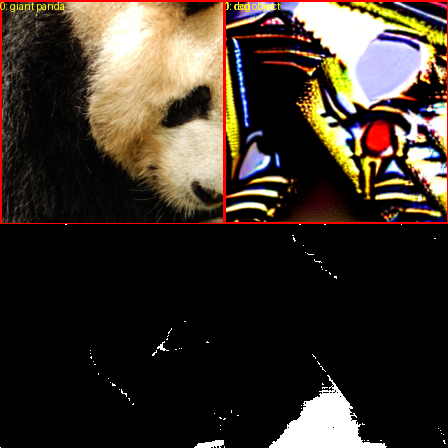

In [17]:
# Regional correspondence review: generated target, boxes, masks and assignments.
if RUN_DIR is not None and (Path(RUN_DIR) / 'regions').is_dir():
    from IPython.display import display
    region_files = sorted((Path(RUN_DIR) / 'regions').glob('*/regions.json'))
    if region_files:
        path = region_files[0]
        record = json.loads(path.read_text(encoding='utf-8'))
        print('Sample:', path.parent.name)
        for match in record['matches']:
            src = record['roles']['source']['objects'][match['source_index']]['concept']
            tgt = (record['roles']['target']['objects'][match['target_index']]['concept']
                   if match['target_index'] is not None else match['kind'])
            print(f'{src} => {tgt}: IoU={match["iou"]:.3f}, kind={match["kind"]}')
        print('Unlocalized:', {r: record['roles'][r]['unlocalized'] for r in ('source', 'target')})
        panel = Image.new('RGB', (INPUT_RES * 2, INPUT_RES * 2))
        for i, name in enumerate(('source_boxes.png', 'target_boxes.png',
                                  'source_background.png', 'target_background.png')):
            with Image.open(path.parent / name) as image:
                panel.paste(image.convert('RGB'), ((i % 2) * INPUT_RES, (i // 2) * INPUT_RES))
        display(panel)
